# Predicting Students' Adaptivity to Online Education
## Main Study: EDA, Classification Model Comparison, and Optuna

- **Purpose:** Analyze students' backgrounds and online learning environments, and compare classification models for predicting their adaptivity levels.
- **Rationale:** Identify features associated with adaptivity and establish a complete-data performance baseline for the missing-data experiments.
- **Key points:** Conduct EDA and feature importance analysis on the training data, select models through cross-validation, and evaluate the final model on the test data.

## Supplementary Study: All13, Importance-Based Top5, and Repeated Evaluation

- **Purpose:** Compare prediction models on complete data and assess how missing-value imputation affects reconstruction and classification performance.
- **Rationale:** Examine both baseline predictive performance and resilience to data corruption.
- **Key point 1:** Introduce missing values into all 13 features and, separately, the five most important features. Compare mode and DNN imputation in terms of reconstruction accuracy and classification performance.
- **Key point 2:** Repeat the experiments across missingness rates and random masks. With the total number of missing cells held constant, examine performance differences associated with which features are affected and how concentrated the missingness is.


In [ ]:
# Uncomment if needed, then restart the kernel.
# %pip install numpy pandas scipy scikit-learn matplotlib seaborn torch xgboost catboost optuna ipython

In [2]:
import os, sys, json, random, time, platform, warnings
# Set the loky CPU limit to avoid Windows wmic-based physical-core detection.
os.environ["LOKY_MAX_CPU_COUNT"] = "2"
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.base import clone
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GroupShuffleSplit, StratifiedGroupKFold)
from sklearn.linear_model import LogisticRegression, RidgeClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import torch
from torch import nn
import optuna
from IPython.display import display, Markdown

SEED = 42
N_TRIALS = 12                 # 12 trials x 5 folds per model; this limited search does not guarantee an optimum.
CV_FOLDS = 5
MASK_SEEDS = [42, 43, 44, 45, 46]
MISSING_RATES = [0.05, 0.15, 0.30]
DNN_EPOCHS, DNN_PATIENCE = 160, 18
BOOTSTRAPS = 1000
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
warnings.filterwarnings('ignore', category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':160})
pd.set_option('display.max_columns', 30)
RESULTS = Path.cwd()/'experiment_results'
FIGURES = RESULTS/'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
versions = {p: __import__(p).__version__ for p in
            ['numpy','pandas','scipy','sklearn','matplotlib','seaborn','torch','xgboost','catboost','optuna']}
print('Python:', sys.version.split()[0], 'CPU:', platform.processor())
display(pd.Series(versions, name='version').to_frame())
def savefig(name,extra_artists=None):
    plt.tight_layout()
    plt.savefig(FIGURES/f'{name}.png', bbox_inches='tight',bbox_extra_artists=extra_artists)
    plt.show()
    plt.close()  # Display and close each figure independently.

def chart_slug(text):
    return ''.join(ch.lower() if ch.isalnum() else '_' for ch in str(text)).strip('_')

def category_colors(column, values):
    return [CATEGORY_COLORS[column][str(v)] for v in values]


Python: 3.13.2 CPU: Intel64 Family 6 Model 142 Stepping 12, GenuineIntel


,version
numpy,2.3.1
pandas,2.3.1
scipy,1.16.2
sklearn,1.7.2
matplotlib,3.10.5
seaborn,0.13.2
torch,2.10.0+cpu
xgboost,3.0.5
catboost,1.2.8
optuna,4.5.0


## 1. Data Audit

- **Purpose:** Inspect the data structure, missing values, duplicates, and target distribution.
- **Rationale:** Identify data characteristics that may affect model evaluation before modeling.
- **Key points:** The dataset has 1,205 rows, 13 input features, three target classes, and no missing values. It contains 236 unique input profiles, motivating an additional profile-group validation.


In [3]:
DATA_PATH = Path('students_adaptability_level_online_education.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Place the notebook and CSV in the same folder: '+str(DATA_PATH.resolve()))
df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
df.columns = df.columns.str.strip()
for c in df.columns:
    df[c] = df[c].astype('string').str.strip().replace('', pd.NA)
TARGET = 'Adaptivity Level'
FEATURES = df.columns.drop(TARGET).tolist()
assert TARGET in df and df.shape == (1205,14)
assert df.isna().sum().sum() == 0, 'This experiment requires the supplied complete dataset.'
assert set(df[TARGET]) == {'Low','Moderate','High'}
X, y_text = df[FEATURES].astype(str), df[TARGET].astype(str)
label_encoder = LabelEncoder().fit(y_text)
y = pd.Series(label_encoder.transform(y_text), index=df.index, name=TARGET)
profile_id = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X))[0], index=X.index)
audit = pd.DataFrame({'dtype':df.dtypes.astype(str), 'missing':df.isna().sum(),
                      'n_categories':df.nunique()})
display(df.head()); display(audit)
print('Rows / features:', len(df), len(FEATURES))
print('Repeated full rows beyond first:', df.duplicated().sum())
print('Unique feature profiles:', profile_id.nunique())
print('Profiles with conflicting labels:', (df.groupby(FEATURES)[TARGET].nunique()>1).sum())
display(y_text.value_counts().to_frame('count').assign(percent=lambda z:100*z['count']/len(df)))
audit.to_csv(RESULTS/'data_audit.csv', encoding='utf-8-sig')
train_idx, test_idx = train_test_split(df.index.to_numpy(), test_size=.30,
                                     stratify=y, random_state=SEED)
X_train, X_test = X.loc[train_idx].copy(), X.loc[test_idx].copy()
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
overlap = len(set(profile_id.loc[train_idx]) & set(profile_id.loc[test_idx]))
print('Train / test:', len(train_idx), len(test_idx), 'Shared feature profiles:', overlap)
pd.DataFrame({'row_id':df.index, 'split':np.where(df.index.isin(train_idx),'train','test'),
              'profile_group':profile_id}).to_csv(RESULTS/'split_manifest.csv',index=False)


Rows / features: 1205 13
Repeated full rows beyond first: 949
Unique feature profiles: 236
Profiles with conflicting labels: 19
Train / test: 843 362 Shared feature profiles: 151


,Gender,Age,Education Level,Institution Type,IT Student,Location,Load-shedding,Financial Condition,Internet Type,Network Type,Class Duration,Self Lms,Device,Adaptivity Level
0,Boy,21-25,University,Non Government,No,Yes,Low,Mid,Wifi,4G,3-6,No,Tab,Moderate
1,Girl,21-25,University,Non Government,No,Yes,High,Mid,Mobile Data,4G,1-3,Yes,Mobile,Moderate
2,Girl,16-20,College,Government,No,Yes,Low,Mid,Wifi,4G,1-3,No,Mobile,Moderate
3,Girl,11-15,School,Non Government,No,Yes,Low,Mid,Mobile Data,4G,1-3,No,Mobile,Moderate
4,Girl,16-20,School,Non Government,No,Yes,Low,Poor,Mobile Data,3G,0,No,Mobile,Low


,dtype,missing,n_categories
Gender,string,0,2
Age,string,0,6
Education Level,string,0,3
Institution Type,string,0,2
IT Student,string,0,2
Location,string,0,2
Load-shedding,string,0,2
Financial Condition,string,0,3
Internet Type,string,0,2
Network Type,string,0,3


,count,percent
Adaptivity Level,,
Moderate,625,51.867220
Low,480,39.834025
High,100,8.298755


,feature,category,hex_color,alpha
0,Age,1-5,#e27878,1.0
1,Age,6-10,#e78d8d,1.0
2,Age,11-15,#eba1a1,1.0
3,Age,16-20,#f0b6b6,1.0
4,Age,21-25,#f4cbcb,1.0
5,Age,26-30,#f8e0e0,1.0
6,Adaptivity Level,High,#122747,1.0
7,Adaptivity Level,Low,#CBD7E6,1.0
8,Adaptivity Level,Moderate,#607DA5,1.0
9,Class Duration,0,#3e69be,1.0


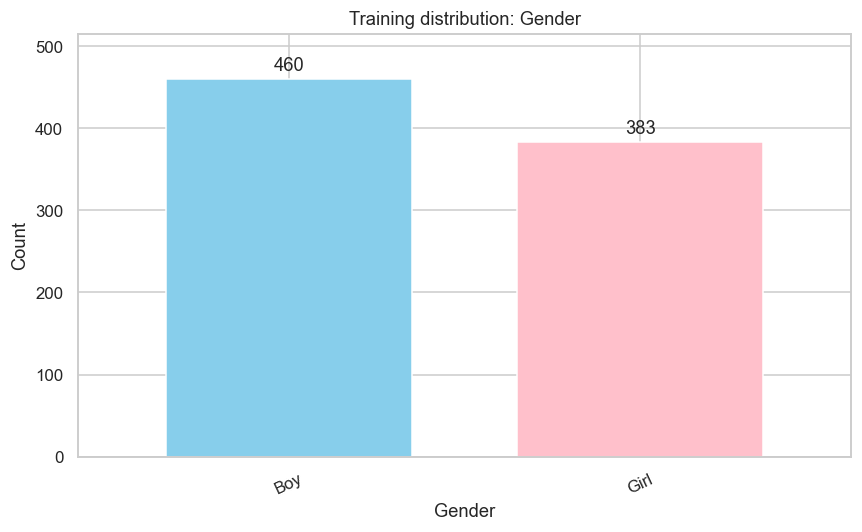

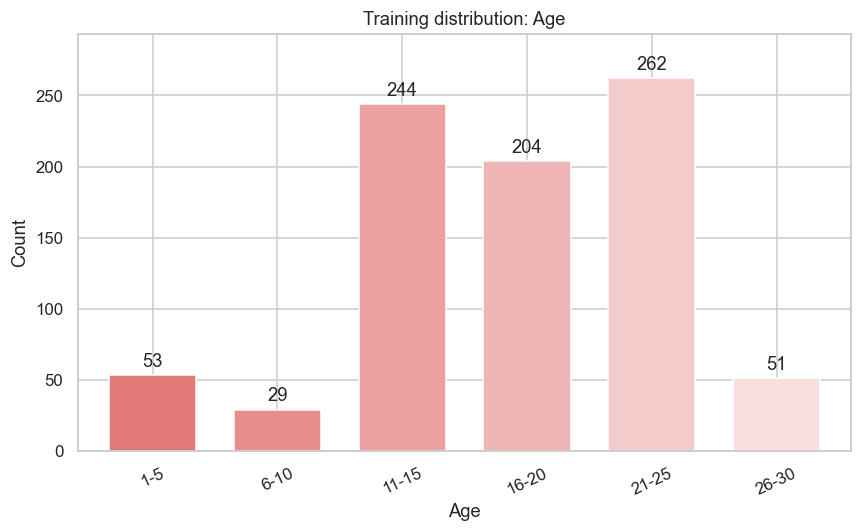

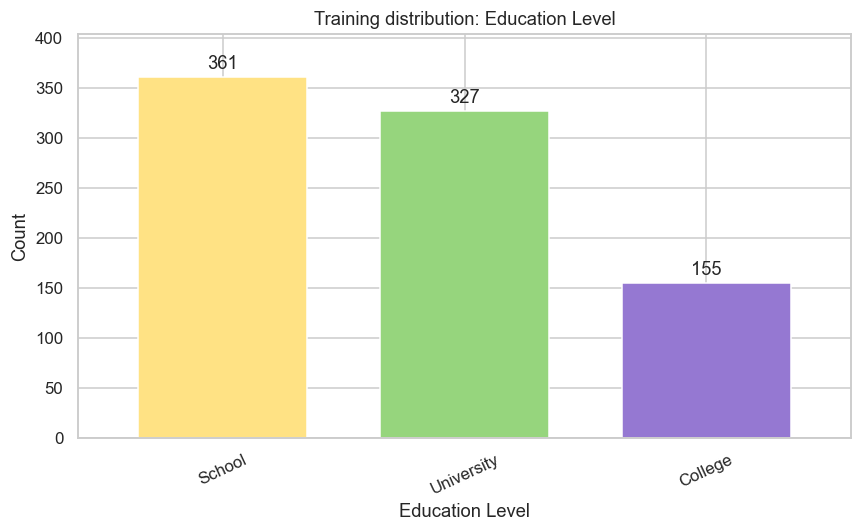

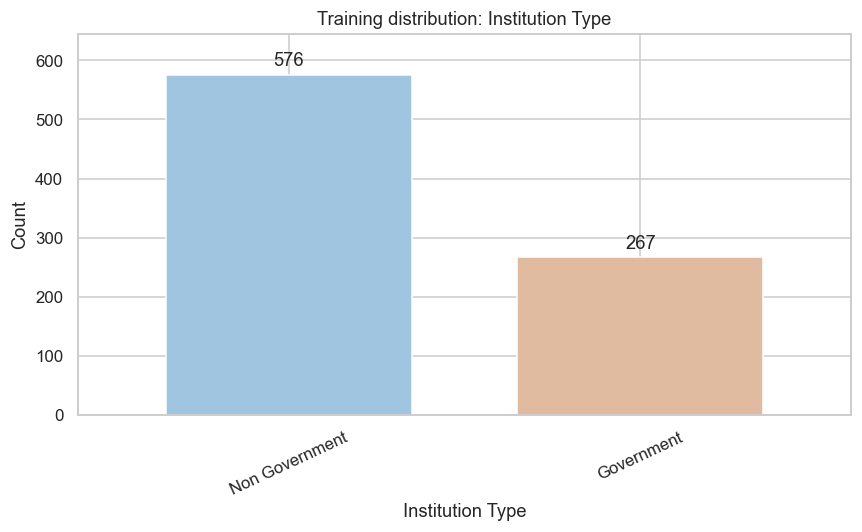

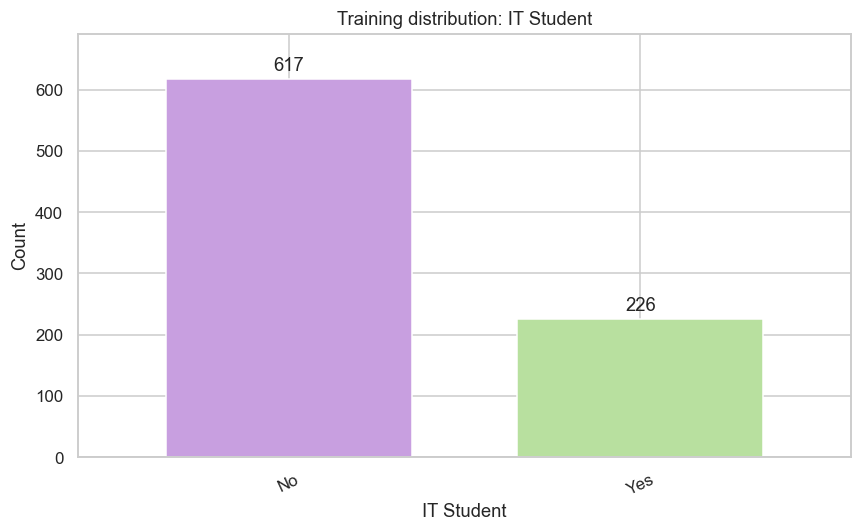

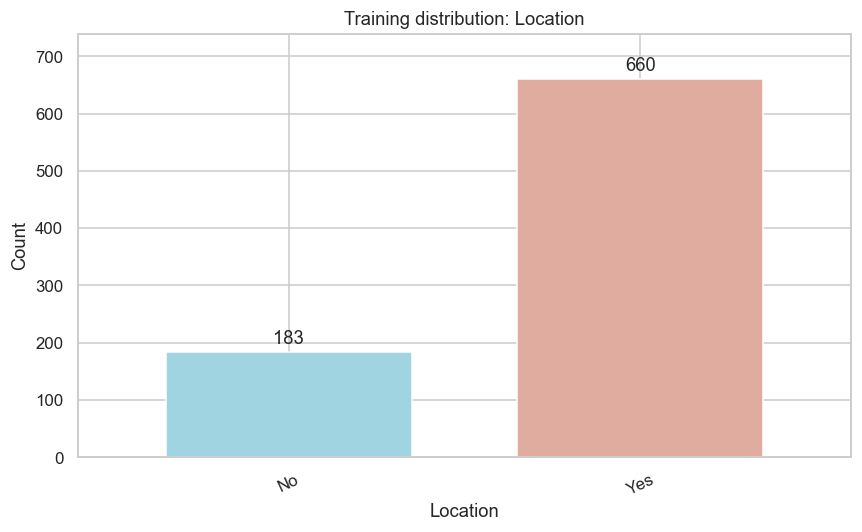

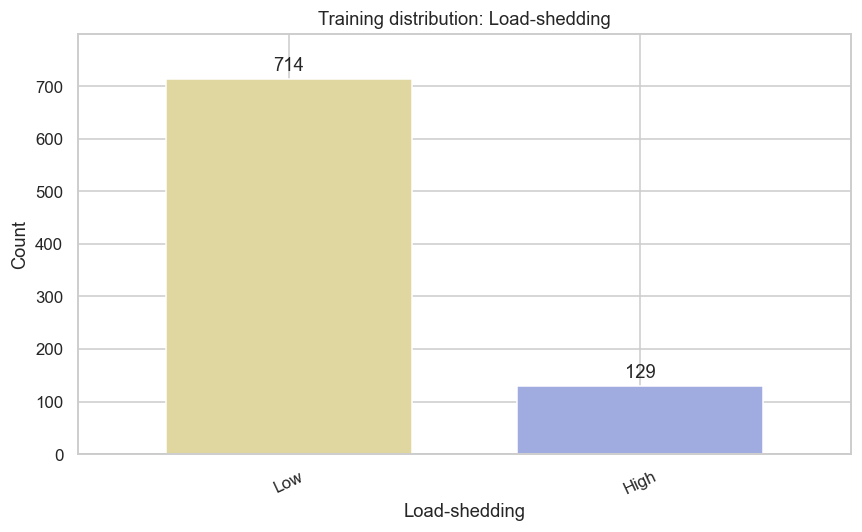

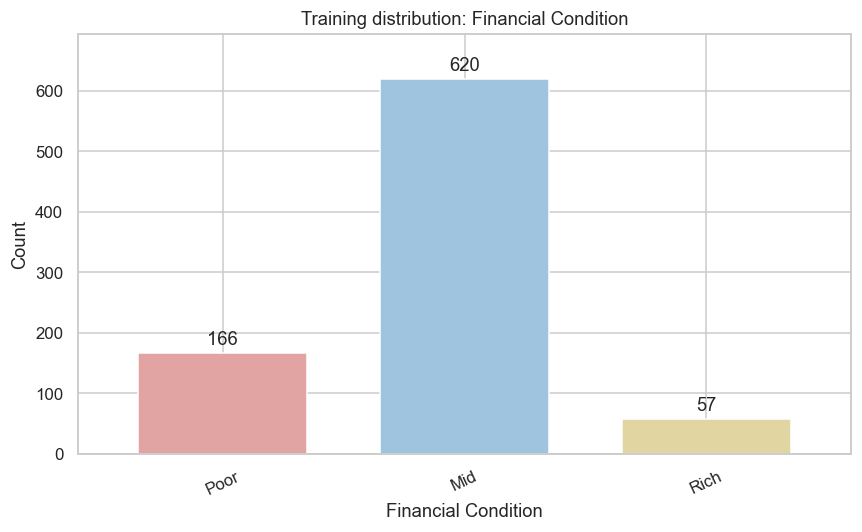

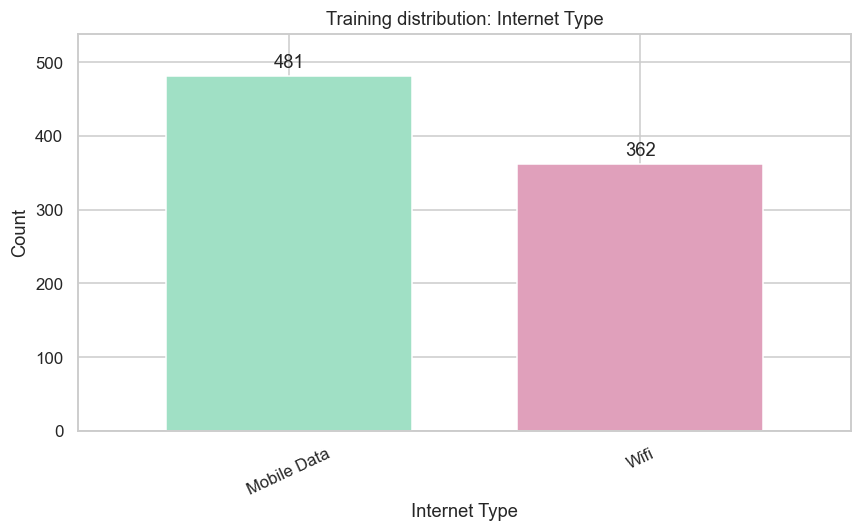

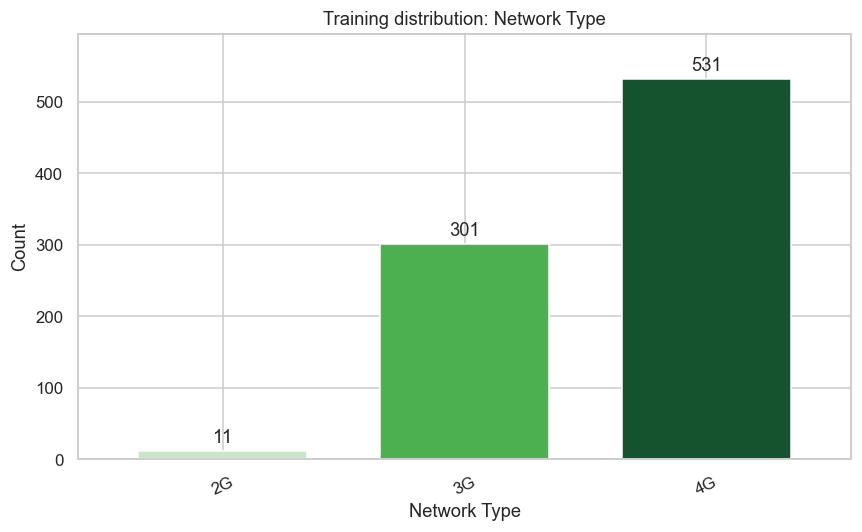

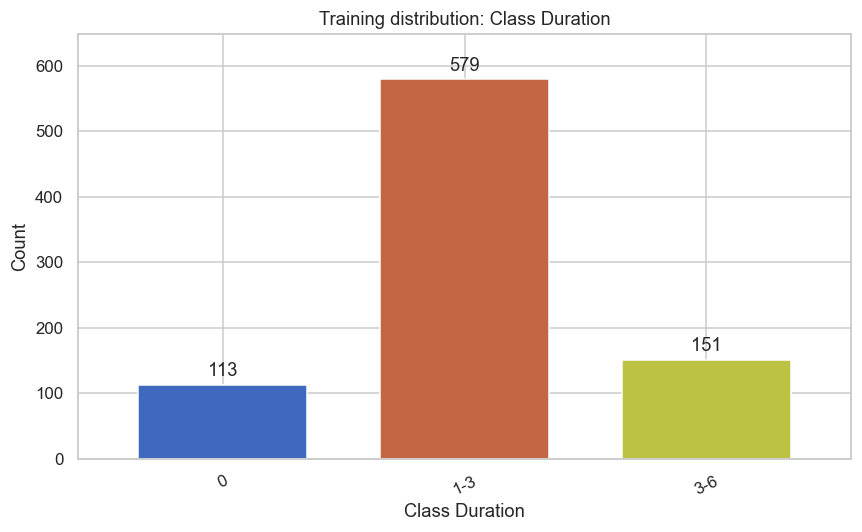

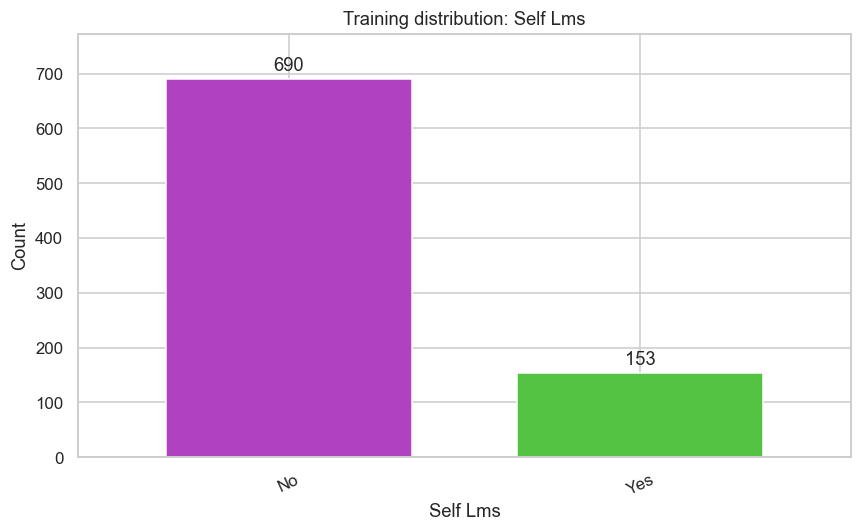

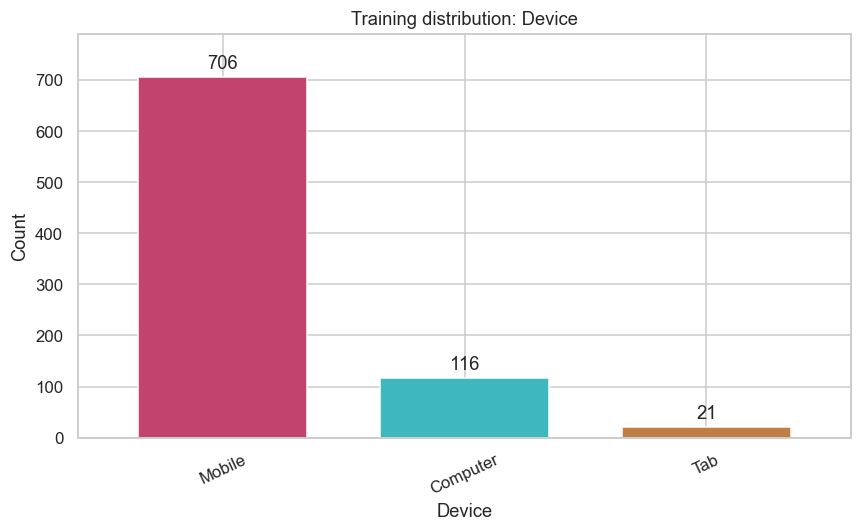

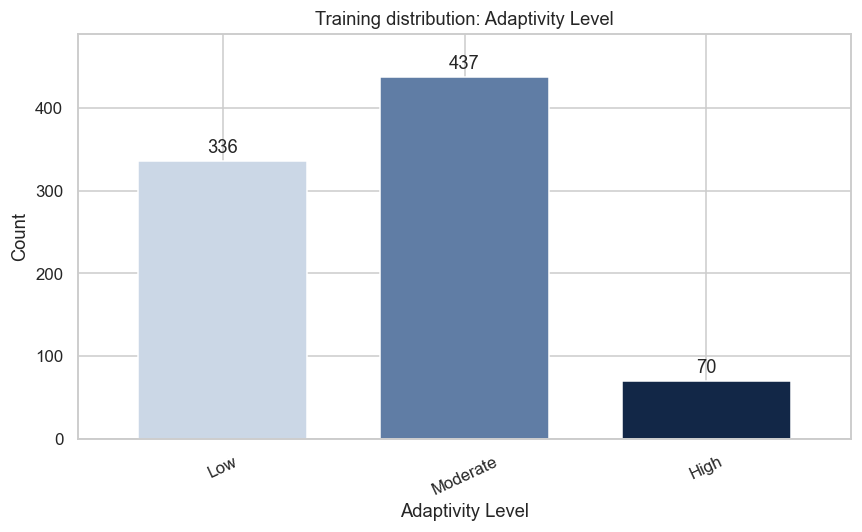

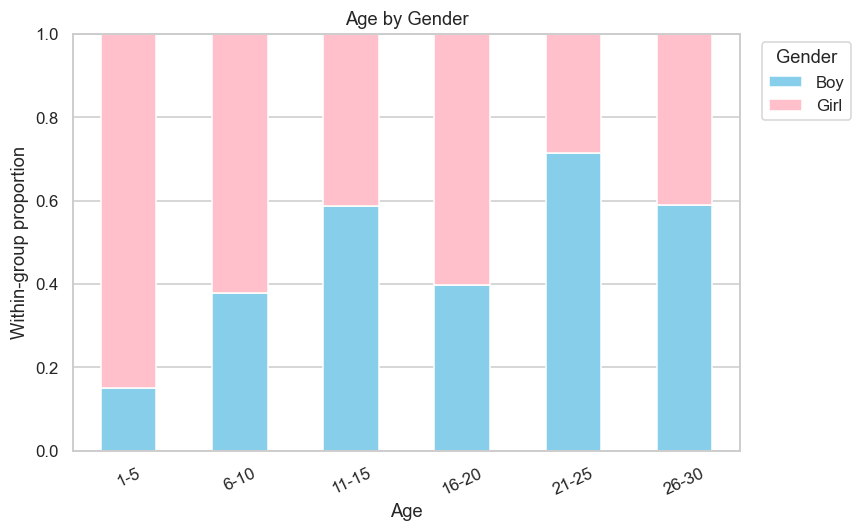

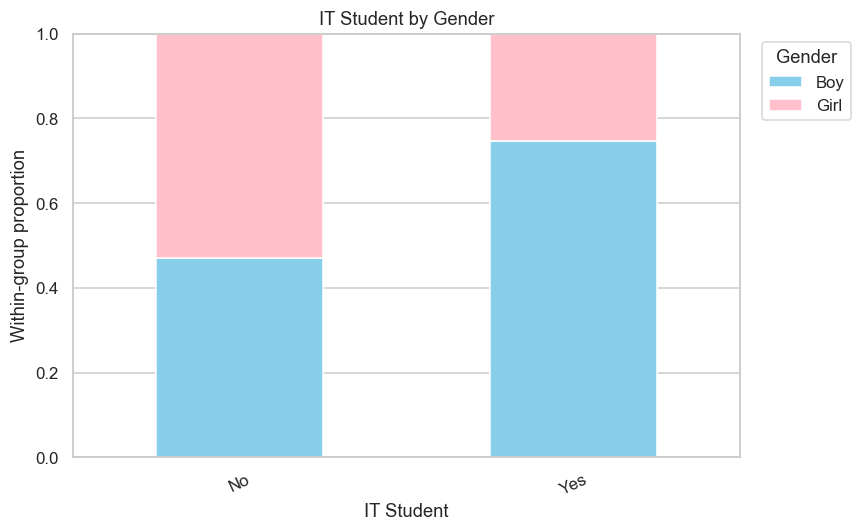

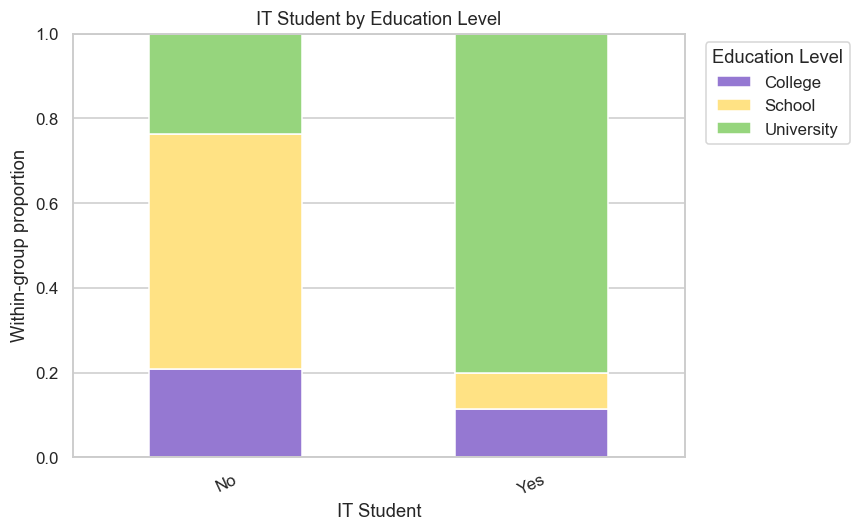

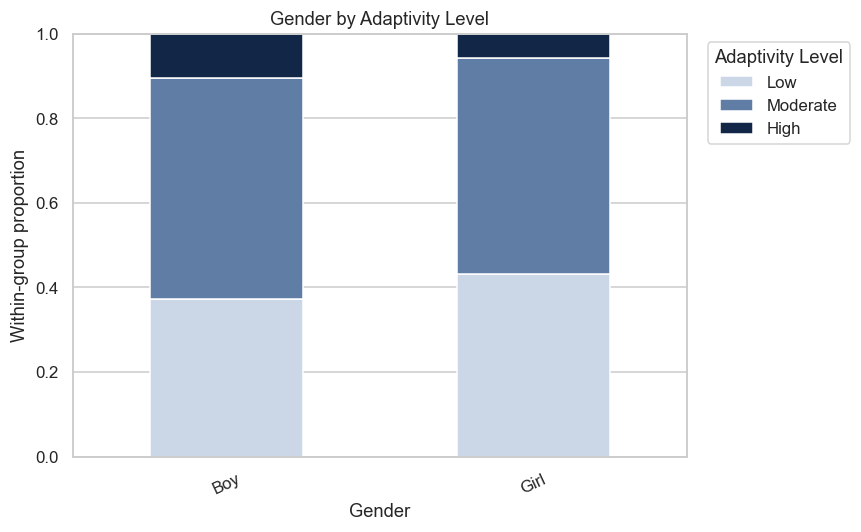

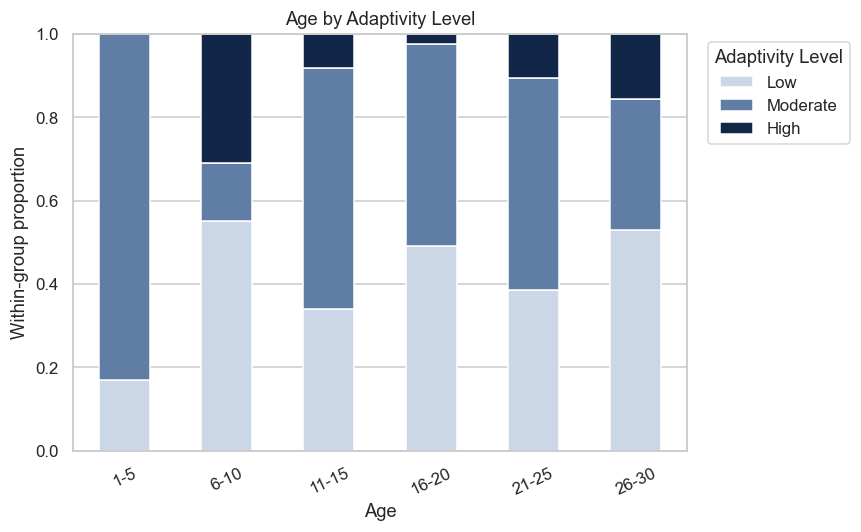

In [ ]:
eda = df.loc[train_idx]
import colorsys
from matplotlib.colors import to_hex

def make_global_palette(groups):
    # Use complementary or split-complementary hues with coordinated saturation and lightness.
    bases={'Age':.59,'Gender':.48,'Education Level':.72,'Institution Type':.07,
           'IT Student':.77,'Location':.53,'Load-shedding':.64,'Financial Condition':.57,
           'Internet Type':.43,'Network Type':.67,'Class Duration':.61,'Self Lms':.81,
           'Device':.51,'Adaptivity Level':.69,'__cv_metric__':.56,'__learning_curve__':.73}
    result={}; used=set()
    for group_index,(feature,values) in enumerate(groups):
        values=list(values)
        if feature=='Age': values=sorted(values,key=lambda v:int(v.split('-')[0]))
        base=bases.get(feature,.58)
        n=len(values)
        if n==2:
            hues=[base,base+.5]; lights=[.49,.49]
        elif n==3:
            # Split-complementary scheme: a base hue and two neighbors of its complement.
            hues=[base,base+.5-.065,base+.5+.065]; lights=[.49,.51,.51]
        else:
            # For more categories, vary lightness within two complementary hue families.
            half=(n+1)//2
            hues=[base if j<half else base+.5 for j in range(n)]
            lights=list(np.linspace(.34,.66,half))+list(np.linspace(.34,.66,n-half))
        for j,value in enumerate(values):
            hue=hues[j]%1; light=float(lights[j])
            if feature=='__condition__':
                # Use a neutral baseline and complementary blue/orange imputation colors.
                hue=[.61,.58,.08][j]; light=[.44,.49,.49][j]
            saturation=.16 if feature=='__condition__' and j==0 else .51
            # Avoid duplicate HEX codes with small lightness adjustments.
            light+=.0015*group_index
            color=to_hex(colorsys.hls_to_rgb(hue,light,saturation))
            while color in used:
                light+=.003
                color=to_hex(colorsys.hls_to_rgb(hue,light,saturation))
            used.add(color); result[(feature,str(value))]=color
    assert len(result)==len(set(result.values()))
    return result

feature_groups=[(col,sorted(eda[col].astype(str).unique())) for col in df.columns]
# Allocate colors to larger category sets first.
feature_groups=sorted(feature_groups,key=lambda pair:(-len(pair[1]),pair[0]))
series_groups=[('__condition__',['Complete','Mode','DNN']),
               ('__cv_metric__',['cv_accuracy','cv_macro_f1']),
               ('__learning_curve__',['Train','Validation'])]
GLOBAL_COLORS=make_global_palette(feature_groups+series_groups)


# Keep bars opaque (alpha=1); create pastel colors by blending RGB values toward white.
from matplotlib.colors import to_rgba,to_rgb
def pastel_color(color,strength):
    rgb=np.array(to_rgb(color))
    return to_hex(strength*rgb+(1-strength)*np.ones(3))
AGE_ORDER=sorted(eda['Age'].astype(str).unique(),key=lambda value:int(value.split('-')[0]))
NETWORK_ORDER=['2G','3G','4G']
ADAPTIVITY_ORDER=['Low','Moderate','High']
CATEGORY_ORDERS={'Age':AGE_ORDER,'Institution Type':['Non Government','Government'],
                 'Financial Condition':['Poor','Mid','Rich'],'Network Type':NETWORK_ORDER,
                 'Class Duration':['0','1-3','3-6'],TARGET:ADAPTIVITY_ORDER}
def visual_order(feature,values):
    values=list(values)
    if feature in CATEGORY_ORDERS:
        requested=CATEGORY_ORDERS[feature]
    elif {str(v).lower() for v in values}=={'no','yes'}:
        requested=sorted(values,key=lambda value:0 if str(value).lower()=='no' else 1)
    else:return values
    return [v for v in requested if v in values]+[v for v in values if v not in requested]
CATEGORY_ALPHA={col:{str(v):1.0 for v in values} for col,values in feature_groups}
GLOBAL_COLORS[('Gender','Boy')]='#87CEEB'
GLOBAL_COLORS[('Gender','Girl')]='#FFC0CB'
# In ascending age order, use equally spaced red-to-pastel color strengths.
for value,strength in zip(AGE_ORDER,np.linspace(.65,.15,len(AGE_ORDER))):
    GLOBAL_COLORS[('Age',value)]=pastel_color('#D32F2F',float(strength))
GLOBAL_COLORS[('Education Level','School')]='#FFD54F'
for value in CATEGORY_ALPHA['Education Level']:
    GLOBAL_COLORS[('Education Level',value)]=pastel_color(GLOBAL_COLORS[('Education Level',value)],.7)
pastel_columns=FEATURES[FEATURES.index('Institution Type'):FEATURES.index('Internet Type')+1]
for col in pastel_columns:
    for value in CATEGORY_ALPHA[col]:
        GLOBAL_COLORS[(col,value)]=pastel_color(GLOBAL_COLORS[(col,value)],.5)
for value,color in zip(NETWORK_ORDER,['#C8E6C9','#4CAF50','#14532D']):
    GLOBAL_COLORS[('Network Type',value)]=color
for value,color in zip(ADAPTIVITY_ORDER,['#CBD7E6','#607DA5','#122747']):
    GLOBAL_COLORS[(TARGET,value)]=color
CATEGORY_COLORS={col:{str(value):to_rgba(GLOBAL_COLORS[(col,str(value))],
                                      CATEGORY_ALPHA[col][str(value)]) for value in values}
                 for col,values in feature_groups}
CONDITION_COLORS={v:GLOBAL_COLORS[('__condition__',v)] for v in ['Complete','Mode','DNN']}
CV_METRIC_COLORS={v:GLOBAL_COLORS[('__cv_metric__',v)] for v in ['cv_accuracy','cv_macro_f1']}
LEARNING_COLORS={v:GLOBAL_COLORS[('__learning_curve__',v)] for v in ['Train','Validation']}
color_key=pd.DataFrame([{'feature':feature,'category':category,'hex_color':color,
                        'alpha':CATEGORY_ALPHA.get(feature,{}).get(category,1.0)}
                       for (feature,category),color in GLOBAL_COLORS.items()])
# Pastel RGB colors are used directly, so every alpha value remains 1.
assert (color_key['alpha']==1.0).all()
assert not color_key.duplicated(['hex_color','alpha']).any()
color_key.to_csv(RESULTS/'category_color_key.csv',index=False,encoding='utf-8-sig')
(RESULTS/'category_color_key.json').write_text(json.dumps(
    {feature:{row.category:{'color':row.hex_color,'alpha':row.alpha} for row in z.itertuples()}
     for feature,z in color_key.groupby('feature')},ensure_ascii=False,indent=2),encoding='utf-8')
display(color_key[~color_key.feature.str.startswith('__')])
for c in df.columns:
    counts=eda[c].value_counts()
    counts=counts.reindex(visual_order(c,counts.index))
    fig,ax=plt.subplots(figsize=(8,5))
    counts.plot.bar(ax=ax,color=category_colors(c,counts.index),edgecolor='white',width=.7)
    ax.set(title=f'Training distribution: {c}',xlabel=c,ylabel='Count')
    ax.tick_params(axis='x',rotation=25)
    ax.bar_label(ax.containers[0],padding=3)
    ax.margins(y=.12)
    savefig(f'01_univariate_{chart_slug(c)}')

# Create a separate figure for each bivariate relationship.
pairs=[('Age','Gender'),('IT Student','Gender'),('IT Student','Education Level'),
       ('Gender',TARGET),('Age',TARGET)]
for a,b in pairs:
    table=pd.crosstab(eda[a],eda[b],normalize='index')
    table=table.reindex(index=visual_order(a,table.index),columns=visual_order(b,table.columns))
    fig,ax=plt.subplots(figsize=(8,5))
    table.plot.bar(stacked=True,ax=ax,color=category_colors(b,table.columns),edgecolor='white')
    ax.set(title=f'{a} by {b}',xlabel=a,ylabel='Within-group proportion',ylim=(0,1))
    ax.tick_params(axis='x',rotation=25)
    ax.legend(title=b,bbox_to_anchor=(1.02,1),loc='upper left')
    savefig(f'02_bivariate_{chart_slug(a)}_by_{chart_slug(b)}')


,feature,Cramers_V
10,Class Duration,0.311482
7,Financial Condition,0.299604
3,Institution Type,0.264338
5,Location,0.239507
1,Age,0.200563
11,Self Lms,0.158870
12,Device,0.135509
2,Education Level,0.111586
8,Internet Type,0.110902
4,IT Student,0.109716


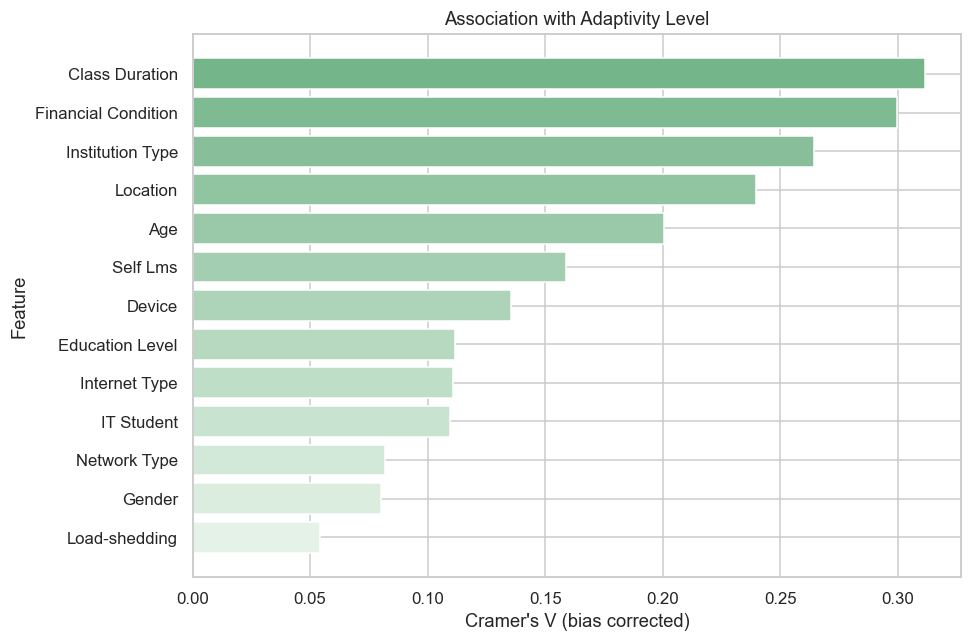

In [5]:
# Bias-corrected Cramer's V measures categorical association, not causality or feature significance.
def cramers_v(a,b):
    tab=pd.crosstab(a,b); n=tab.to_numpy().sum(); r,k=tab.shape
    if n<=1 or min(r,k)<=1: return 0.0
    chi2=chi2_contingency(tab, correction=False)[0]
    phi=max(0,chi2/n-(k-1)*(r-1)/(n-1))
    denom=min(k-(k-1)**2/(n-1)-1,r-(r-1)**2/(n-1)-1)
    return float(np.sqrt(phi/denom)) if denom>0 else 0.0
assoc=pd.DataFrame({'feature':FEATURES,'Cramers_V':[cramers_v(eda[c],eda[TARGET]) for c in FEATURES]})
display(assoc.sort_values('Cramers_V',ascending=False))
# Sort associations from highest to lowest and fade the green colors from top to bottom.
association_plot=assoc.sort_values('Cramers_V',ascending=False)
green_start=np.array([0x75,0xB5,0x8A])/255  # Darker pastel green.
green_end=np.array([0xE4,0xF2,0xE7])/255    # Lighter pastel green.
green_colors=np.linspace(green_start,green_end,len(association_plot))
fig,ax=plt.subplots(figsize=(9,6))
ax.barh(association_plot['feature'],association_plot['Cramers_V'],
        color=green_colors,edgecolor='white',alpha=1)
ax.invert_yaxis()
ax.set(xlabel="Cramer's V (bias corrected)",ylabel='Feature',
       title='Association with Adaptivity Level')
savefig('03_association_train')
assoc.to_csv(RESULTS/'categorical_association.csv',index=False)


## 2. Preprocessing and Model Comparison

- **Purpose:** Compare baseline classification models using the same five-fold cross-validation splits.
- **Rationale:** Establish a suitable baseline without relying on a single split.
- **Key points:** Fit encoders within each fold. Select models using macro-F1 to account for class imbalance, and also report accuracy and balanced accuracy.


In [6]:
def onehot():
    return OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=np.float32)
def make_pipe(model, scaled=False):
    steps=[('encode',onehot())]
    if scaled: steps.append(('scale',StandardScaler()))
    return Pipeline(steps+[('model',model)])
cv=StratifiedKFold(CV_FOLDS,shuffle=True,random_state=SEED)
cv_splits=list(cv.split(X_train,y_train))
SCORING={'accuracy':'accuracy','macro_f1':'f1_macro','balanced_accuracy':'balanced_accuracy'}
models={
    'Dummy':make_pipe(DummyClassifier(strategy='most_frequent')),
    'LogisticRegression':make_pipe(LogisticRegression(max_iter=2000,random_state=SEED),True),
    'KNN':make_pipe(KNeighborsClassifier(n_neighbors=5),True),
    'RandomForest':make_pipe(RandomForestClassifier(n_estimators=200,random_state=SEED,n_jobs=1)),
    'XGBoost':make_pipe(XGBClassifier(n_estimators=150,max_depth=4,learning_rate=.1,
                       objective='multi:softprob',eval_metric='mlogloss',random_state=SEED,n_jobs=2)),
    'CatBoost':make_pipe(CatBoostClassifier(iterations=150,depth=5,learning_rate=.1,
                         loss_function='MultiClass',verbose=False,allow_writing_files=False,
                         random_seed=SEED,thread_count=2)),
}
cv_rows=[]
for name,pipe in models.items():
    scores=cross_validate(pipe,X_train,y_train,cv=cv_splits,scoring=SCORING,n_jobs=1)
    for fold in range(CV_FOLDS):
        cv_rows.append({'model':name,'fold':fold+1,**{k:float(scores['test_'+k][fold]) for k in SCORING}})
    print(name, 'CV macro-F1:',round(scores['test_macro_f1'].mean(),4),flush=True)
cv_details=pd.DataFrame(cv_rows)
cv_summary=cv_details.groupby('model')[list(SCORING)].agg(['mean','std'])
display(cv_summary.sort_values(('macro_f1','mean'),ascending=False))
cv_details.to_csv(RESULTS/'baseline_cv_folds.csv',index=False)

ridge=make_pipe(RidgeClassifierCV(alphas=[.1,1,10,100]))
ridge.fit(X_train,y_train)
ridge_ohe=ridge.named_steps['encode']
weights=np.abs(ridge.named_steps['model'].coef_).mean(axis=0)
start=0; ridge_rows=[]
for c,cats in zip(FEATURES,ridge_ohe.categories_):
    ridge_rows.append({'feature':c,'mean_abs_coefficient':float(weights[start:start+len(cats)].mean())})
    start+=len(cats)
display(pd.DataFrame(ridge_rows).sort_values('mean_abs_coefficient',ascending=False))


Dummy CV macro-F1: 0.2276
LogisticRegression CV macro-F1: 0.6471
KNN CV macro-F1: 0.703
RandomForest CV macro-F1: 0.8459
XGBoost CV macro-F1: 0.7729
CatBoost CV macro-F1: 0.7679


accuracy            macro_f1           balanced_accuracy  \
                        mean       std      mean       std              mean   
model                                                                          
RandomForest        0.878994  0.019566  0.845942  0.029977          0.830331   
XGBoost             0.835130  0.015132  0.772916  0.046545          0.744965   
CatBoost            0.824401  0.019438  0.767860  0.020162          0.736890   
KNN                 0.762708  0.048314  0.703022  0.046109          0.692857   
LogisticRegression  0.718864  0.037758  0.647066  0.053953          0.624806   
Dummy               0.518385  0.002463  0.227603  0.000713          0.333333   

                              
                         std  
model                         
RandomForest        0.029135  
XGBoost             0.052378  
CatBoost            0.024115  
KNN                 0.023787  
LogisticRegression  0.058680  
Dummy               0.000000

,feature,mean_abs_coefficient
10,Class Duration,0.316053
7,Financial Condition,0.235064
11,Self Lms,0.134530
1,Age,0.130335
12,Device,0.122611
9,Network Type,0.121930
8,Internet Type,0.114651
2,Education Level,0.104422
3,Institution Type,0.073677
4,IT Student,0.049736


## 3. Optuna Hyperparameter Tuning

- **Purpose:** Tune XGBoost and CatBoost with 12 trials each and evaluate them on an independent test set.
- **Rationale:** Assess both the effect of tuning and the models' predictive performance.
- **Key points:** Use the same CV folds. Tuned CV scores may be affected by selection bias; do not use test results for further tuning.


In [7]:
studies={}; tuned_params={}
def objective(trial,kind):
    if kind=='XGBoost':
        model=XGBClassifier(
            n_estimators=trial.suggest_int('n_estimators',100,350,step=50),
            max_depth=trial.suggest_int('max_depth',2,7),
            learning_rate=trial.suggest_float('learning_rate',.025,.25,log=True),
            min_child_weight=trial.suggest_int('min_child_weight',1,6),
            subsample=trial.suggest_float('subsample',.7,1),
            colsample_bytree=trial.suggest_float('colsample_bytree',.6,1),
            reg_lambda=trial.suggest_float('reg_lambda',.1,10,log=True),
            objective='multi:softprob',eval_metric='mlogloss',random_state=SEED,n_jobs=2)
    else:
        model=CatBoostClassifier(
            iterations=trial.suggest_int('iterations',100,350,step=50),
            depth=trial.suggest_int('depth',3,7),
            learning_rate=trial.suggest_float('learning_rate',.025,.25,log=True),
            l2_leaf_reg=trial.suggest_float('l2_leaf_reg',1,10,log=True),
            random_strength=trial.suggest_float('random_strength',0,3),
            loss_function='MultiClass',verbose=False,allow_writing_files=False,
            random_seed=SEED,thread_count=2)
    pipe=make_pipe(model)
    return cross_validate(pipe,X_train,y_train,cv=cv_splits,scoring='f1_macro',n_jobs=1)['test_score'].mean()
for kind in ['XGBoost','CatBoost']:
    study=optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(lambda t:objective(t,kind),n_trials=N_TRIALS)
    studies[kind]=study; tuned_params[kind]=study.best_params
    tuned=clone(models[kind]); tuned.set_params(**{'model__'+k:v for k,v in study.best_params.items()})
    models[kind+'_tuned']=tuned
    scores=cross_validate(tuned,X_train,y_train,cv=cv_splits,scoring=SCORING,n_jobs=1)
    for fold in range(CV_FOLDS):
        cv_rows.append({'model':kind+'_tuned','fold':fold+1,
                       **{k:float(scores['test_'+k][fold]) for k in SCORING}})
    study.trials_dataframe().to_csv(RESULTS/(kind+'_optuna_trials.csv'),index=False)
    print(kind,'best CV macro-F1:',round(study.best_value,4),'params:',study.best_params,flush=True)
cv_details=pd.DataFrame(cv_rows)
cv_ranking=cv_details.groupby('model').agg(cv_macro_f1=('macro_f1','mean'),cv_macro_f1_sd=('macro_f1','std'),
                                         cv_accuracy=('accuracy','mean')).sort_values('cv_macro_f1',ascending=False)
BEST_NAME=cv_ranking.index[0]  # Fix the selected model before inspecting test results.
display(cv_ranking); print('CV-selected model:',BEST_NAME)
cv_details.to_csv(RESULTS/'all_cv_folds.csv',index=False)
cv_ranking.to_csv(RESULTS/'cv_ranking.csv')
(RESULTS/'tuned_parameters.json').write_text(json.dumps(tuned_params,indent=2),encoding='utf-8')


XGBoost best CV macro-F1: 0.8465 params: {'n_estimators': 350, 'max_depth': 5, 'learning_rate': 0.24854525902849853, 'min_child_weight': 1, 'subsample': 0.8997407617480316, 'colsample_bytree': 0.9866214592657088, 'reg_lambda': 0.13694334760073867}
CatBoost best CV macro-F1: 0.8458 params: {'iterations': 350, 'depth': 7, 'learning_rate': 0.23306503231562004, 'l2_leaf_reg': 1.0705462068420808, 'random_strength': 1.9555996523345356}
CV-selected model: XGBoost_tuned
Out[7]: 438


,cv_macro_f1,cv_macro_f1_sd,cv_accuracy
model,,,
XGBoost_tuned,0.846481,0.034825,0.887292
RandomForest,0.845942,0.029977,0.878994
CatBoost_tuned,0.845835,0.031539,0.881354
XGBoost,0.772916,0.046545,0.835130
CatBoost,0.767860,0.020162,0.824401
KNN,0.703022,0.046109,0.762708
LogisticRegression,0.647066,0.053953,0.718864
Dummy,0.227603,0.000713,0.518385


              precision    recall  f1-score   support

        High       0.81      0.87      0.84        30
         Low       0.90      0.89      0.89       144
    Moderate       0.90      0.90      0.90       188

    accuracy                           0.89       362
   macro avg       0.87      0.88      0.88       362
weighted avg       0.89      0.89      0.89       362



,accuracy,macro_f1,balanced_accuracy
model,,,
XGBoost_tuned,0.892265,0.877343,0.884831
RandomForest,0.875691,0.871999,0.870942
CatBoost_tuned,0.883978,0.875621,0.860835
XGBoost,0.814917,0.792057,0.781994
CatBoost,0.828729,0.806202,0.793568
KNN,0.743094,0.695543,0.693666
LogisticRegression,0.707182,0.673347,0.660323
Dummy,0.519337,0.227879,0.333333


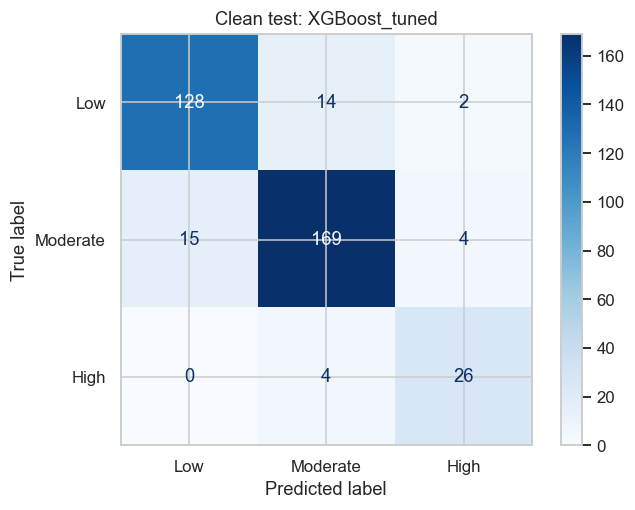

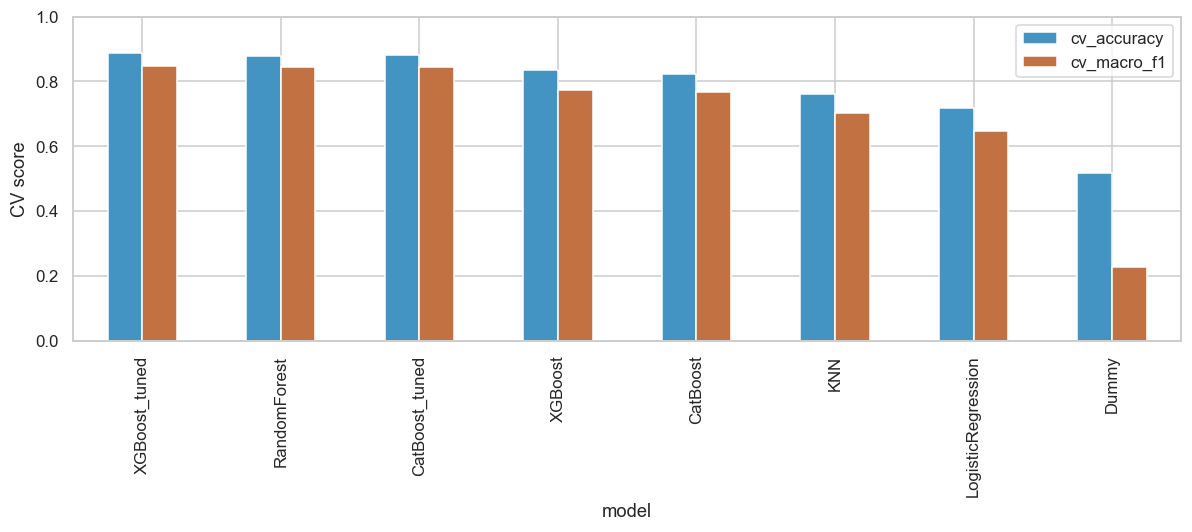

,feature,importance_mean,importance_sd
7,Financial Condition,0.135381,0.020106
1,Age,0.122558,0.018305
10,Class Duration,0.120926,0.008789
0,Gender,0.090239,0.027177
3,Institution Type,0.070154,0.016459
9,Network Type,0.067770,0.013676
11,Self Lms,0.059125,0.014032
12,Device,0.051563,0.008442
5,Location,0.039262,0.021399
2,Education Level,0.037187,0.023799


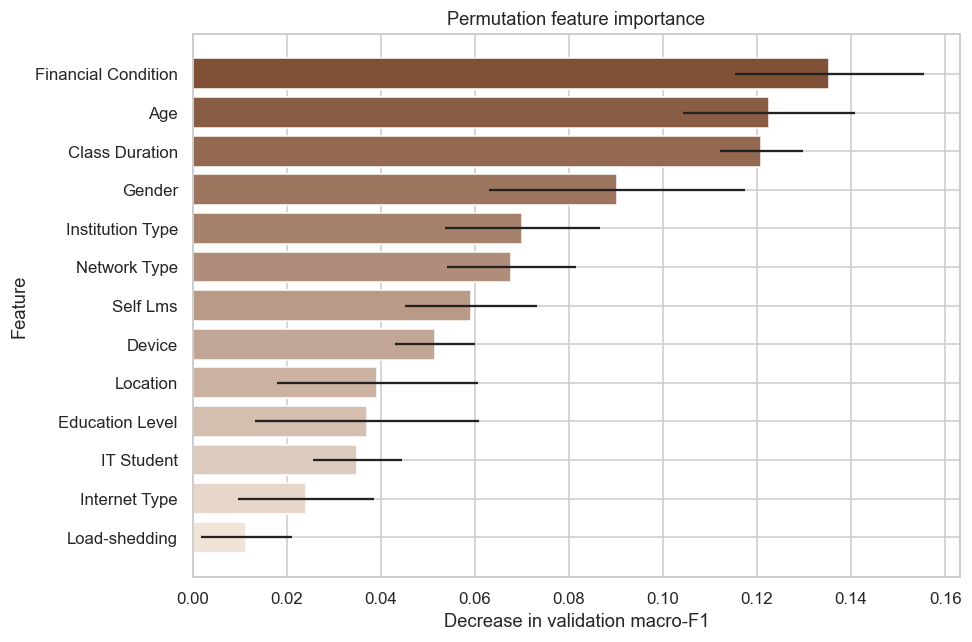

In [8]:
def metrics(yt,pred):
    return {'accuracy':accuracy_score(yt,pred), 'macro_f1':f1_score(yt,pred,average='macro',zero_division=0),
            'balanced_accuracy':balanced_accuracy_score(yt,pred)}
fitted_clean={}; clean_predictions={}; clean_rows=[]
for name,pipe in models.items():
    fitted_clean[name]=clone(pipe).fit(X_train,y_train)
    pred=fitted_clean[name].predict(X_test)
    clean_predictions[name]=pred
    clean_rows.append({'model':name,**metrics(y_test,pred)})
clean_results=pd.DataFrame(clean_rows).set_index('model')
display(clean_results.loc[cv_ranking.index])
clean_results.to_csv(RESULTS/'clean_test_scores.csv')
print(classification_report(y_test,clean_predictions[BEST_NAME],
                            labels=np.arange(len(label_encoder.classes_)),
                            target_names=label_encoder.classes_,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,clean_predictions[BEST_NAME],
                    labels=label_encoder.transform(ADAPTIVITY_ORDER),display_labels=ADAPTIVITY_ORDER,cmap='Blues')
plt.title(f'Clean test: {BEST_NAME}'); savefig('04_clean_confusion')
cv_ranking[['cv_accuracy','cv_macro_f1']].plot.bar(figsize=(11,5),ylim=(0,1),
    color=[CV_METRIC_COLORS[v] for v in ['cv_accuracy','cv_macro_f1']])
plt.ylabel('CV score'); savefig('05_cv_model_comparison')

# Measure importance on a validation subset within training; do not select features using the test set.
fi_train,fi_val=train_test_split(np.arange(len(X_train)),test_size=.25,random_state=SEED,stratify=y_train)
fi_model=clone(models[BEST_NAME]).fit(X_train.iloc[fi_train],y_train.iloc[fi_train])
fi=permutation_importance(fi_model,X_train.iloc[fi_val],y_train.iloc[fi_val],
                          scoring='f1_macro',n_repeats=8,random_state=SEED,n_jobs=1)
importance=pd.DataFrame({'feature':FEATURES,'importance_mean':fi.importances_mean,'importance_sd':fi.importances_std})
display(importance.sort_values('importance_mean',ascending=False))
# Sort importance from highest to lowest and fade the brown colors from top to bottom.
fi_plot=importance.sort_values('importance_mean',ascending=False)
brown_start=np.array([0x80,0x50,0x36])/255
brown_end=np.array([0xF0,0xE3,0xD8])/255
brown_colors=np.linspace(brown_start,brown_end,len(fi_plot))
fig,ax=plt.subplots(figsize=(9,6))
ax.barh(fi_plot['feature'],fi_plot['importance_mean'],xerr=fi_plot['importance_sd'],
        color=brown_colors,edgecolor='white',ecolor='#222222',alpha=1)
ax.invert_yaxis()
ax.set(xlabel='Decrease in validation macro-F1',ylabel='Feature',
       title='Permutation feature importance')
savefig('06_permutation_importance')
importance.to_csv(RESULTS/'permutation_importance.csv',index=False)


## Findings — Main Study

- **The tuned XGBoost model selected by CV achieved 89.23% accuracy and a macro-F1 of 0.8773 on the complete-data test set.** This model was also used for repeated evaluation in the supplementary study.
- **Tuning improved the test performance of both boosting models.** XGBoost accuracy increased from 81.49% to 89.23%, and CatBoost accuracy increased from 82.87% to 88.40%. However, CV macro-F1 scores were close for tuned XGBoost (0.8465) and Random Forest (0.8459).
- **Class Duration and Financial Condition showed relatively strong associations with adaptivity, while the model relied heavily on Financial Condition, Age, and Class Duration.** Cramer's V and permutation importance measure different aspects of the data and model; neither establishes causality.


## 4. Missingness Scenarios and Mask Generation

- **Purpose:** Generate MCAR missingness masks for All13 and for the Top5 features identified within the training data.
- **Rationale:** Evaluate broadly distributed missingness and damage to important features separately.
- **Key points:** Exclude the target. Use the same mask for the same seed, feature, and rate. Select Top5 once without using the test data.


In [9]:
import hashlib
ALL_COLUMNS=FEATURES.copy()
TOP5_COLUMNS=importance.sort_values('importance_mean',ascending=False).head(5)['feature'].tolist()
SCENARIOS={'All13':ALL_COLUMNS,'Top5':TOP5_COLUMNS}
PRIMARY_RATE=.05
PRIMARY={}; PRIMARY_PREDICTIONS={}
selection=importance.sort_values('importance_mean',ascending=False).assign(selected_top5=lambda z:z.feature.isin(TOP5_COLUMNS))
display(selection); print('Top5 (training validation only):',TOP5_COLUMNS)
selection.to_csv(RESULTS/'top5_selection.csv',index=False)
def make_mask(columns,rate,seed,masked_per_column=None):
    rng=np.random.default_rng(seed)
    count=int(np.floor(len(X)*rate)) if masked_per_column is None else int(masked_per_column)
    assert 0<=count<len(X)
    mask=pd.DataFrame(False,index=X.index,columns=FEATURES)
    for c in FEATURES:
        shuffled=rng.permutation(X.index)
        if c in columns:mask.loc[shuffled[:count],c]=True
    return mask
def progress(phase,**kwargs):
    (RESULTS/'progress.json').write_text(json.dumps({'phase':phase,**kwargs}),encoding='utf-8')
mask_design=[]
for name,columns in SCENARIOS.items():
    mask=make_mask(columns,PRIMARY_RATE,SEED)
    mask_design.append({'scenario':name,'n_columns':len(columns),'within_column_rate':PRIMARY_RATE,
                        'n_masked':int(mask.to_numpy().sum()),'all_cell_rate':float(mask.to_numpy().mean())})
display(pd.DataFrame(mask_design))
pd.DataFrame(mask_design).to_csv(RESULTS/'mask_design_primary.csv',index=False)


Top5 (training validation only): ['Financial Condition', 'Age', 'Class Duration', 'Gender', 'Institution Type']


,feature,importance_mean,importance_sd,selected_top5
7,Financial Condition,0.135381,0.020106,True
1,Age,0.122558,0.018305,True
10,Class Duration,0.120926,0.008789,True
0,Gender,0.090239,0.027177,True
3,Institution Type,0.070154,0.016459,True
9,Network Type,0.067770,0.013676,False
11,Self Lms,0.059125,0.014032,False
12,Device,0.051563,0.008442,False
5,Location,0.039262,0.021399,False
2,Education Level,0.037187,0.023799,False


,scenario,n_columns,within_column_rate,n_masked,all_cell_rate
0,All13,13,0.05,780,0.049793
1,Top5,5,0.05,300,0.019151


## 5. DNN Imputation and Evaluation

- **Purpose:** Train a separate DNN for each feature using observed training rows and impute its missing values.
- **Rationale:** Determine whether imputation using information from other features improves on mode imputation.
- **Key points:** Use hidden layers of 64 and 32 units with early stopping based on internal validation. Exclude the target and hidden test values from training, and preserve all observed values.


In [10]:
class CategoricalDNNImputer:
    def __init__(self,columns,seed=42,max_epochs=160,patience=18):
        self.columns=list(columns); self.seed=seed
        self.max_epochs=max_epochs; self.patience=patience
    @staticmethod
    def _processor():
        return Pipeline([('fill',SimpleImputer(strategy='most_frequent',add_indicator=True,
                                              keep_empty_features=True)),('encode',onehot())])
    @staticmethod
    def _network(nin,nout):
        return nn.Sequential(nn.Linear(nin,64),nn.ReLU(),nn.Dropout(.1),
                             nn.Linear(64,32),nn.ReLU(),nn.Linear(32,nout))
    def fit(self,frame):
        assert TARGET not in frame.columns
        self.features_=list(frame.columns); self.models_={}; self.logs_=[]
        for j,c in enumerate(self.columns):
            inputs=[v for v in frame.columns if v!=c]
            observed=frame[c].notna()
            xx=frame.loc[observed,inputs].copy(); yy=frame.loc[observed,c].astype(str)
            encoder=LabelEncoder().fit(yy); labels=encoder.transform(yy)
            if len(encoder.classes_)<2 or pd.Series(labels).value_counts().min()<2:
                # Explicitly record a mode fallback when classes are too small for stratified validation.
                self.models_[c]={'fallback':yy.mode().iloc[0]}
                self.logs_.append({'column':c,'epoch':0,'n_observed':len(xx),'fallback':True}); continue
            ids=np.arange(len(xx))
            inner,val=train_test_split(ids,test_size=.20,stratify=labels,random_state=self.seed+FEATURES.index(c))
            processor=self._processor()
            aa=torch.tensor(processor.fit_transform(xx.iloc[inner]).astype(np.float32))
            bb=torch.tensor(processor.transform(xx.iloc[val]).astype(np.float32))
            ya=torch.tensor(labels[inner],dtype=torch.long); yb=torch.tensor(labels[val],dtype=torch.long)
            torch.manual_seed(self.seed+FEATURES.index(c))
            net=self._network(aa.shape[1],len(encoder.classes_))
            optimizer=torch.optim.Adam(net.parameters(),lr=.003,weight_decay=.0001)
            loss_fn=nn.CrossEntropyLoss(); best_loss=float('inf'); best_epoch=1; stale=0
            losses=[]
            for epoch in range(1,self.max_epochs+1):
                net.train(); optimizer.zero_grad(); loss=loss_fn(net(aa),ya); loss.backward(); optimizer.step()
                net.eval()
                with torch.no_grad(): val_loss=loss_fn(net(bb),yb).item()
                losses.append((float(loss.item()),val_loss))
                if val_loss<best_loss-1e-5:
                    best_loss=val_loss; best_epoch=epoch; stale=0
                else: stale+=1
                if stale>=self.patience: break
            # Refit on all observed training rows using the selected epoch count.
            processor=self._processor()
            all_x=torch.tensor(processor.fit_transform(xx).astype(np.float32))
            all_y=torch.tensor(labels,dtype=torch.long)
            torch.manual_seed(self.seed+FEATURES.index(c))
            net=self._network(all_x.shape[1],len(encoder.classes_))
            optimizer=torch.optim.Adam(net.parameters(),lr=.003,weight_decay=.0001)
            for epoch in range(best_epoch):
                net.train(); optimizer.zero_grad(); loss=loss_fn(net(all_x),all_y); loss.backward(); optimizer.step()
            net.eval()
            self.models_[c]={'inputs':inputs,'processor':processor,'encoder':encoder,'net':net,'losses':losses}
            self.logs_.append({'column':c,'epoch':best_epoch,'n_observed':len(xx),
                               'inner_val_loss':best_loss,'fallback':False})
        return self
    def transform(self,frame,return_confidence=False):
        assert list(frame.columns)==self.features_
        result=frame.copy(); confidence=pd.DataFrame(np.nan,index=frame.index,columns=frame.columns)
        for c,info in self.models_.items():
            missing=frame[c].isna()
            if not missing.any(): continue
            if 'fallback' in info:
                result.loc[missing,c]=info['fallback']; continue
            inp=info['processor'].transform(frame.loc[missing,info['inputs']]).astype(np.float32)
            with torch.no_grad(): probs=torch.softmax(info['net'](torch.tensor(inp)),dim=1).numpy()
            result.loc[missing,c]=info['encoder'].inverse_transform(probs.argmax(axis=1))
            confidence.loc[missing,c]=probs.max(axis=1)
        assert not result.isna().any().any()
        observed=frame.notna()
        assert result.where(observed).equals(frame.where(observed)), 'The imputer must preserve observed values.'
        return (result,confidence) if return_confidence else result

def mode_impute_pair(a,b):
    fill=SimpleImputer(strategy='most_frequent',keep_empty_features=True)
    aa=pd.DataFrame(fill.fit_transform(a),index=a.index,columns=a.columns)
    bb=pd.DataFrame(fill.transform(b),index=b.index,columns=b.columns)
    return aa,bb


def imputation_scores(truth,filled,mask,method,split,columns,confidence=None):
    rows=[]
    for c in columns:
        m=mask.loc[truth.index,c]
        actual=truth.loc[m,c]; predicted=filled.loc[m,c]
        cats=sorted(truth[c].unique())
        original_dist=truth[c].value_counts(normalize=True).reindex(cats,fill_value=0)
        filled_dist=filled[c].value_counts(normalize=True).reindex(cats,fill_value=0)
        rows.append({'split':split,'method':method,'column':c,'n_masked':int(m.sum()),
             'masked_accuracy':accuracy_score(actual,predicted) if len(actual) else np.nan,
             'masked_macro_f1':f1_score(actual,predicted,labels=cats,average='macro',zero_division=0) if len(actual) else np.nan,
             'TV_all_cells':float(.5*np.abs(original_dist-filled_dist).sum()),
             'mean_confidence':float(confidence.loc[m,c].mean()) if confidence is not None else np.nan})
    return rows

def fit_condition(columns,rate,mask_seed,masked_per_column=None):
    mask=make_mask(columns,rate,mask_seed,masked_per_column)
    a=X_train.mask(mask.loc[train_idx],np.nan); b=X_test.mask(mask.loc[test_idx],np.nan)
    dnn=CategoricalDNNImputer(columns,SEED,DNN_EPOCHS,DNN_PATIENCE).fit(a)
    da,ca=dnn.transform(a,True); db,cb=dnn.transform(b,True)
    ma,mb=mode_impute_pair(a,b)
    return {'columns':list(columns),'mask':mask,'missing_train':a,'missing_test':b,
            'dnn':dnn,'DNN':(da,db),'Mode':(ma,mb),'conf_train':ca,'conf_test':cb}

def save_primary(name,result):
    folder=RESULTS/name;folder.mkdir(exist_ok=True)
    result['mask'].astype(int).to_csv(folder/'missing_mask.csv',index_label='row_id')
    pd.DataFrame(result['dnn'].logs_).to_csv(folder/'dnn_training_log.csv',index=False)
    for column,info in result['dnn'].models_.items():
        if 'losses' in info:
            pd.DataFrame(info['losses'],columns=['train_loss','validation_loss']).to_csv(
                folder/('learning_curve_'+chart_slug(column)+'.csv'),index_label='epoch_index')
    quality=[]
    for split,truth,k,confidence in [('train',X_train,0,result['conf_train']),('test',X_test,1,result['conf_test'])]:
        for method in ['Mode','DNN']:
            rows=imputation_scores(truth,result[method][k],result['mask'],method,split,result['columns'],
                                   confidence if method=='DNN' else None)
            quality.extend(rows)
    result['quality']=pd.DataFrame(quality)
    result['quality'].to_csv(folder/'imputation_quality.csv',index=False)
    for method in ['Mode','DNN']:
        filled=pd.concat(result[method]).sort_index()
        filled[TARGET]=y_text.loc[filled.index]
        filled.to_csv(folder/('dataset_'+method.lower()+'.csv'),index_label='original_row_id',encoding='utf-8-sig')
    missing=pd.concat([result['missing_train'],result['missing_test']]).sort_index()
    missing[TARGET]=y_text.loc[missing.index]
    missing.to_csv(folder/'dataset_missing.csv',index_label='original_row_id',encoding='utf-8-sig')
    display(result['quality'].query("split=='test'"))


In [11]:
def plot_primary(name,result):
    prefix=name+'__'
    base_savefig=globals()['savefig']
    def savefig(filename,extra_artists=None):
        plt.gcf().suptitle(plt.gcf()._suptitle.get_text()+' ['+name+']' if plt.gcf()._suptitle else name,
                           fontsize=13)
        artists=list(extra_artists or [])
        for ax in plt.gcf().axes:
            if ax.get_legend() is not None:artists.append(ax.get_legend())
        if plt.gcf()._suptitle:artists.append(plt.gcf()._suptitle)
        base_savefig(prefix+filename,extra_artists=artists)
    MISSING_COLUMNS=result['columns']
    primary_dnn=result['dnn']
    Xd_train,Xd_test=result['DNN']
    Xmode_train,Xmode_test=result['Mode']
    SCENARIO_FOLDER=RESULTS/name
    plt.figure(figsize=(12,4))
    sns.heatmap(result['mask'].loc[train_idx].astype(int),cbar=False,yticklabels=False)
    plt.title(name+': training missingness (5% in selected columns)')
    savefig('07_missingness')

    for c in MISSING_COLUMNS:
        info=primary_dnn.models_[c]
        if 'losses' not in info: continue
        fig,ax=plt.subplots(figsize=(8,5))
        losses=np.array(info['losses'])
        ax.plot(np.arange(1,len(losses)+1),losses[:,0],label='Train',color=LEARNING_COLORS['Train'])
        ax.plot(np.arange(1,len(losses)+1),losses[:,1],label='Validation',color=LEARNING_COLORS['Validation'])
        ax.set(title=f'DNN learning curve: {c}',xlabel='Epoch',ylabel='Cross entropy')
        ax.legend()
        savefig(f'08_dnn_learning_curve_{chart_slug(c)}')

    # Compare Original, Mode, and DNN side by side within each feature category.
    # Preserve category colors and distinguish dataset conditions using hatches.
    from matplotlib.patches import Patch
    from matplotlib.ticker import PercentFormatter
    dist_rows=[]
    for c in MISSING_COLUMNS:
        dist=pd.DataFrame({name:frame[c].value_counts(normalize=True) for name,frame in
                           [('Original',X_test),('Mode',Xmode_test),('DNN',Xd_test)]}).fillna(0)
        dist=dist.reindex(visual_order(c,dist.index))
        dist_rows.append(dist.assign(feature=c).rename_axis('category').reset_index())
        fig,ax=plt.subplots(figsize=(max(10,len(dist)*2.3),5.5))
        positions=np.arange(len(dist)); width=.24
        hatches={'Original':'','Mode':'///','DNN':'xxx'}
        for j,condition in enumerate(['Original','Mode','DNN']):
            bars=ax.bar(positions+(j-1)*width,dist[condition],width=width,
                        color=category_colors(c,dist.index),edgecolor='#555555',linewidth=.65,
                        hatch=hatches[condition],label=condition,alpha=1)
            ax.bar_label(bars,labels=[f'{v:.1%}' for v in dist[condition]],padding=3,fontsize=8 if len(dist)>=5 else 9)
        ax.set_xticks(positions,dist.index)
        ax.set(title=f'Test distribution comparison: {c}',xlabel=c,ylabel='Proportion',
               ylim=(0,min(1.12,float(dist.to_numpy().max())*1.22+.02)))
        ax.tick_params(axis='x',rotation=20)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.legend(handles=[Patch(facecolor='#eeeeee',edgecolor='#555555',hatch=hatches[condition],
                                 label=condition) for condition in ['Original','Mode','DNN']],
                  title='Dataset',bbox_to_anchor=(1.02,1),loc='upper left')
        savefig(f'09_distribution_{chart_slug(c)}_comparison')
    pd.concat(dist_rows).to_csv(SCENARIO_FOLDER/'distribution_comparison.csv',index=False)

    # Place Original train and DNN train on two adjacent axes in one figure per feature.
    for c in MISSING_COLUMNS:
        common_categories=visual_order(c,sorted(set(X_train[c])|set(Xd_train[c])))
        fig,axes=plt.subplots(1,2,figsize=(14,5),sharex=True,sharey=True)
        for ax,frame,title in zip(axes,[X_train,Xd_train],['Original train','DNN train']):
            table=pd.crosstab(frame[c],y_text.loc[frame.index],normalize='index')
            table=table.reindex(index=common_categories,columns=ADAPTIVITY_ORDER,fill_value=0)
            table.plot.bar(stacked=True,ax=ax,color=category_colors(TARGET,table.columns),
                           edgecolor='white',legend=False)
            if title.startswith('DNN'):
                for bar in ax.patches:
                    bar.set_hatch('xxx')
                    bar.set_edgecolor('#777777')
                    bar.set_linewidth(.65)
            ax.set(title=title,xlabel=c,ylim=(0,1))
            ax.tick_params(axis='x',rotation=25)
        axes[0].set_ylabel('Within-group proportion')
        axes[1].set_ylabel('')
        from matplotlib.patches import Patch
        level_handles=[Patch(facecolor=color,edgecolor='white',label=level)
                       for level,color in zip(ADAPTIVITY_ORDER,category_colors(TARGET,ADAPTIVITY_ORDER))]
        level_legend=axes[1].legend(handles=level_handles,title=TARGET,
                                  bbox_to_anchor=(1.02,1),loc='upper left')
        axes[1].add_artist(level_legend)
        axes[1].legend(handles=[Patch(facecolor='#eeeeee',edgecolor='#777777',label='Original'),
                               Patch(facecolor='#eeeeee',edgecolor='#777777',hatch='xxx',label='DNN')],
                       title='Dataset',bbox_to_anchor=(1.02,.48),loc='upper left')
        figure_title=fig.suptitle(f'{c} by {TARGET}',fontsize=14)
        savefig(f'10_post_imputation_{chart_slug(c)}_comparison',
                extra_artists=[level_legend,axes[1].get_legend(),figure_title])


## 6. All13 Primary Experiment

- **Purpose:** Introduce 5% missingness into each of the 13 input features and compare mode and DNN imputation.
- **Rationale:** Evaluate baseline imputation performance without restricting missingness to a selected subset of features.
- **Key points:** Mask 780 cells, approximately 4.98% of all input cells. Evaluate actual reconstruction accuracy on masked cells as well as distributional similarity.


,split,method,column,n_masked,masked_accuracy,masked_macro_f1,TV_all_cells,mean_confidence
26,test,Mode,Gender,14,0.357143,0.263158,0.024862,NaN
27,test,Mode,Age,20,0.350000,0.086420,0.035912,NaN
28,test,Mode,Education Level,23,0.608696,0.252252,0.024862,NaN
29,test,Mode,Institution Type,12,0.833333,0.454545,0.005525,NaN
30,test,Mode,IT Student,17,0.764706,0.433333,0.011050,NaN
31,test,Mode,Location,16,0.812500,0.448276,0.008287,NaN
32,test,Mode,Load-shedding,18,0.888889,0.470588,0.005525,NaN
33,test,Mode,Financial Condition,17,0.823529,0.301075,0.008287,NaN
34,test,Mode,Internet Type,16,0.687500,0.407407,0.013812,NaN
35,test,Mode,Network Type,22,0.590909,0.247619,0.024862,NaN


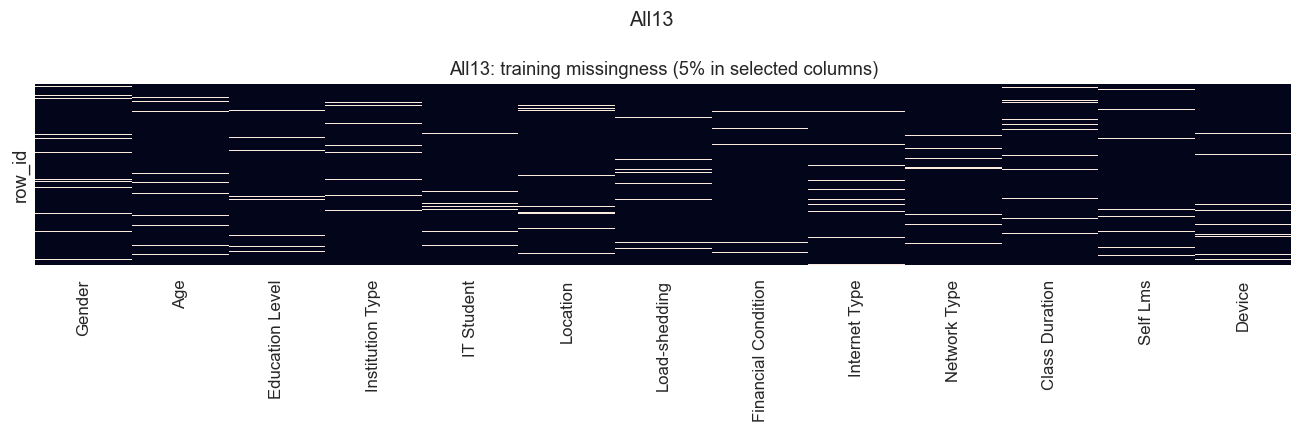

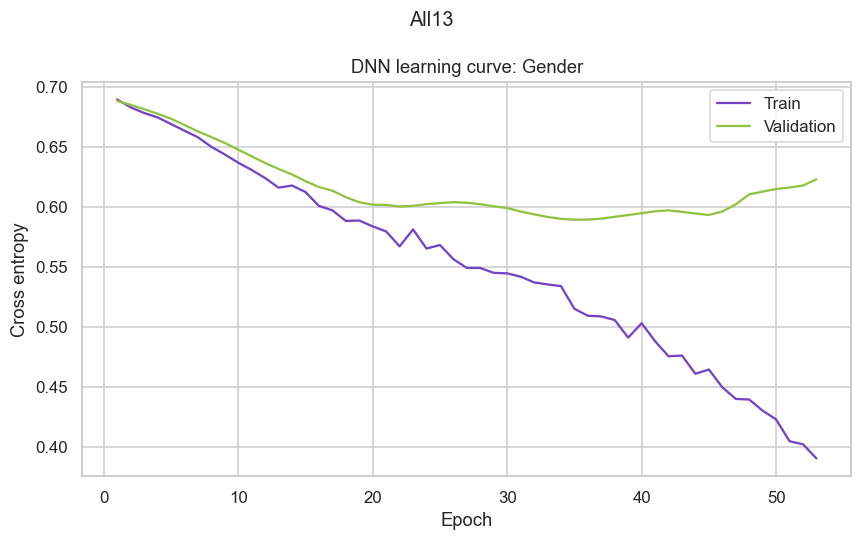

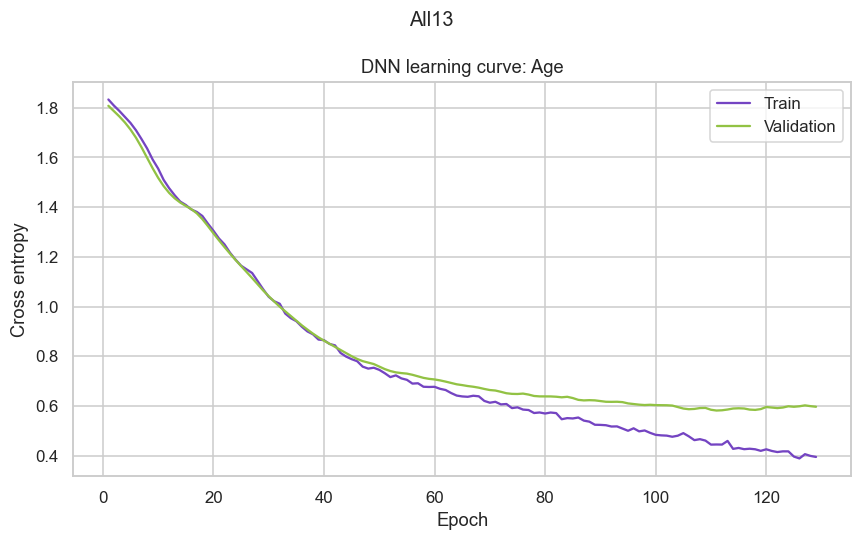

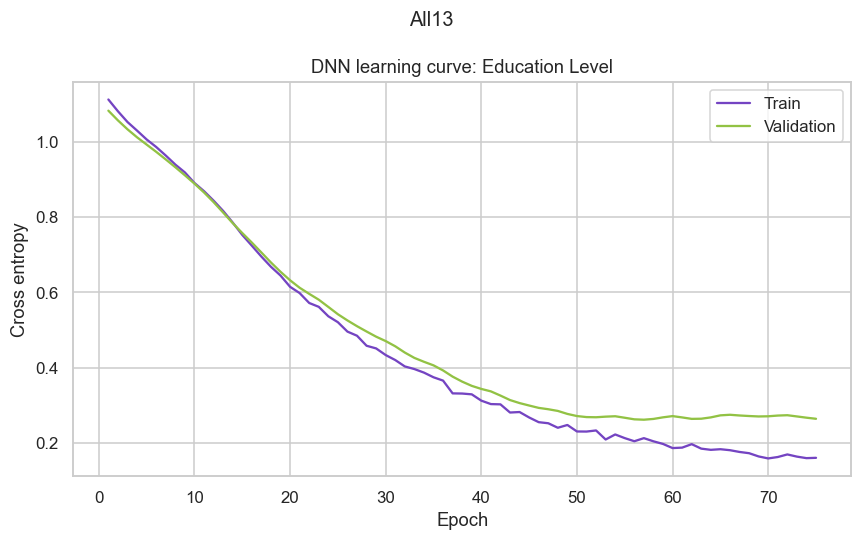

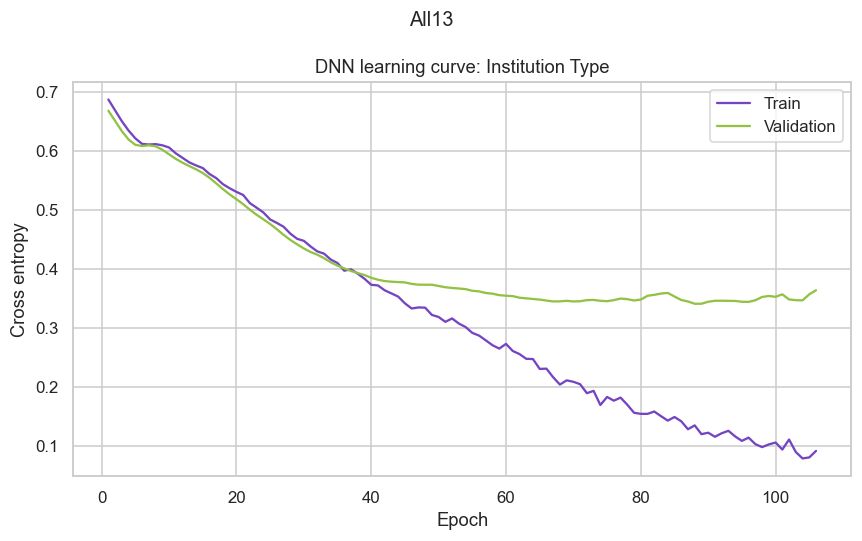

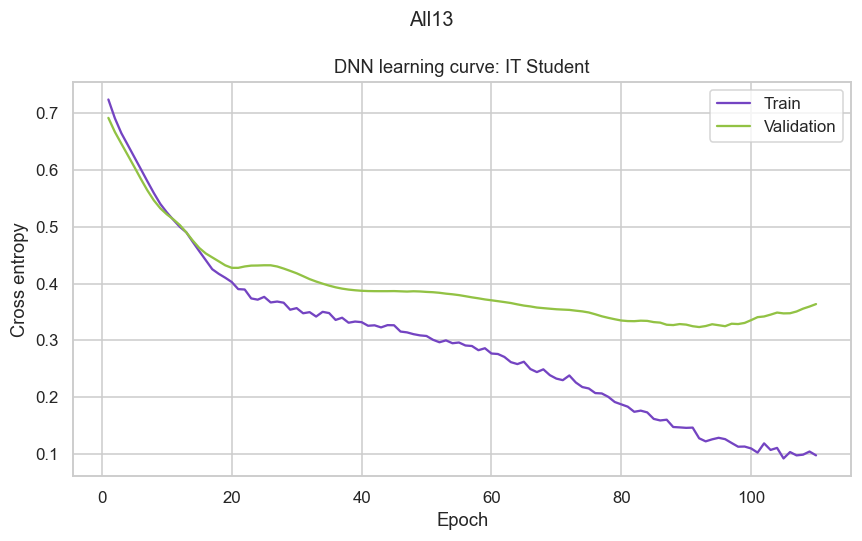

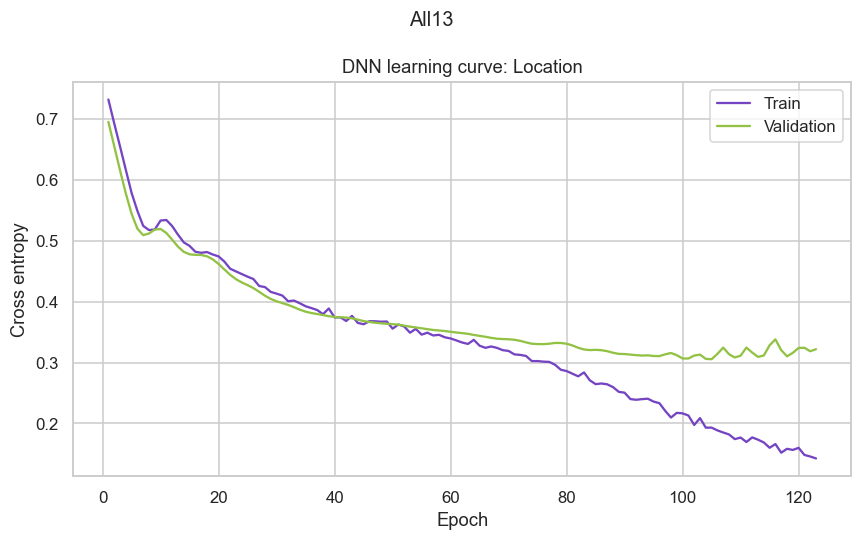

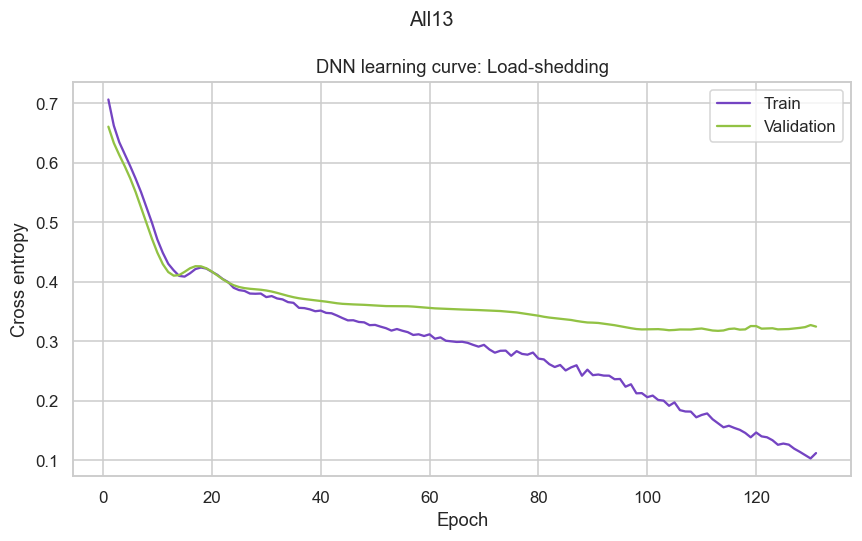

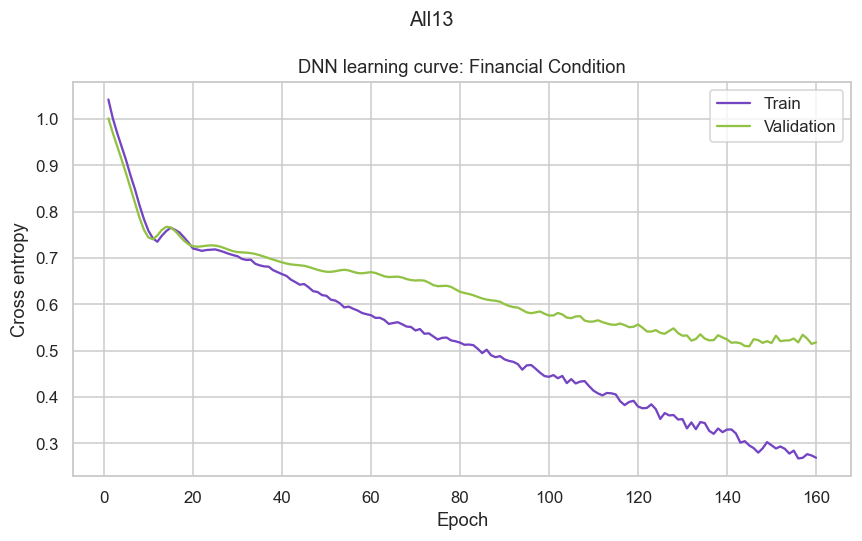

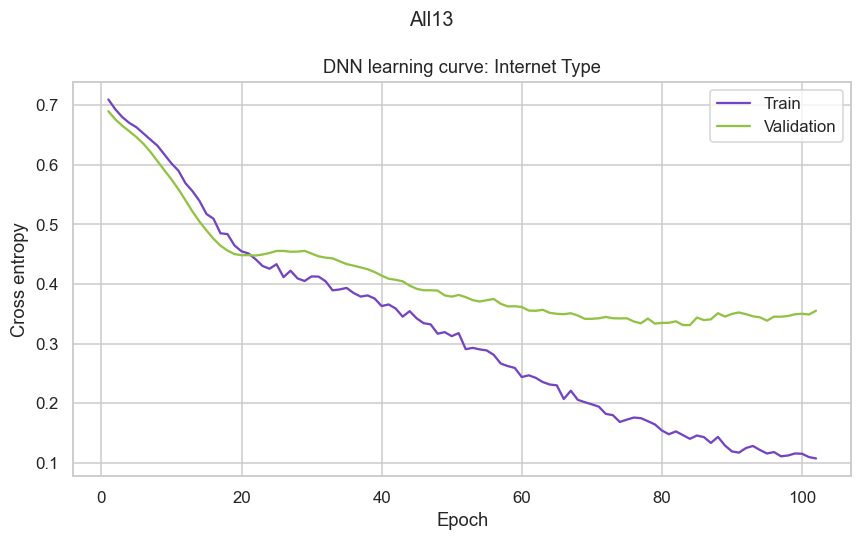

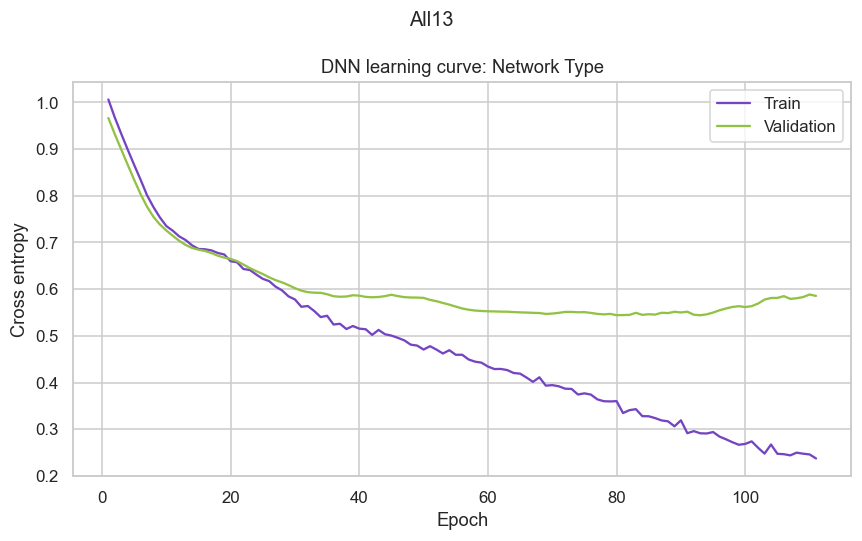

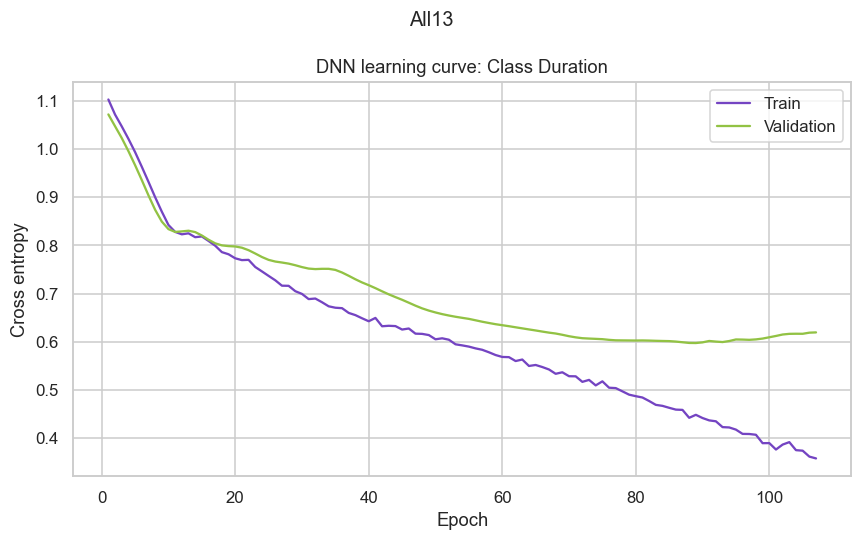

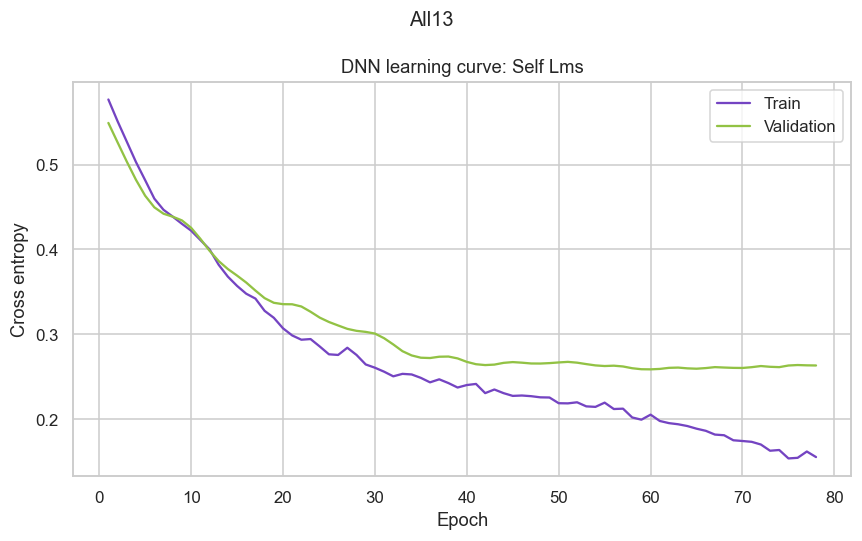

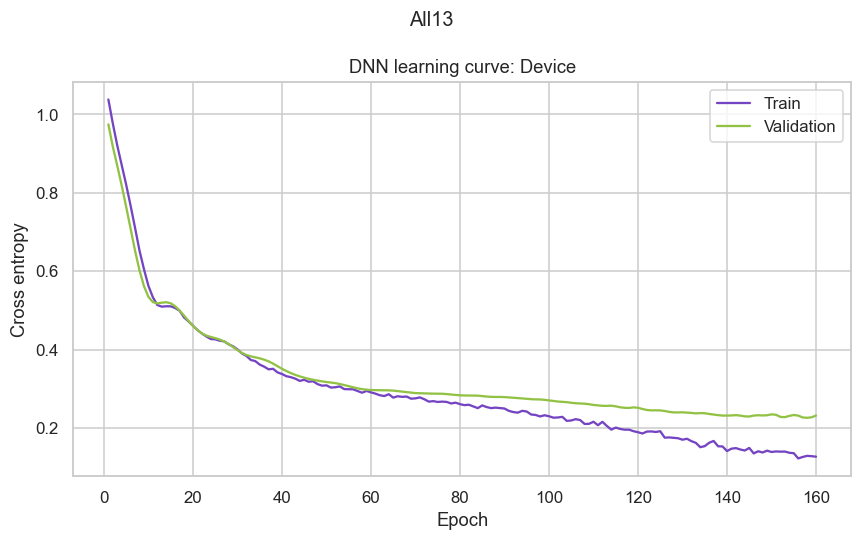

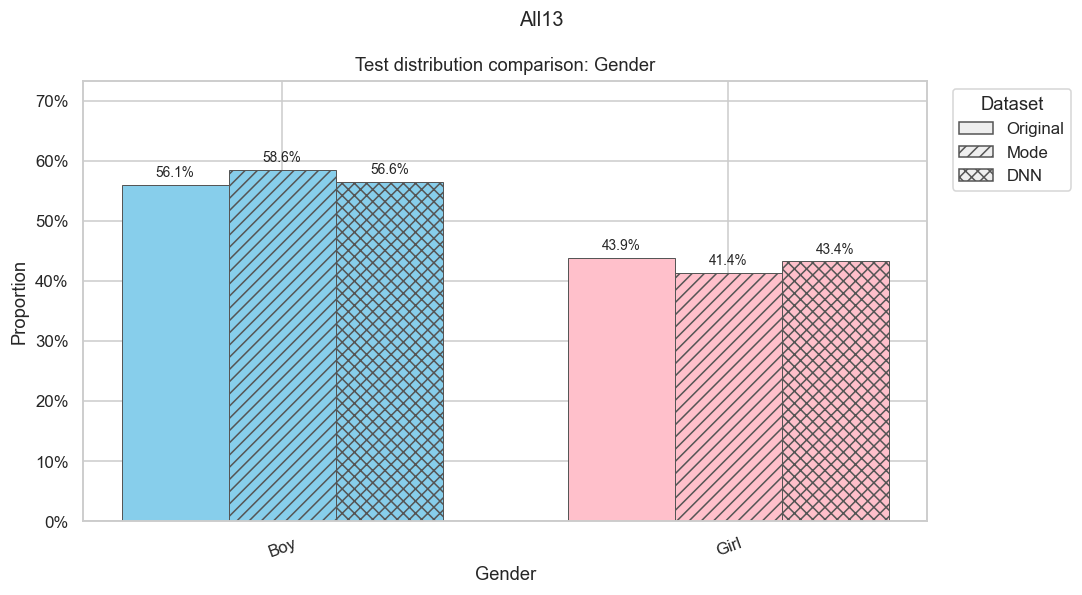

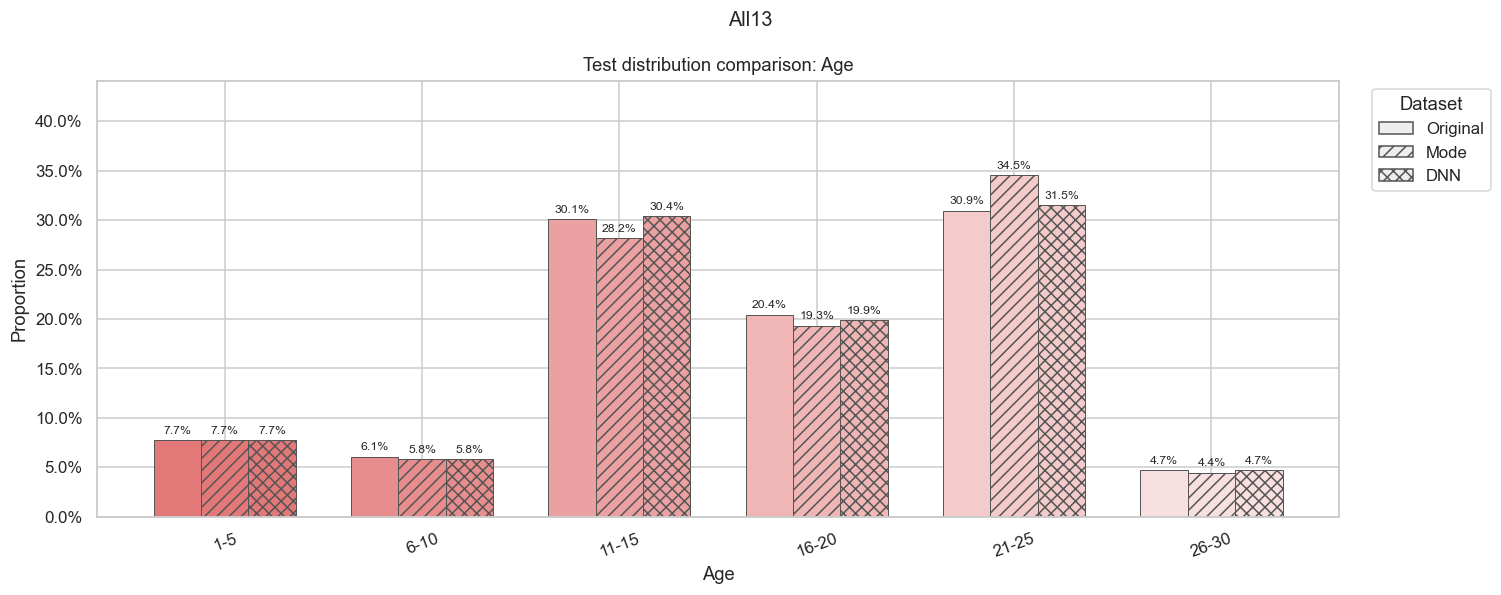

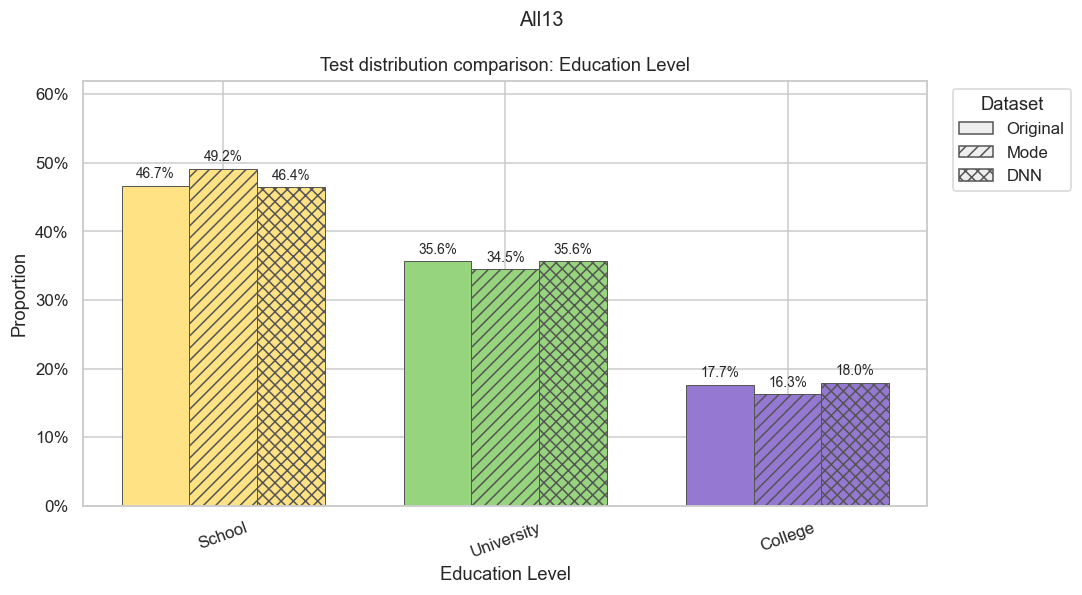

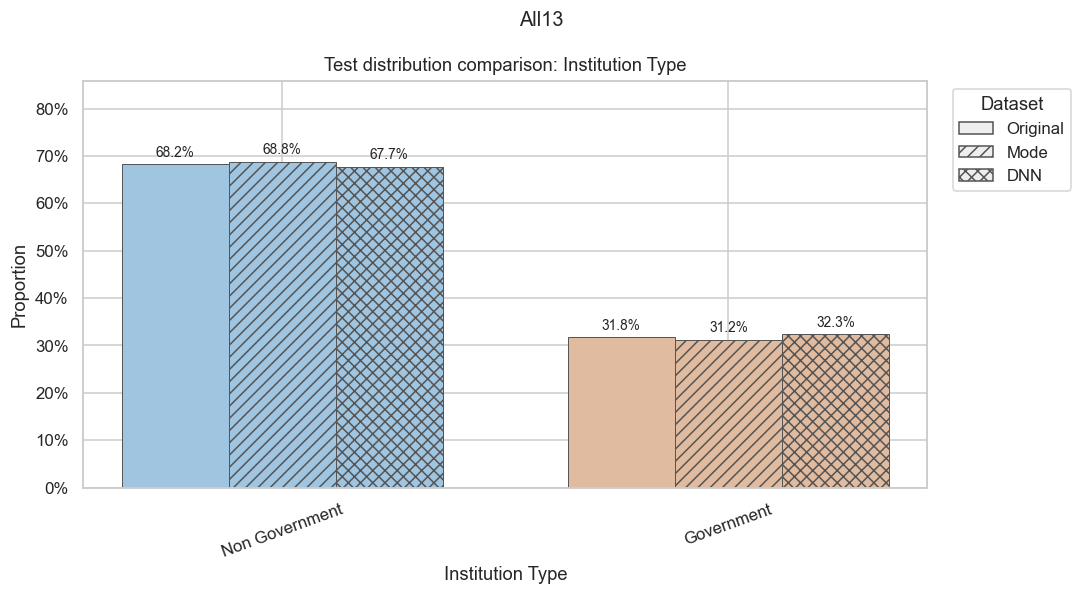

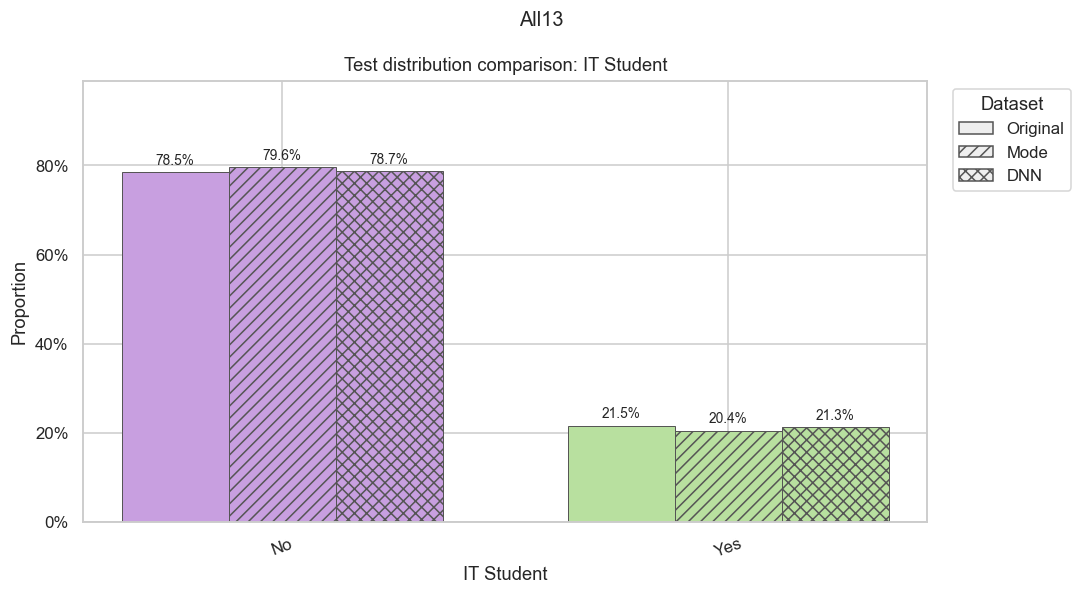

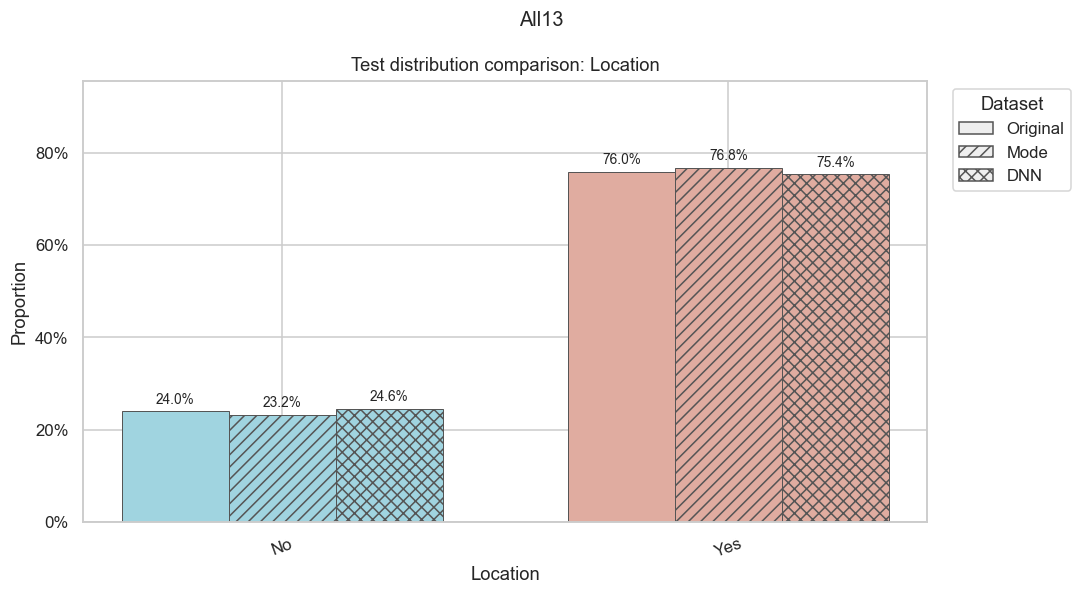

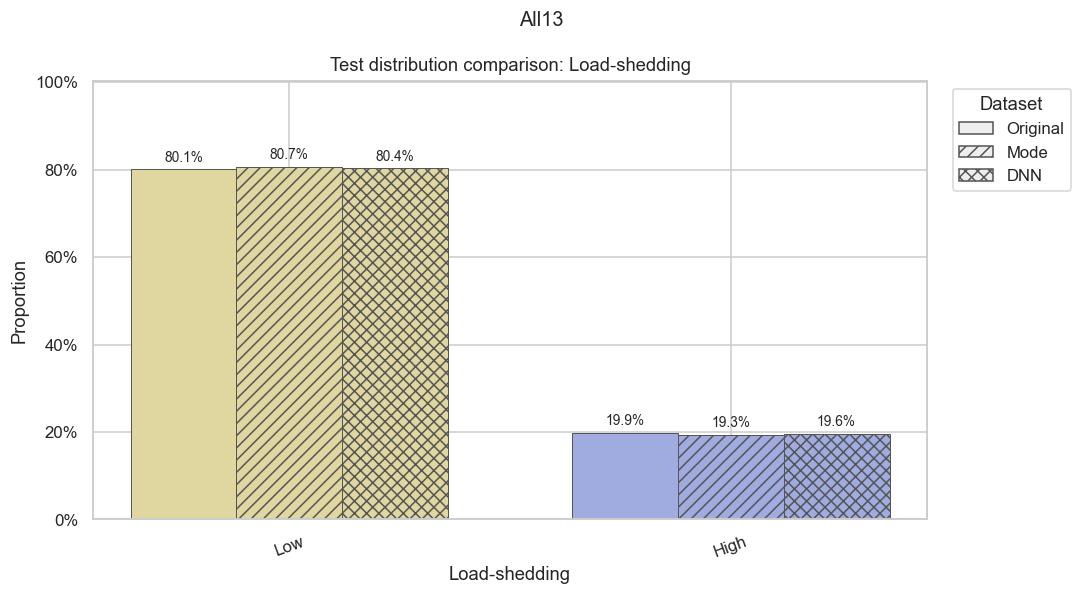

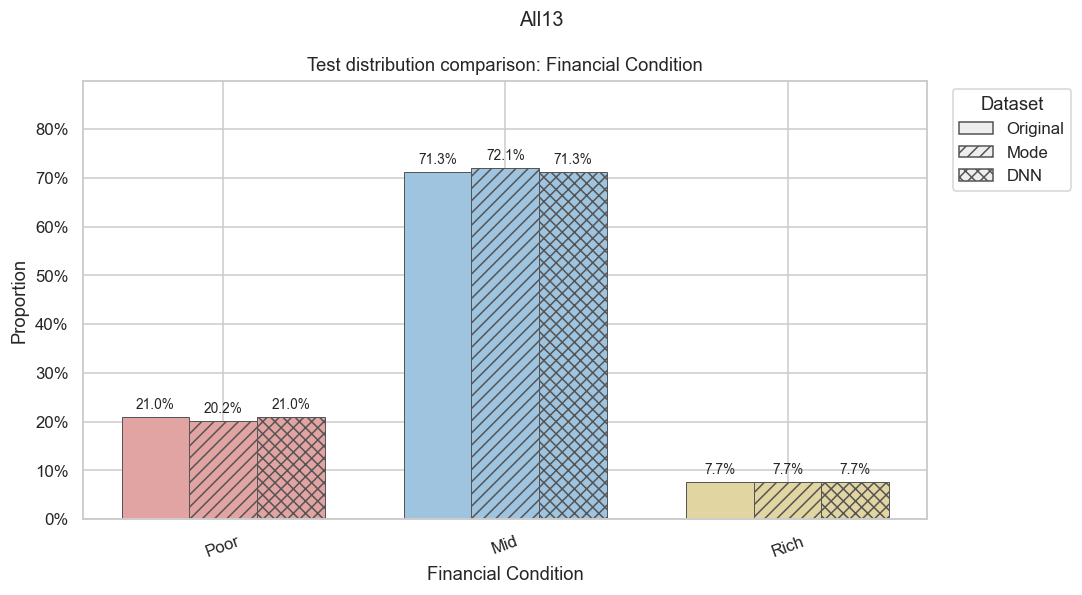

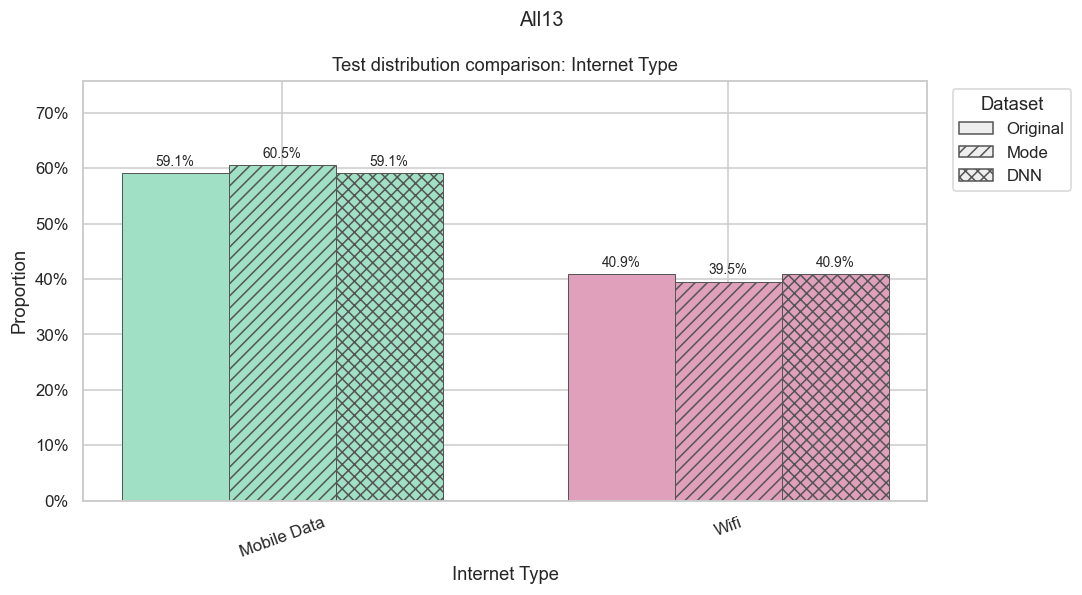

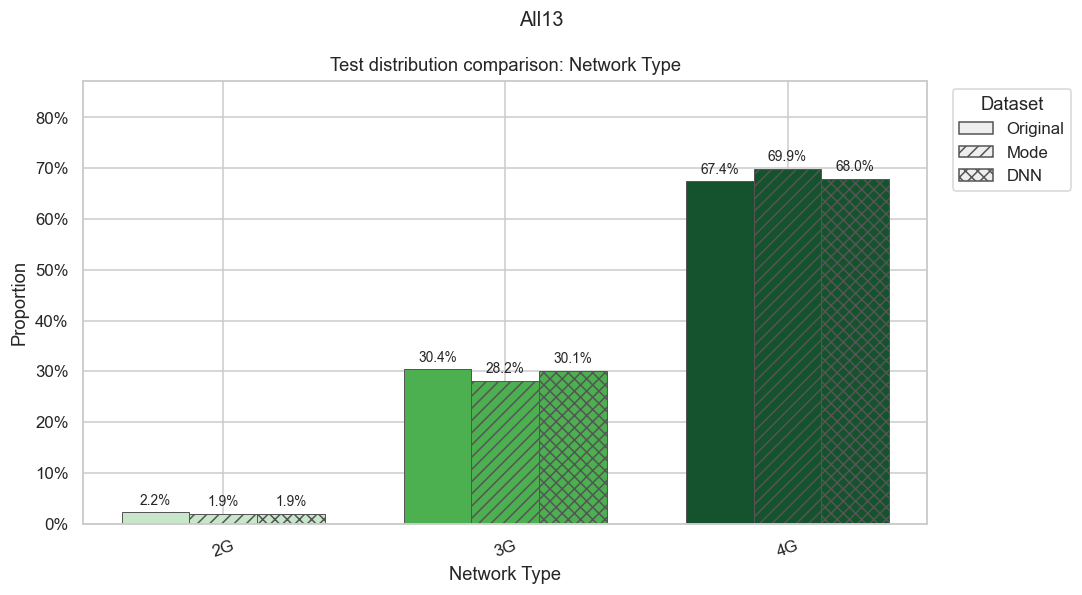

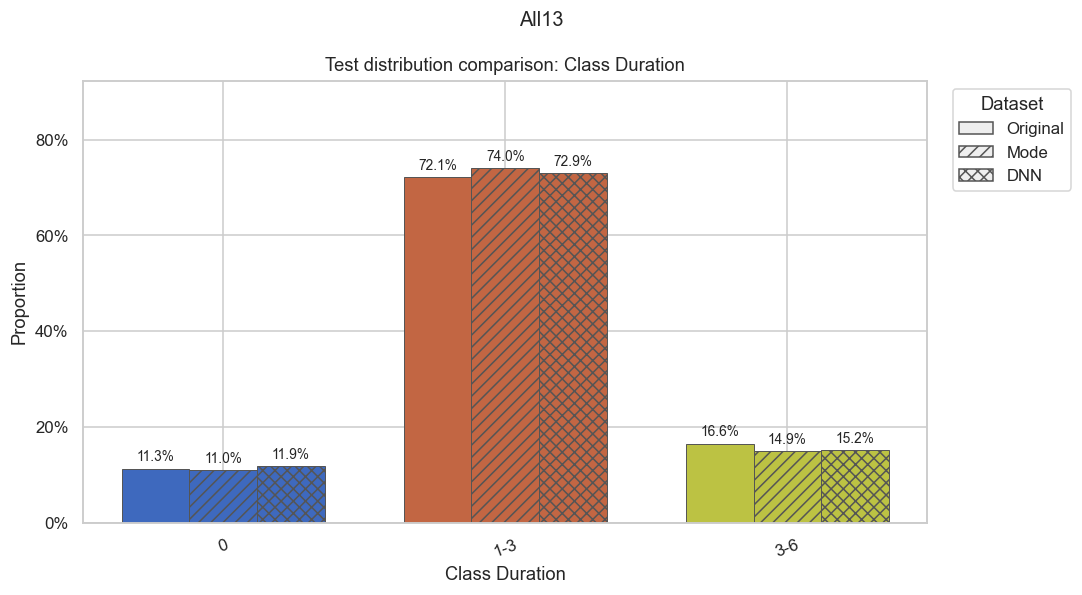

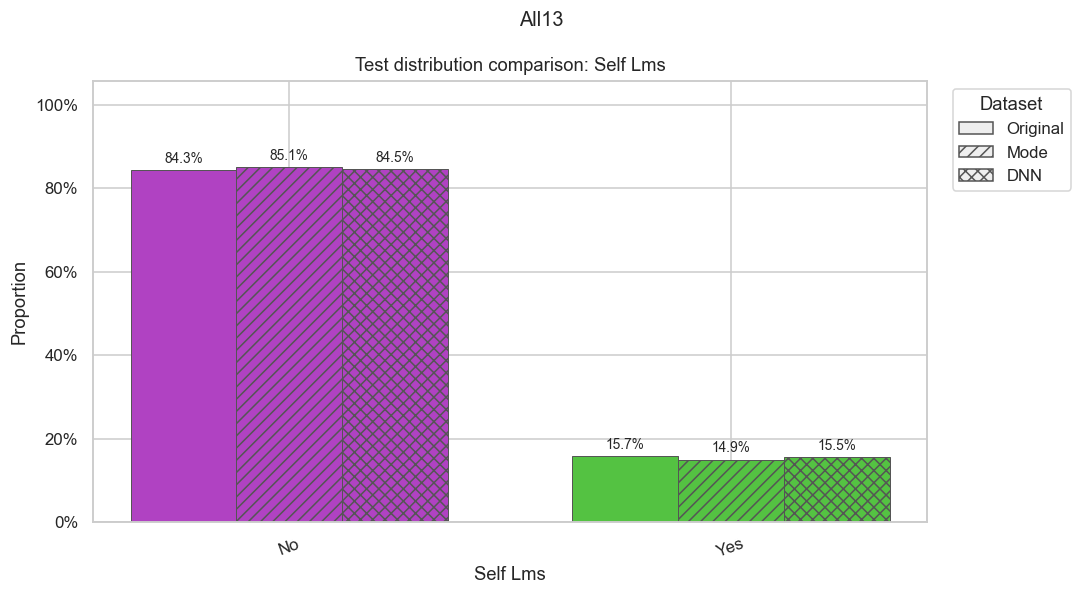

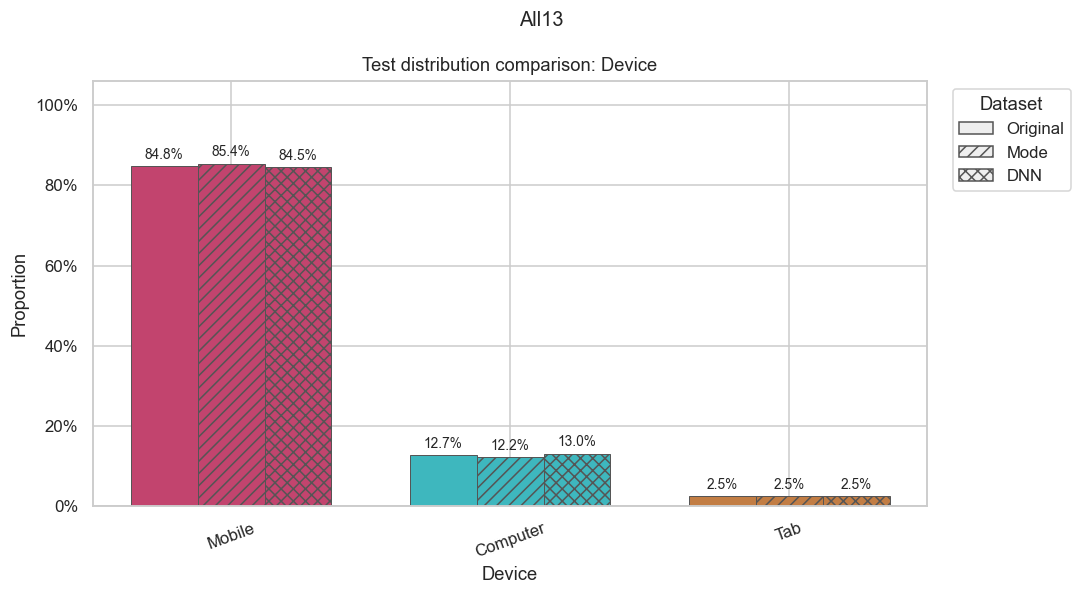

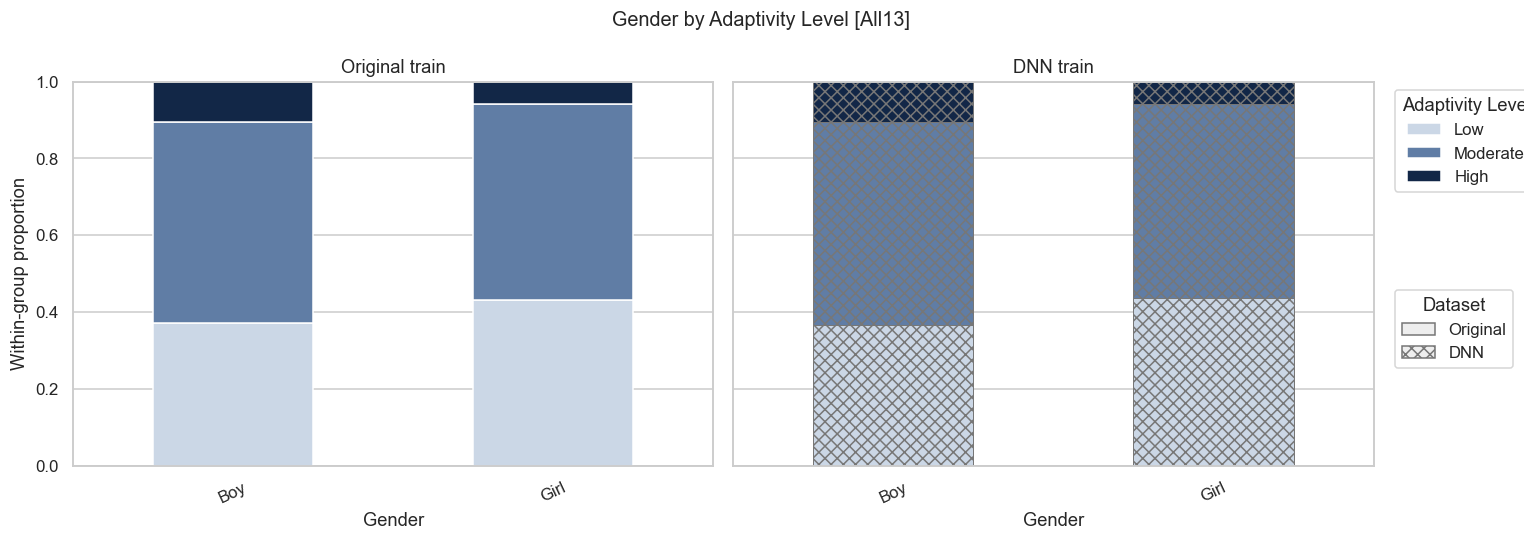

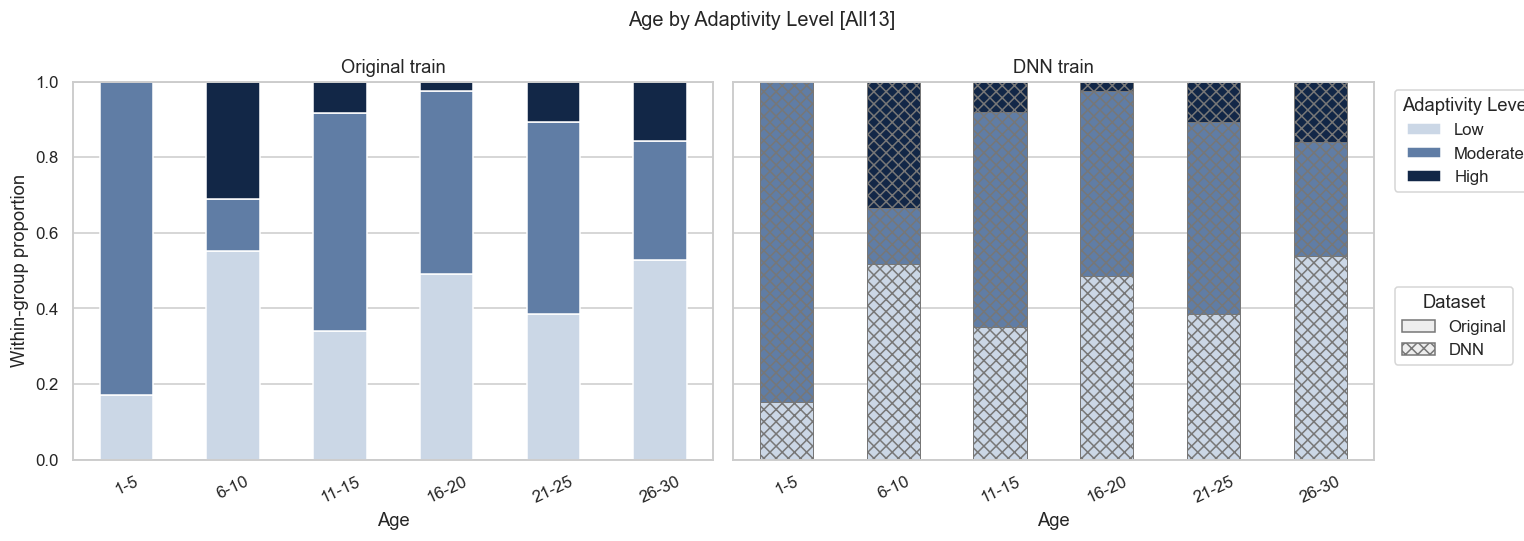

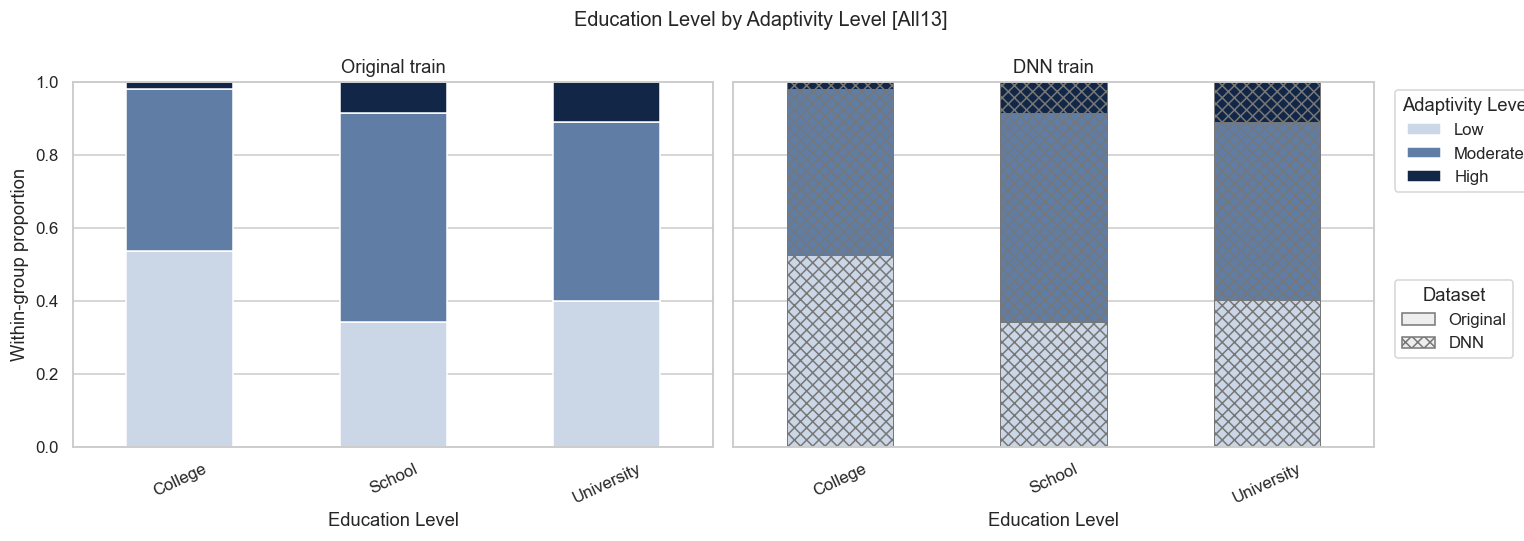

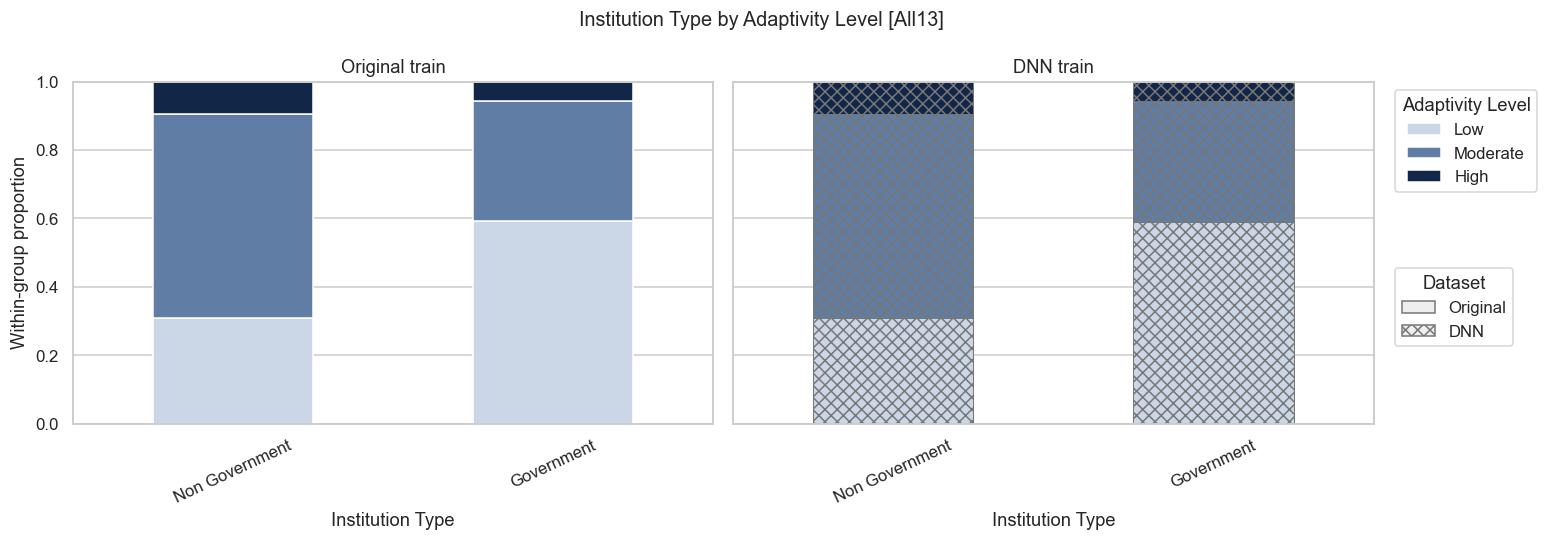

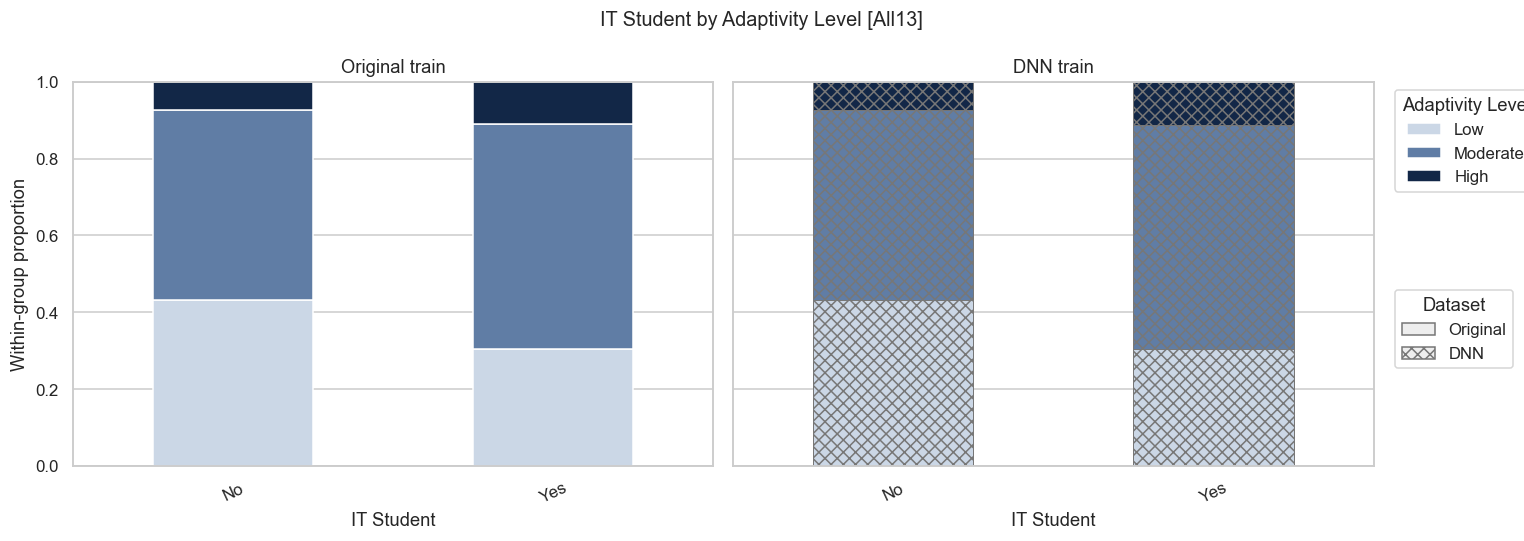

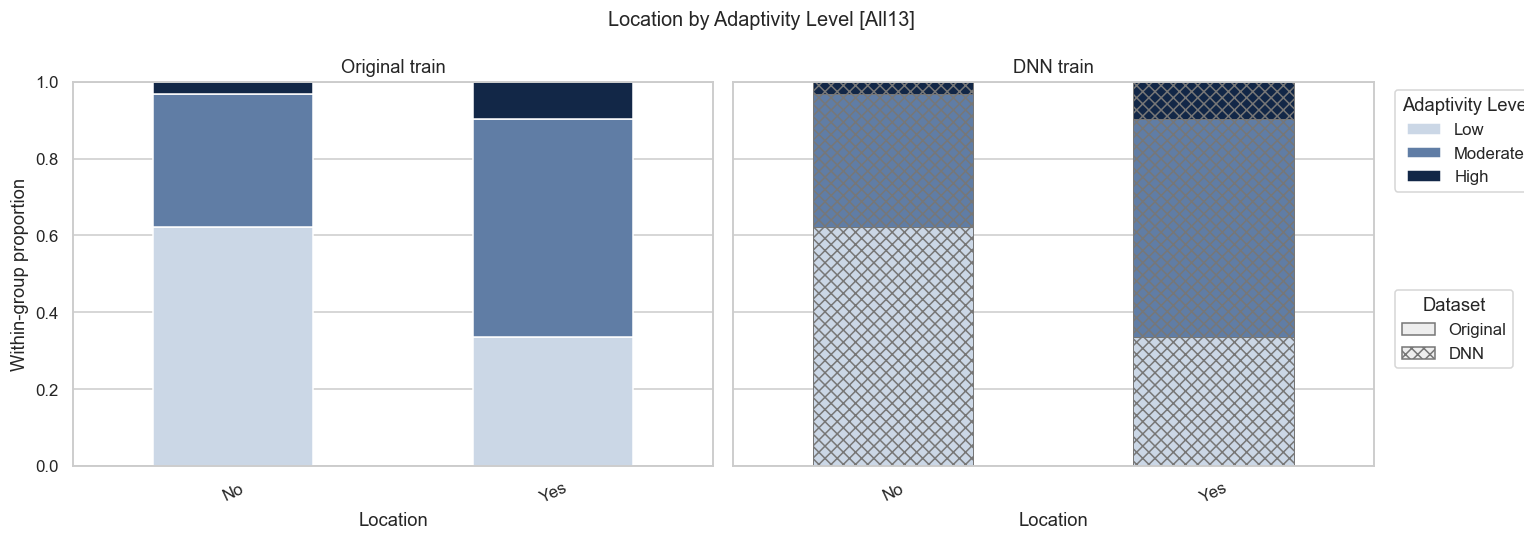

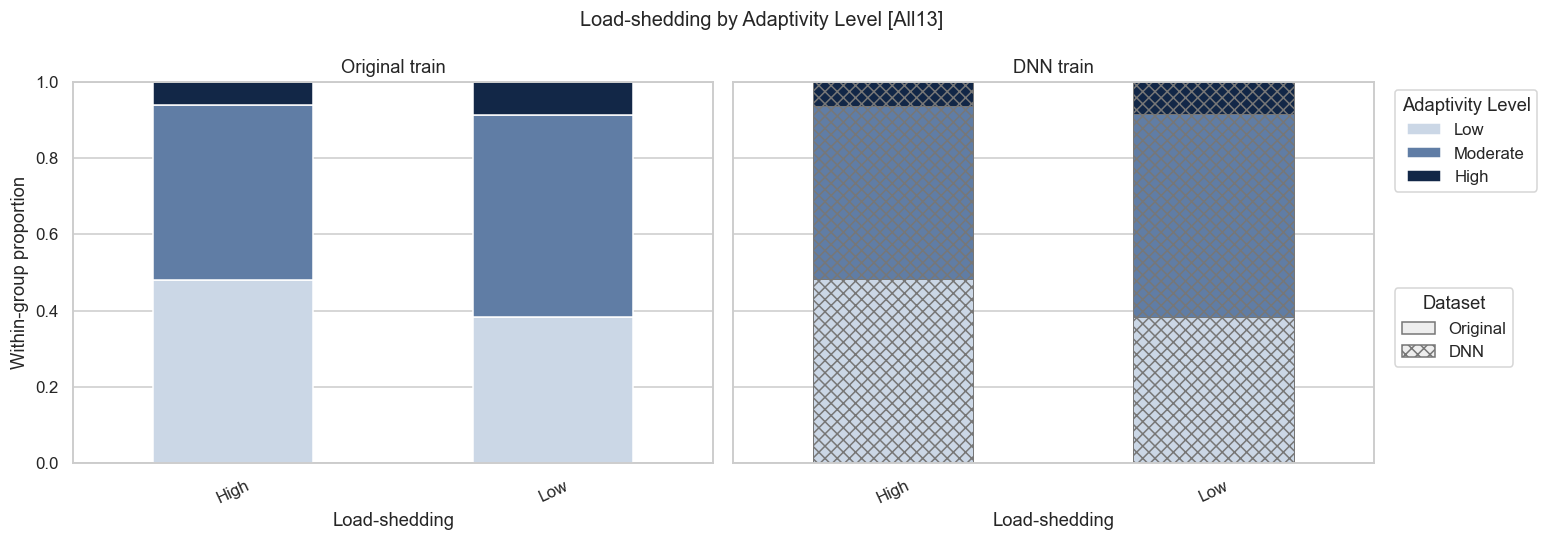

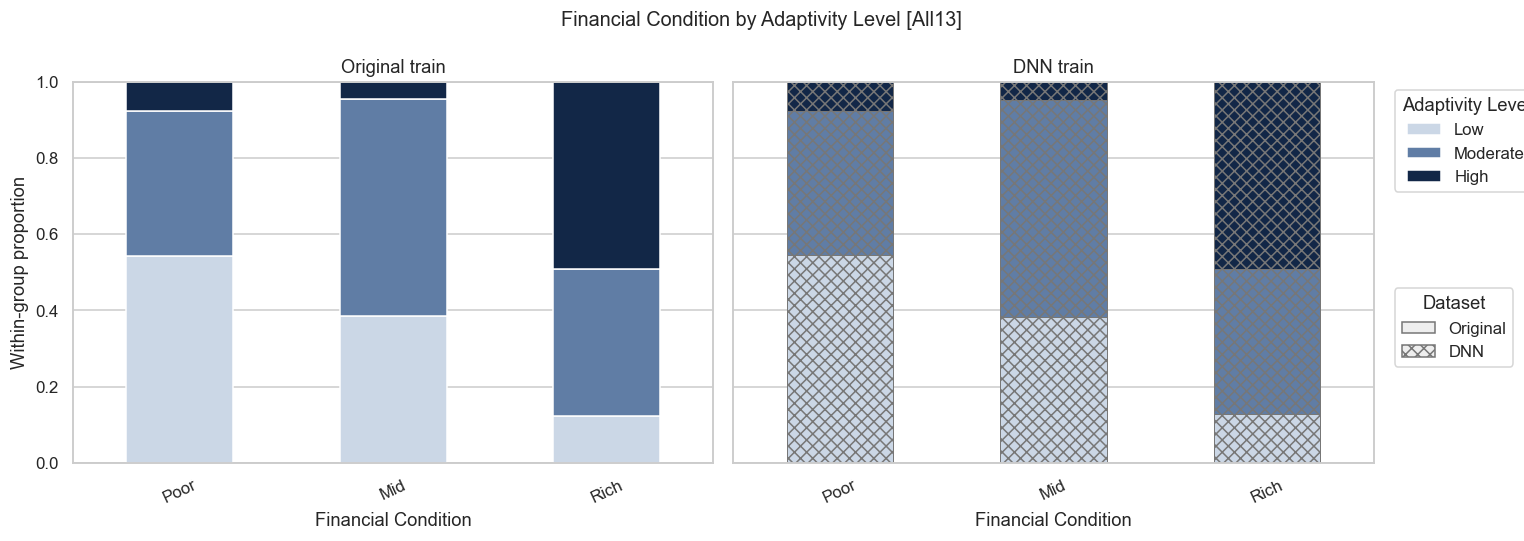

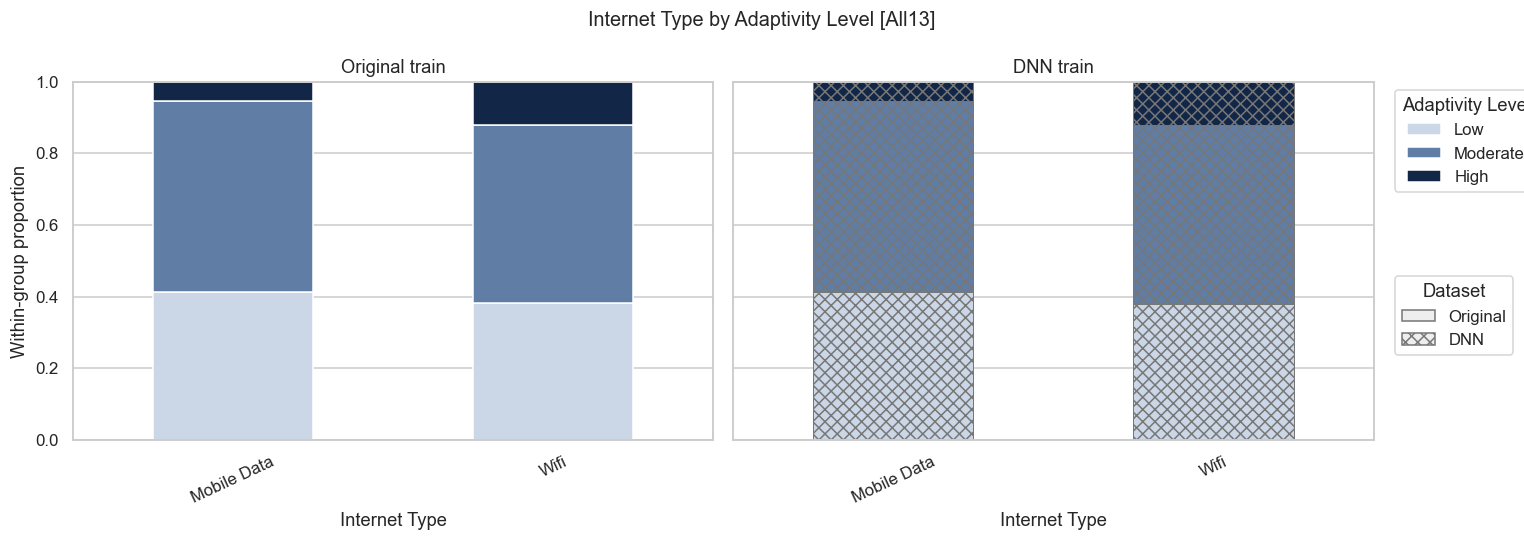

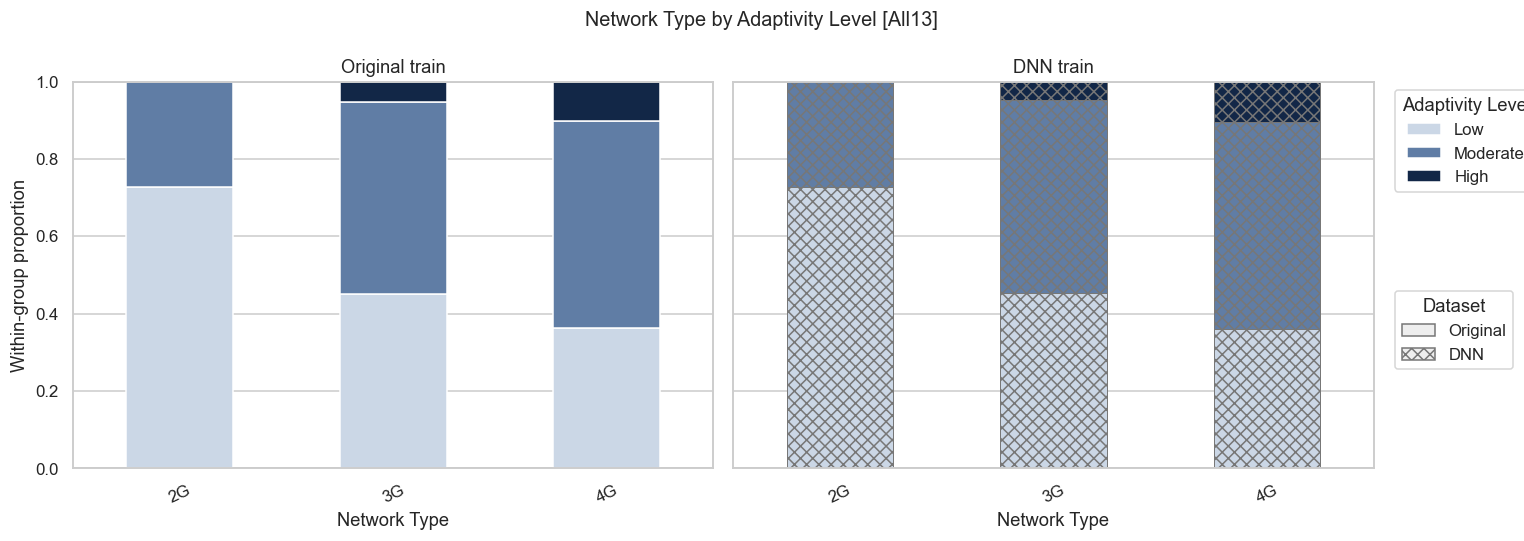

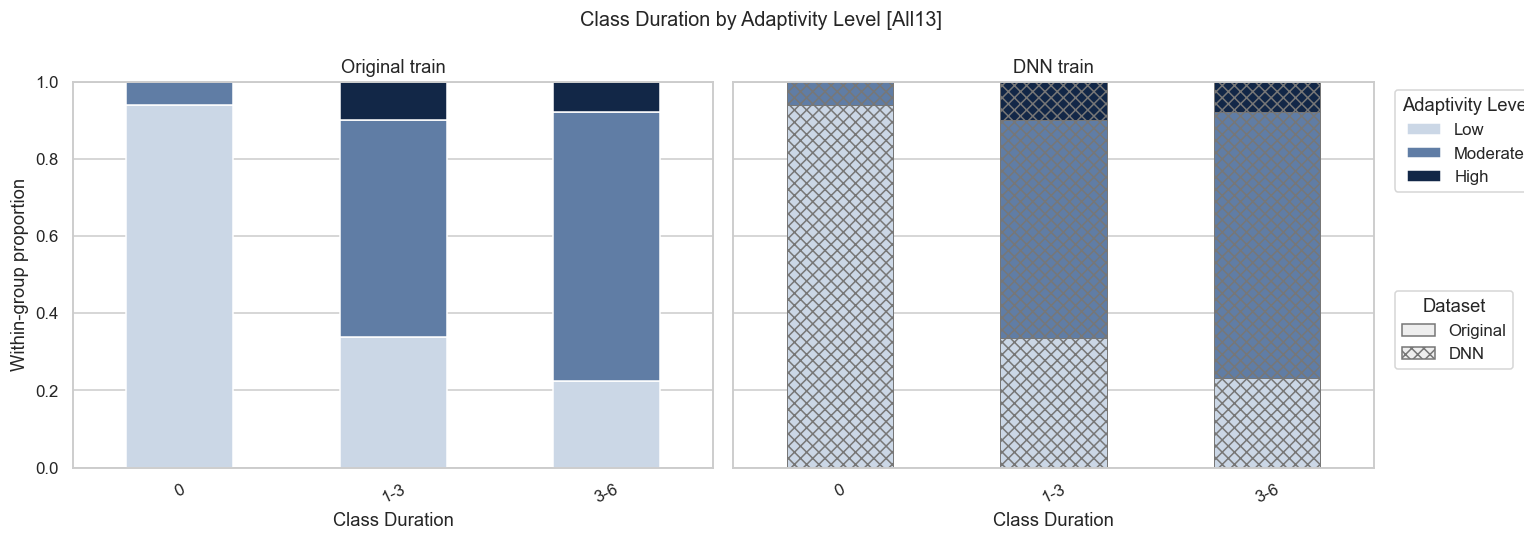

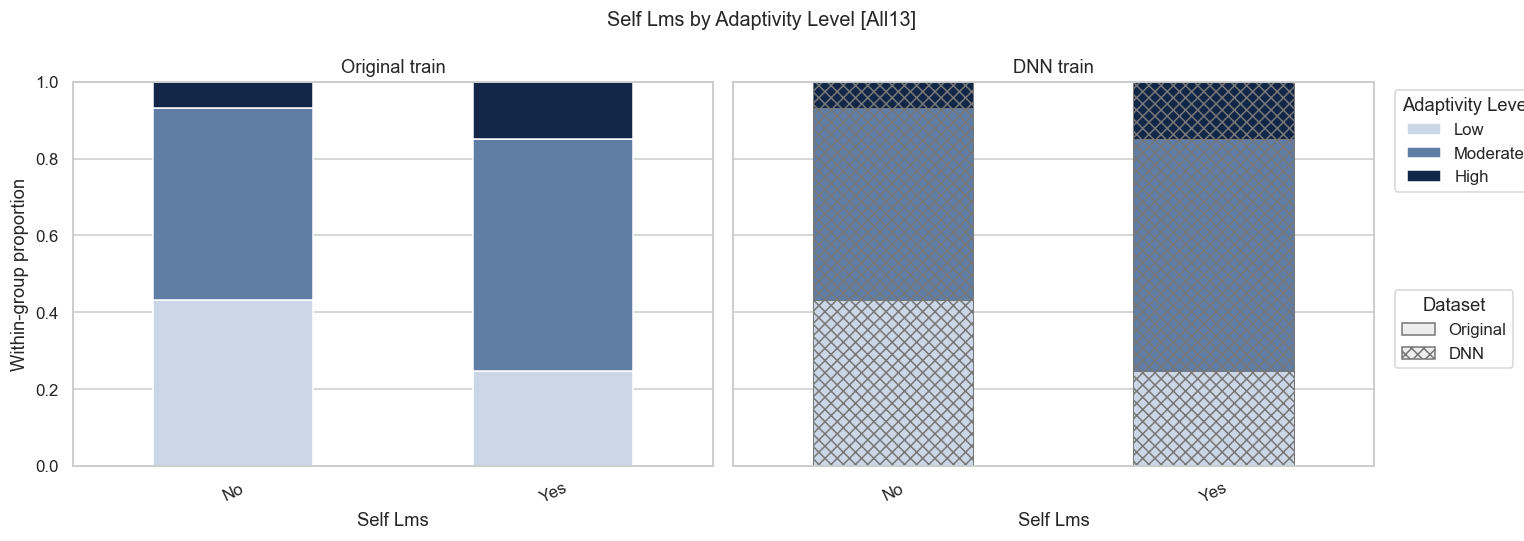

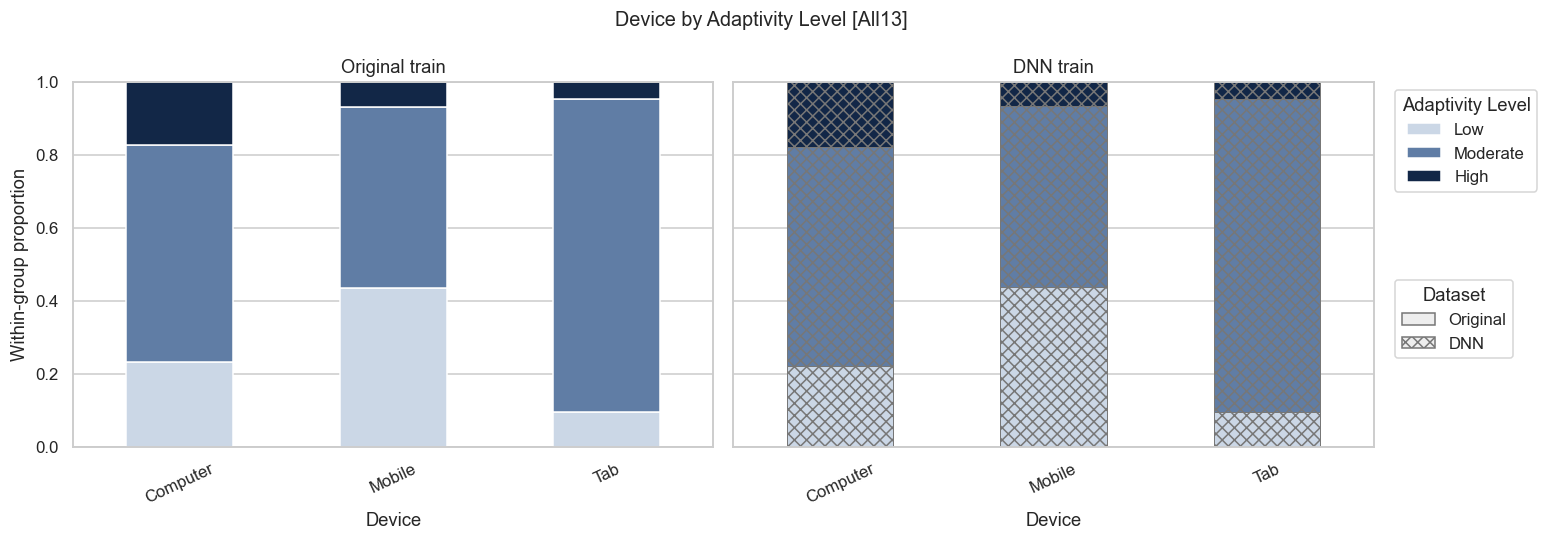

In [12]:
progress('primary',scenario='All13')
PRIMARY['All13']=fit_condition(ALL_COLUMNS,PRIMARY_RATE,SEED)
save_primary('All13',PRIMARY['All13'])
plot_primary('All13',PRIMARY['All13'])


## 7. Top5 Additional Experiment

- **Purpose:** Introduce 5% missingness into each of the five most important input features.
- **Rationale:** Determine whether DNN imputation also helps when important information is damaged.
- **Key points:** Mask 300 cells, approximately 1.92% of all input cells. Because the number of missing cells differs from All13, differences in scores cannot be interpreted as the isolated effect of feature importance.


,split,method,column,n_masked,masked_accuracy,masked_macro_f1,TV_all_cells,mean_confidence
10,test,Mode,Financial Condition,17,0.823529,0.301075,0.008287,NaN
11,test,Mode,Age,20,0.350000,0.086420,0.035912,NaN
12,test,Mode,Class Duration,20,0.650000,0.262626,0.019337,NaN
13,test,Mode,Gender,14,0.357143,0.263158,0.024862,NaN
14,test,Mode,Institution Type,12,0.833333,0.454545,0.005525,NaN
15,test,DNN,Financial Condition,17,0.823529,0.486772,0.002762,0.889870
16,test,DNN,Age,20,0.950000,0.655556,0.002762,0.836968
17,test,DNN,Class Duration,20,0.750000,0.664751,0.011050,0.872632
18,test,DNN,Gender,14,0.642857,0.625668,0.002762,0.729287
19,test,DNN,Institution Type,12,0.916667,0.873684,0.002762,0.896582


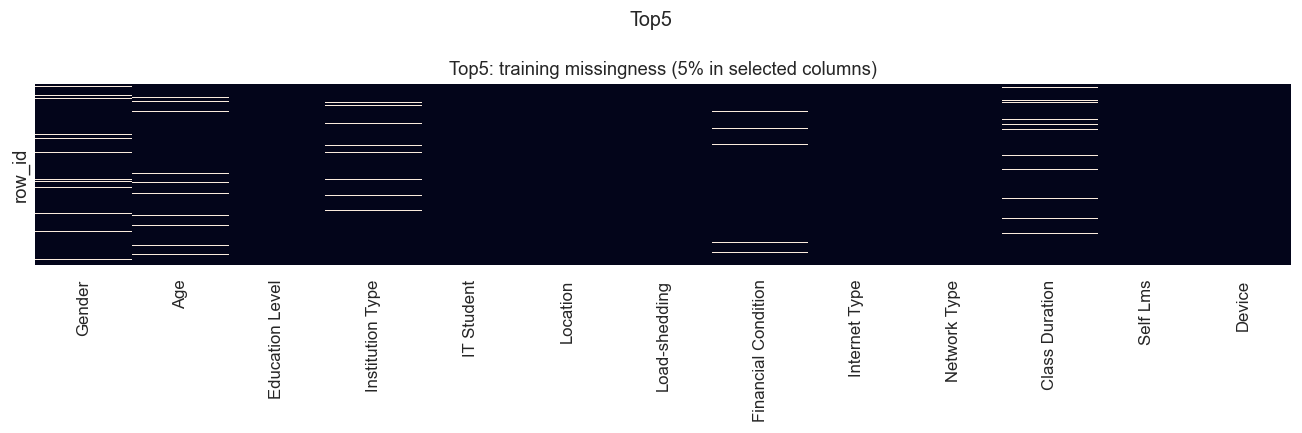

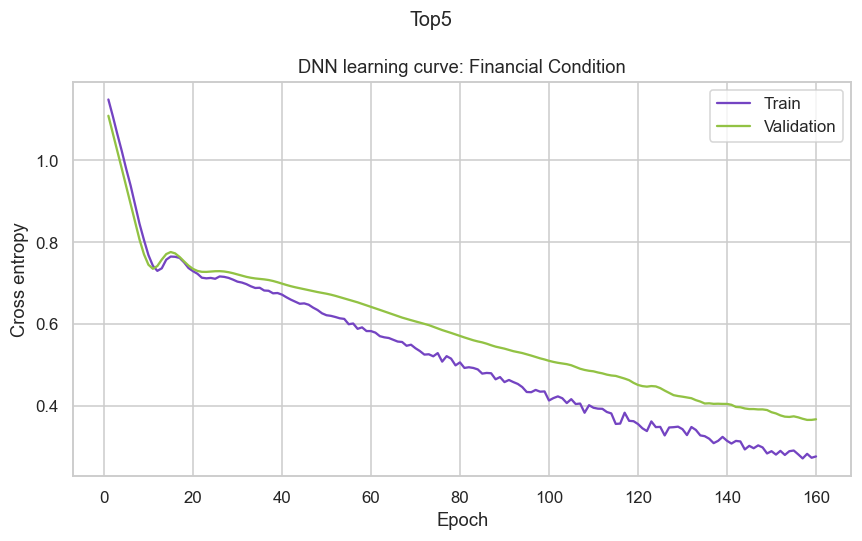

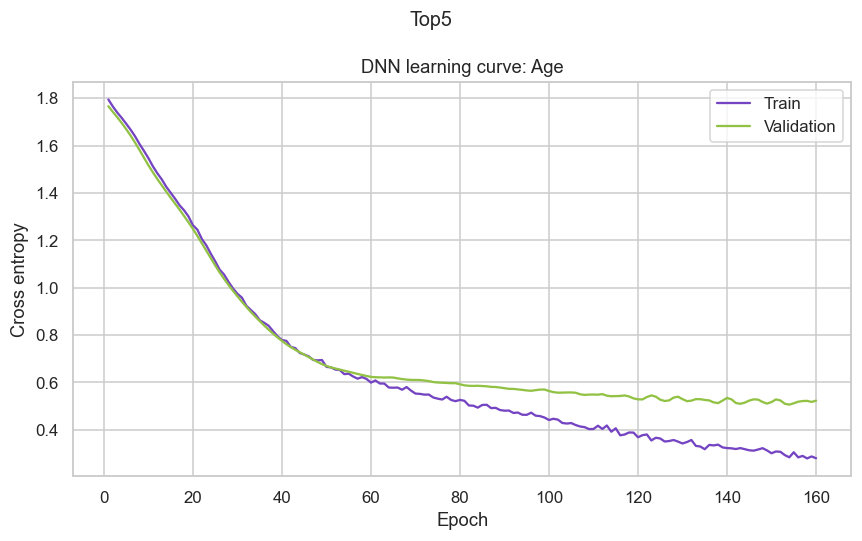

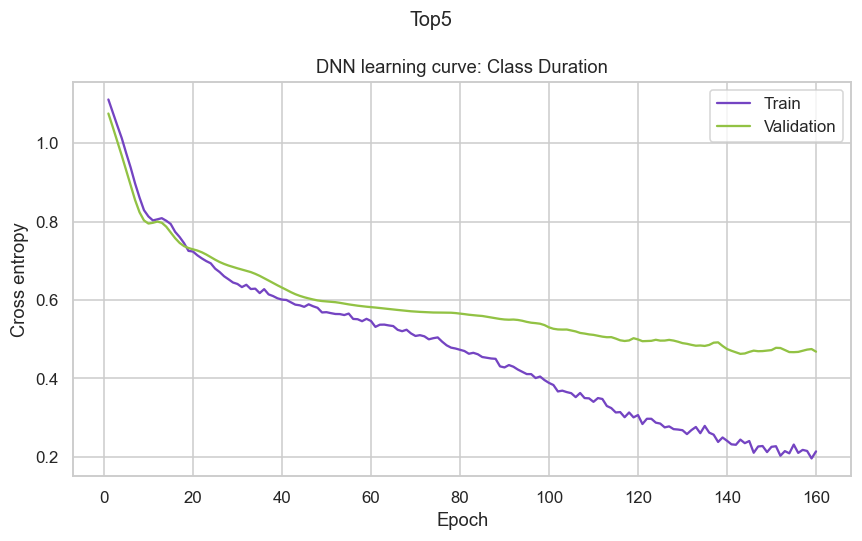

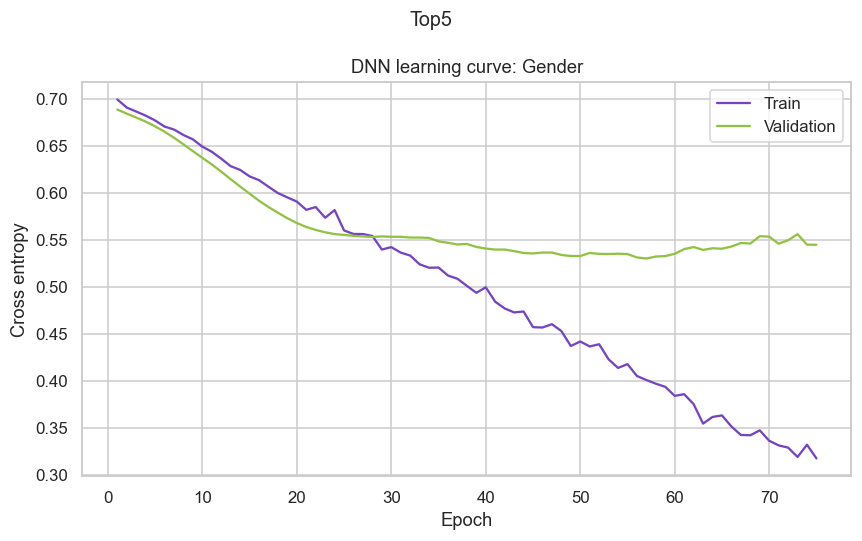

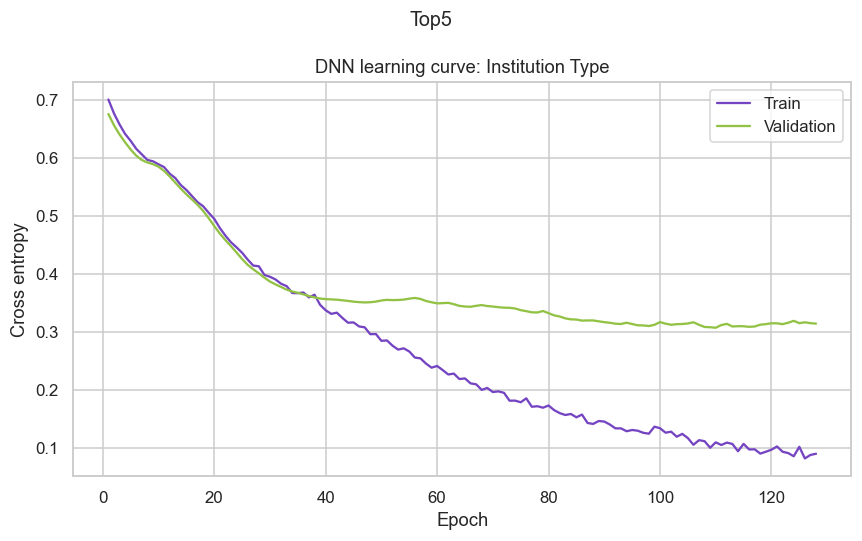

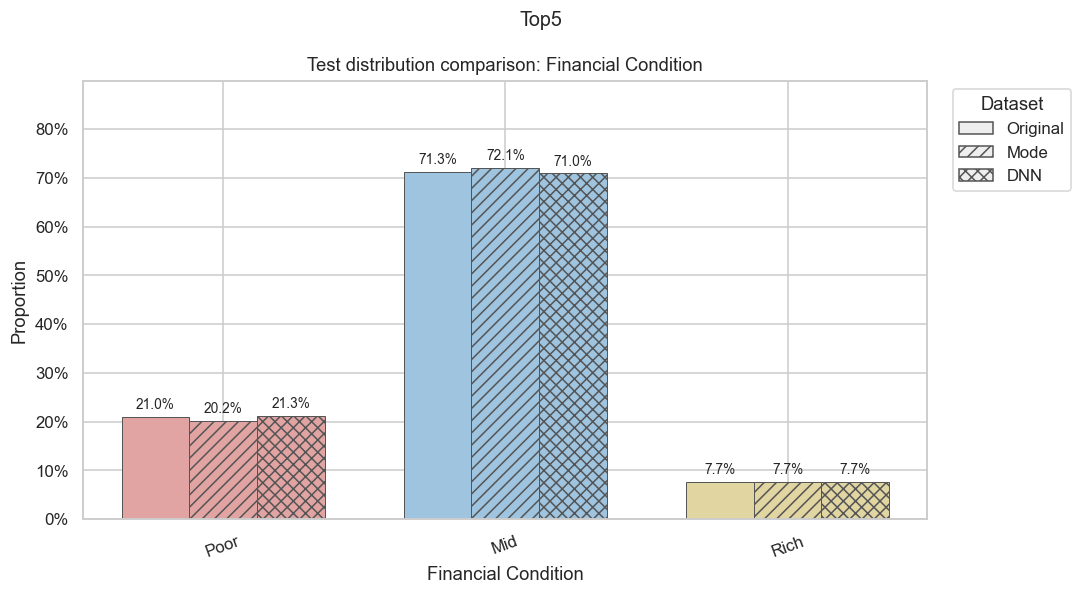

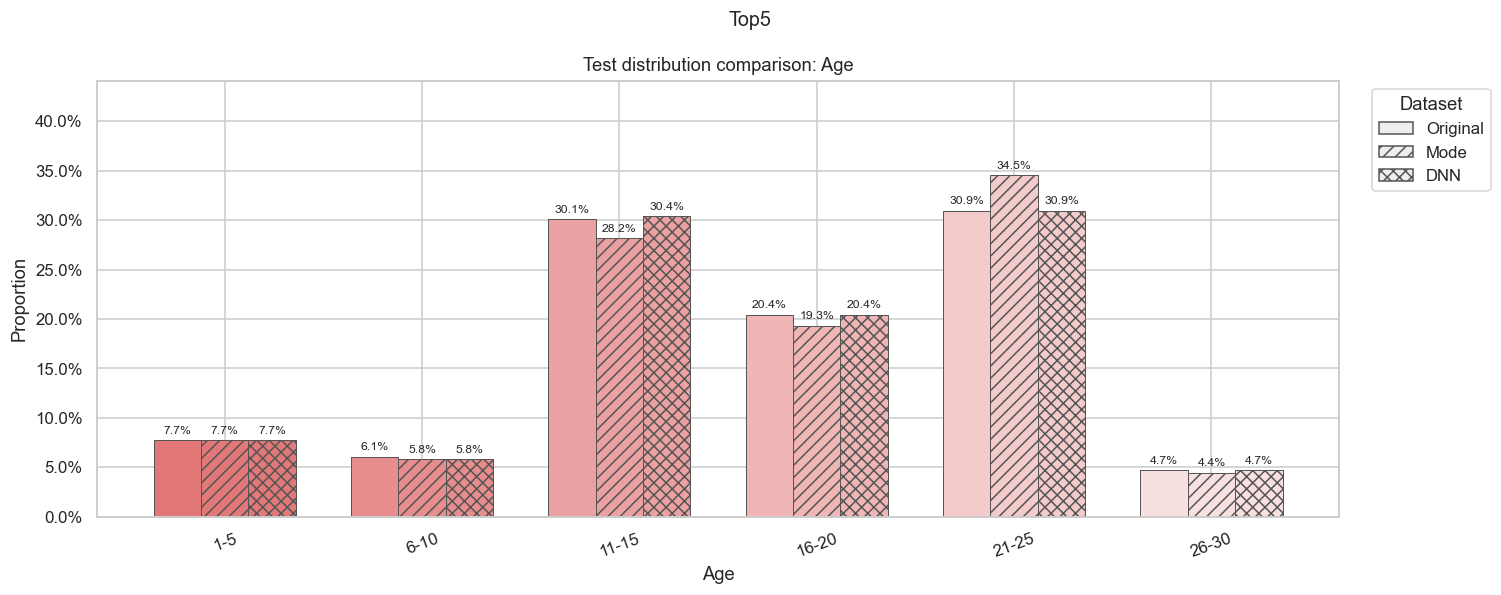

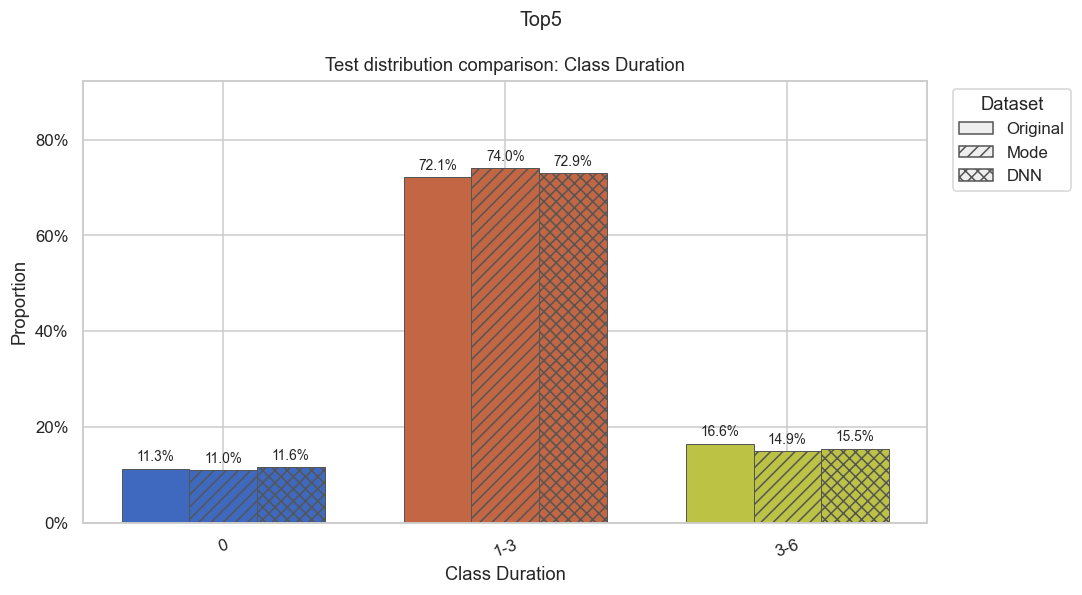

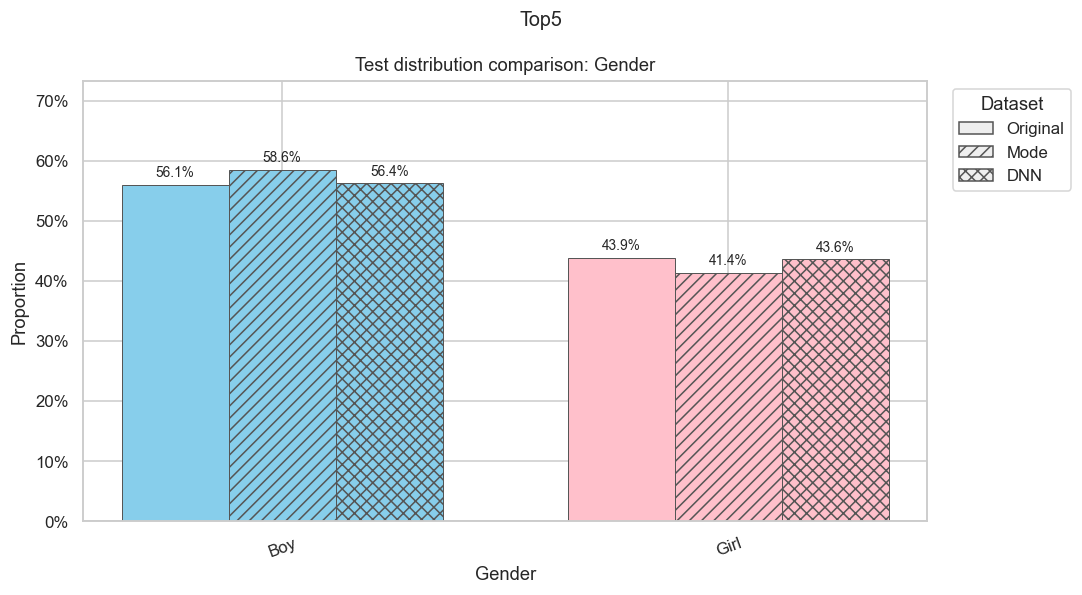

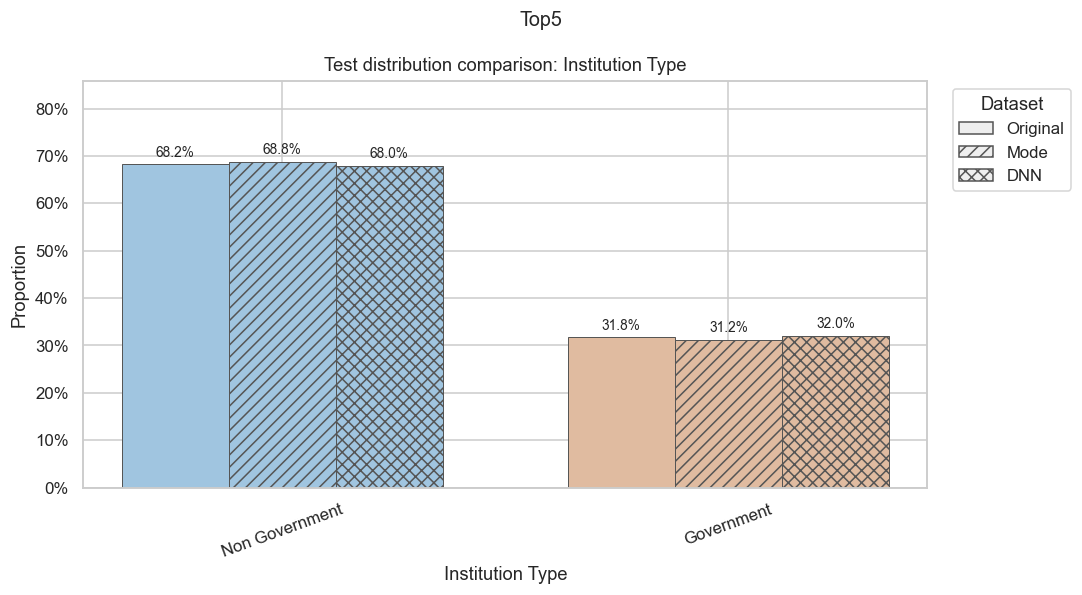

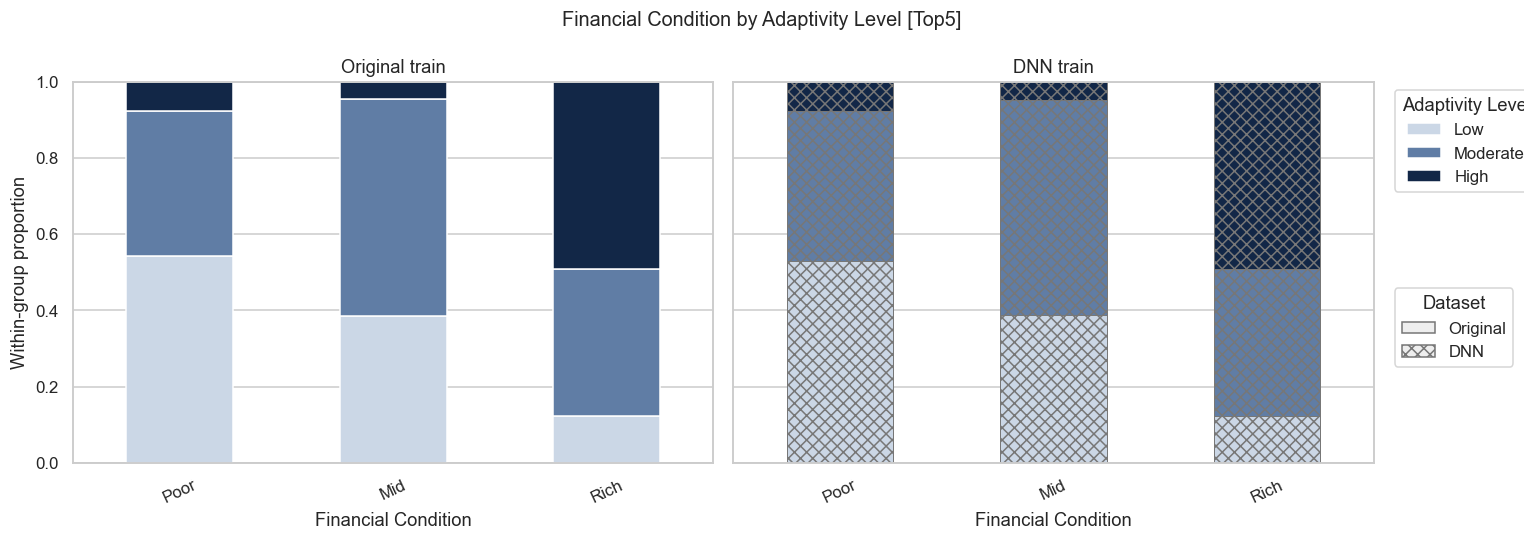

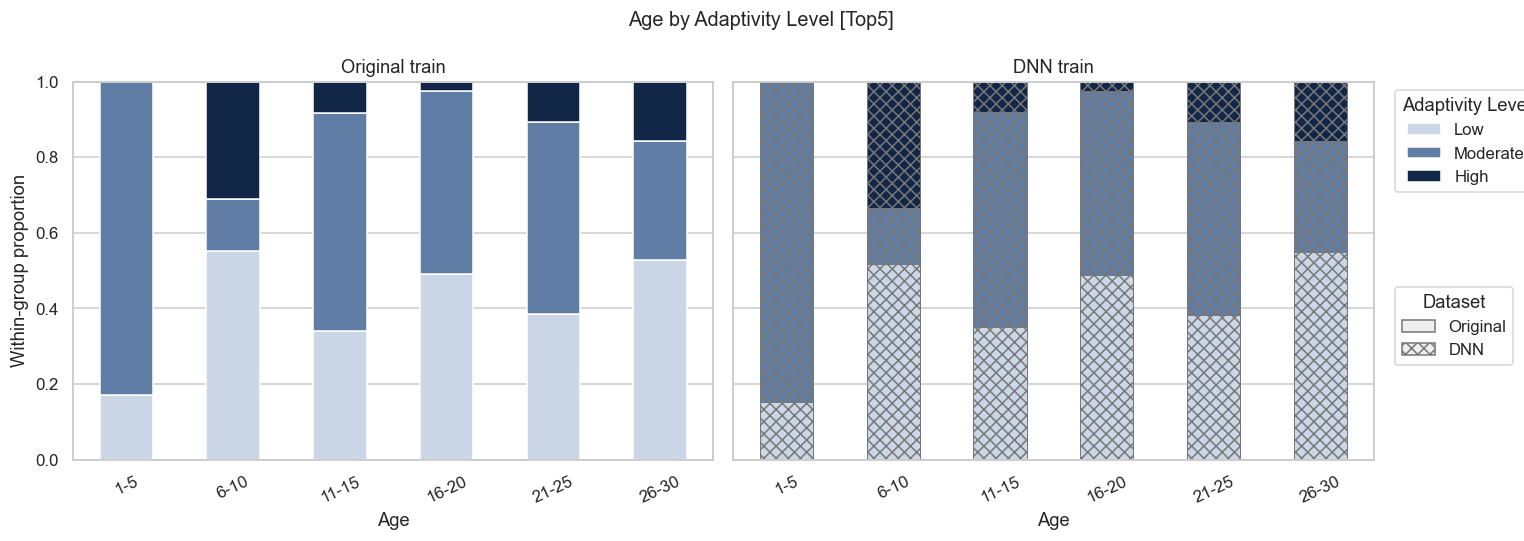

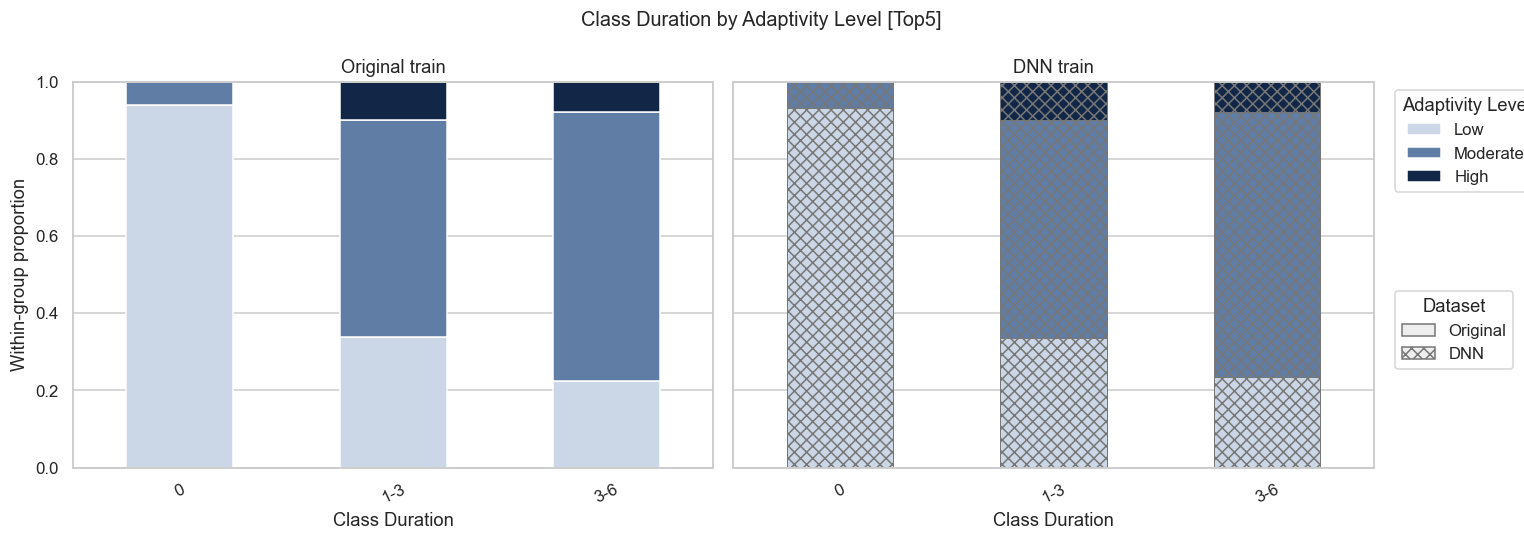

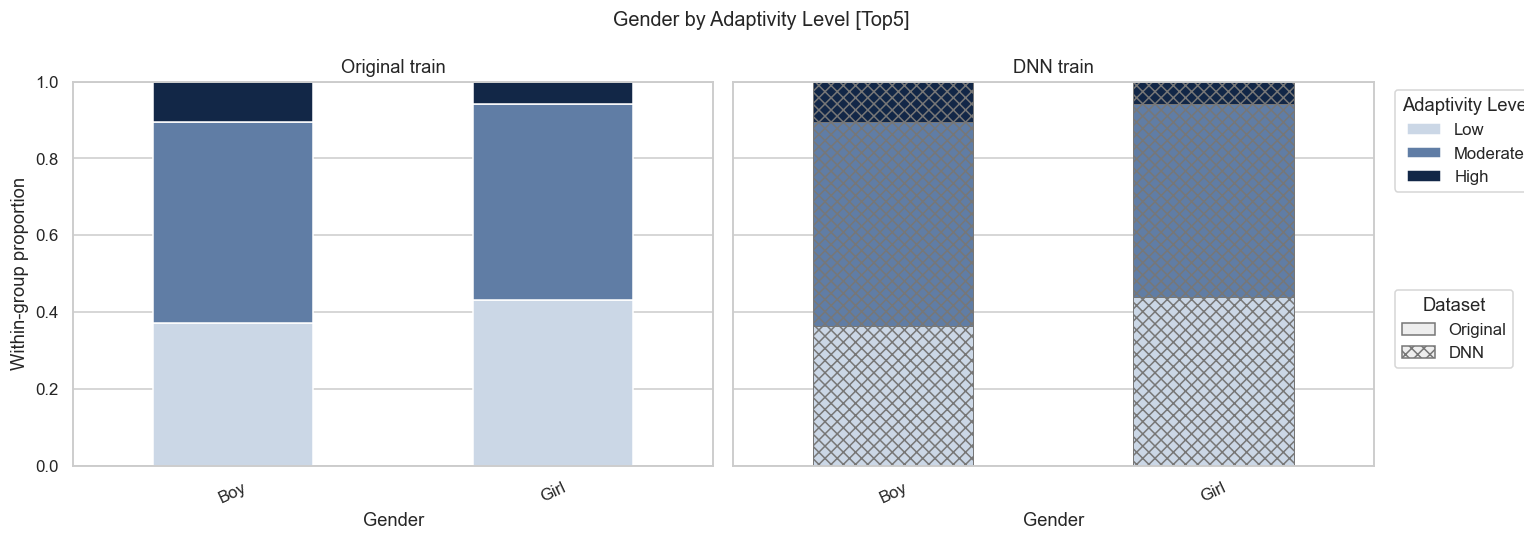

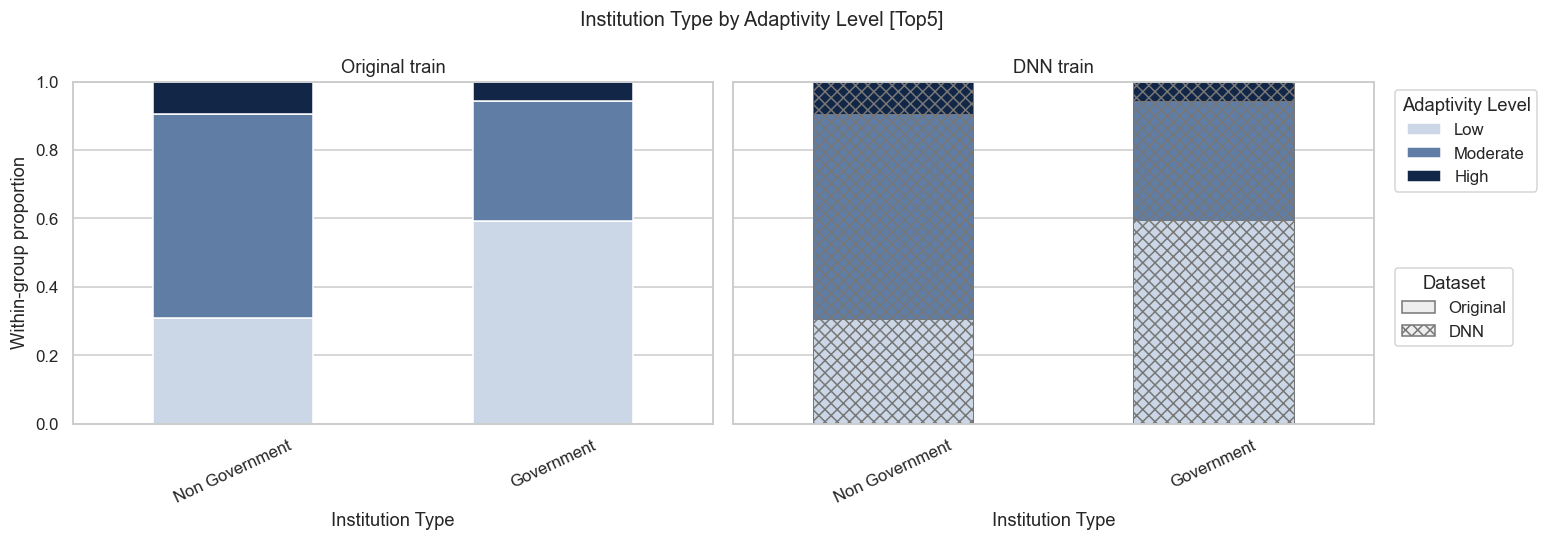

In [13]:
progress('primary',scenario='Top5')
PRIMARY['Top5']=fit_condition(TOP5_COLUMNS,PRIMARY_RATE,SEED)
save_primary('Top5',PRIMARY['Top5'])
plot_primary('Top5',PRIMARY['Top5'])


## 8. Classification Performance Across Scenarios

- **Purpose:** Compare classification performance under Complete, Mode, and DNN conditions on the same test rows.
- **Rationale:** Determine whether better reconstruction translates into better downstream prediction.
- **Key points:** Fix the parameters selected by complete-data CV and refit each model on the training data for each condition. Do not retune models separately for each condition.


,scenario,model,condition,accuracy,macro_f1,balanced_accuracy,accuracy_delta_pp,macro_f1_delta_pp,balanced_accuracy_delta_pp
15,All13,CatBoost,Complete,0.828729,0.806202,0.793568,0.000000,0.000000,0.000000
17,All13,CatBoost,DNN,0.823204,0.801490,0.799360,-0.552486,-0.471125,0.579196
16,All13,CatBoost,Mode,0.817680,0.770703,0.746956,-1.104972,-3.549905,-4.661151
21,All13,CatBoost_tuned,Complete,0.883978,0.875621,0.860835,0.000000,0.000000,0.000000
23,All13,CatBoost_tuned,DNN,0.861878,0.846236,0.837313,-2.209945,-2.938544,-2.352246
22,All13,CatBoost_tuned,Mode,0.842541,0.821663,0.810688,-4.143646,-5.395765,-5.014775
0,All13,Dummy,Complete,0.519337,0.227879,0.333333,0.000000,0.000000,0.000000
2,All13,Dummy,DNN,0.519337,0.227879,0.333333,0.000000,0.000000,0.000000
1,All13,Dummy,Mode,0.519337,0.227879,0.333333,0.000000,0.000000,0.000000
6,All13,KNN,Complete,0.743094,0.695543,0.693666,0.000000,0.000000,0.000000


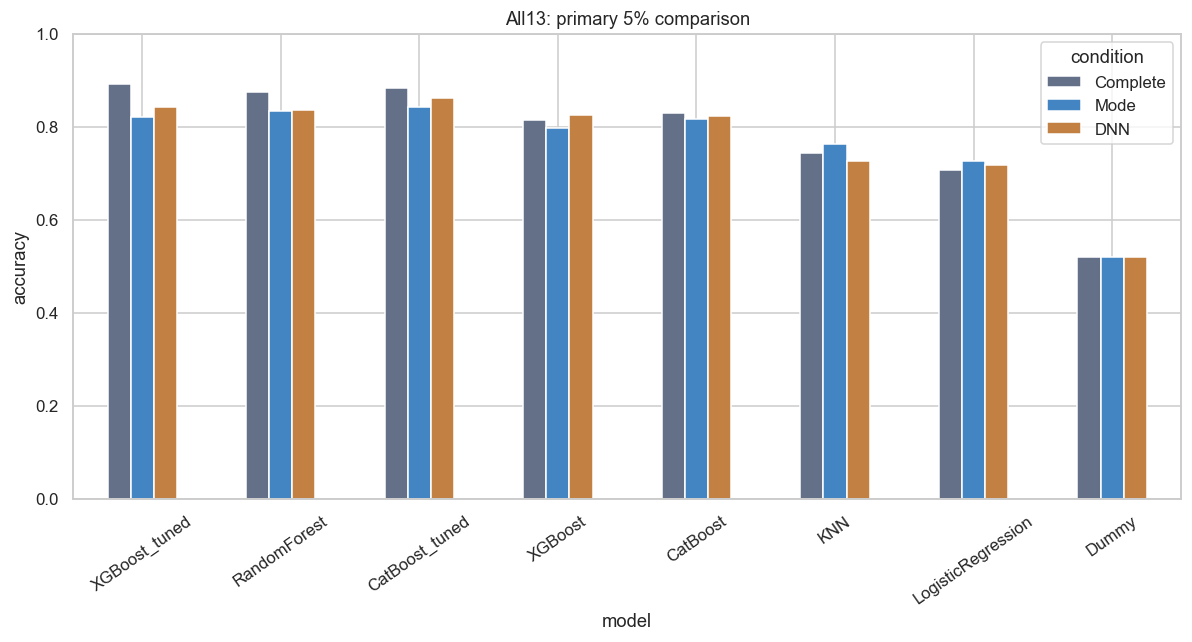

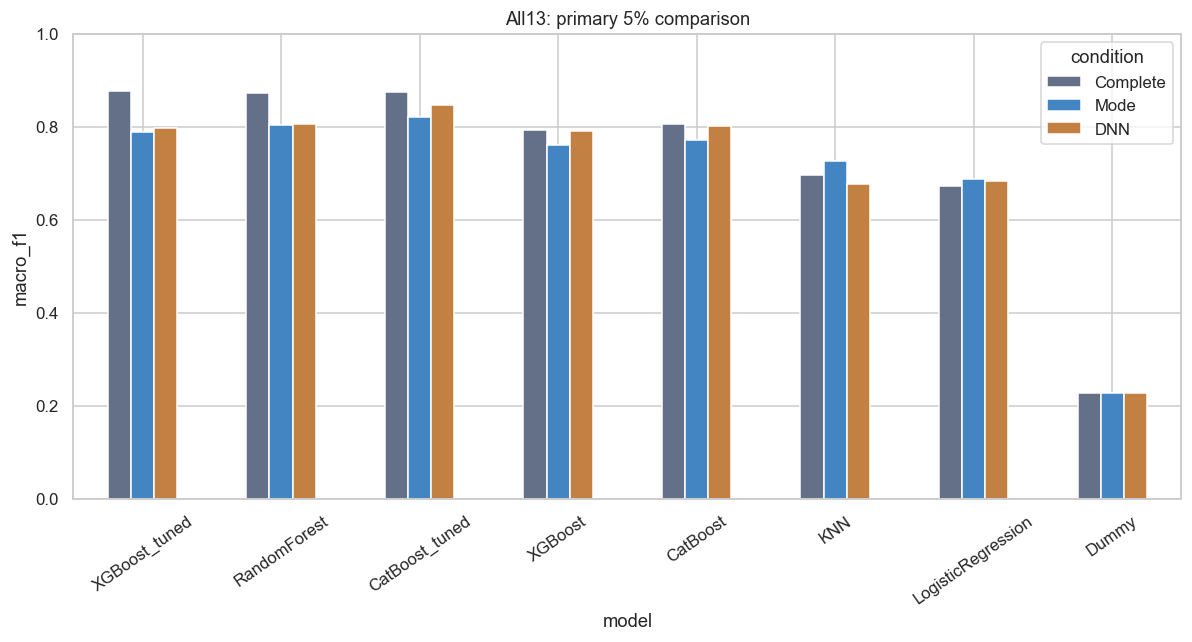

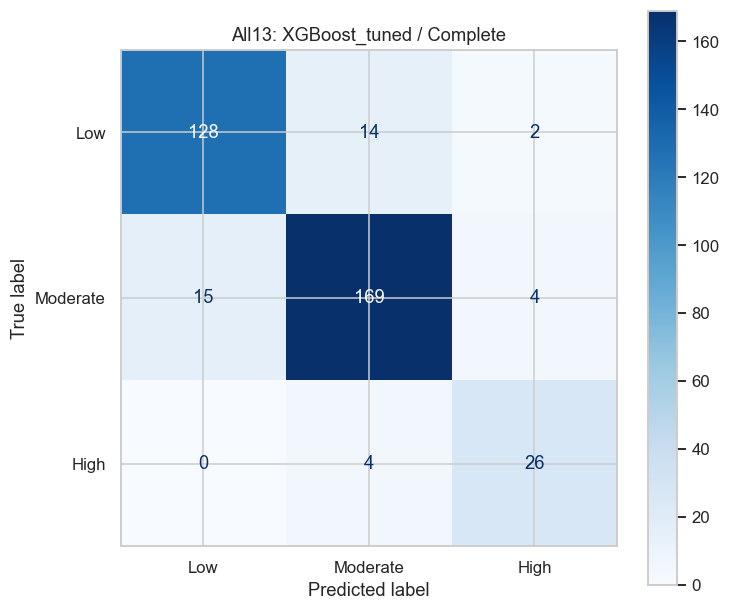

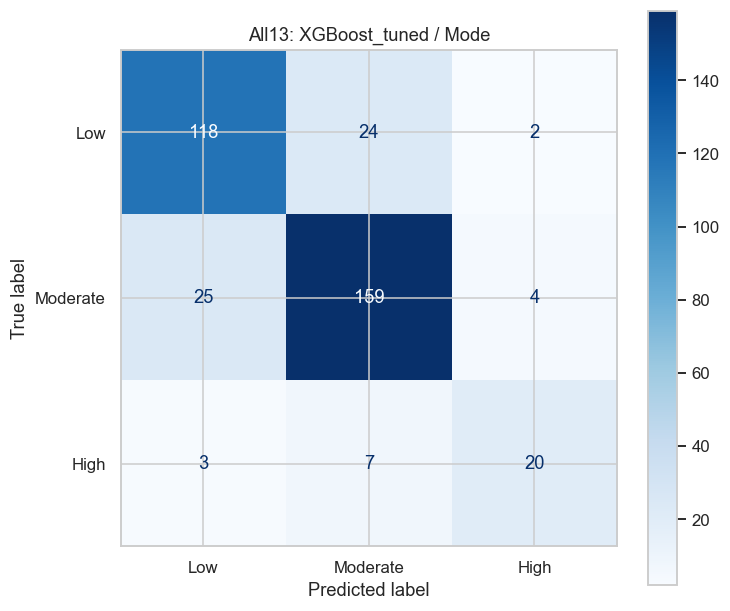

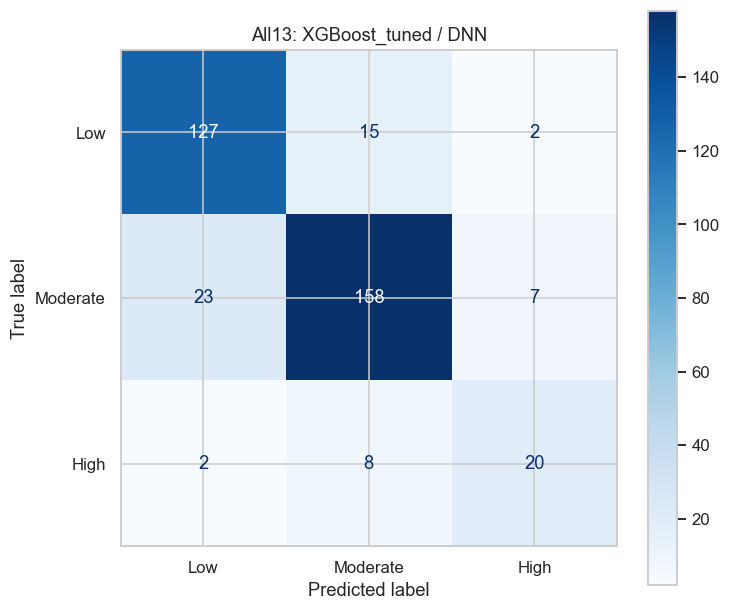

,scenario,model,condition,accuracy,macro_f1,balanced_accuracy,accuracy_delta_pp,macro_f1_delta_pp,balanced_accuracy_delta_pp
39,Top5,CatBoost,Complete,0.828729,0.806202,0.793568,0.000000,0.000000,0.000000
41,Top5,CatBoost,DNN,0.828729,0.799957,0.784771,0.000000,-0.624462,-0.879630
40,Top5,CatBoost,Mode,0.814917,0.789041,0.771572,-1.381215,-1.716063,-2.199567
45,Top5,CatBoost_tuned,Complete,0.883978,0.875621,0.860835,0.000000,0.000000,0.000000
47,Top5,CatBoost_tuned,DNN,0.872928,0.856239,0.836692,-1.104972,-1.938248,-2.414303
46,Top5,CatBoost_tuned,Mode,0.850829,0.830759,0.829137,-3.314917,-4.486223,-3.169819
24,Top5,Dummy,Complete,0.519337,0.227879,0.333333,0.000000,0.000000,0.000000
26,Top5,Dummy,DNN,0.519337,0.227879,0.333333,0.000000,0.000000,0.000000
25,Top5,Dummy,Mode,0.519337,0.227879,0.333333,0.000000,0.000000,0.000000
30,Top5,KNN,Complete,0.743094,0.695543,0.693666,0.000000,0.000000,0.000000


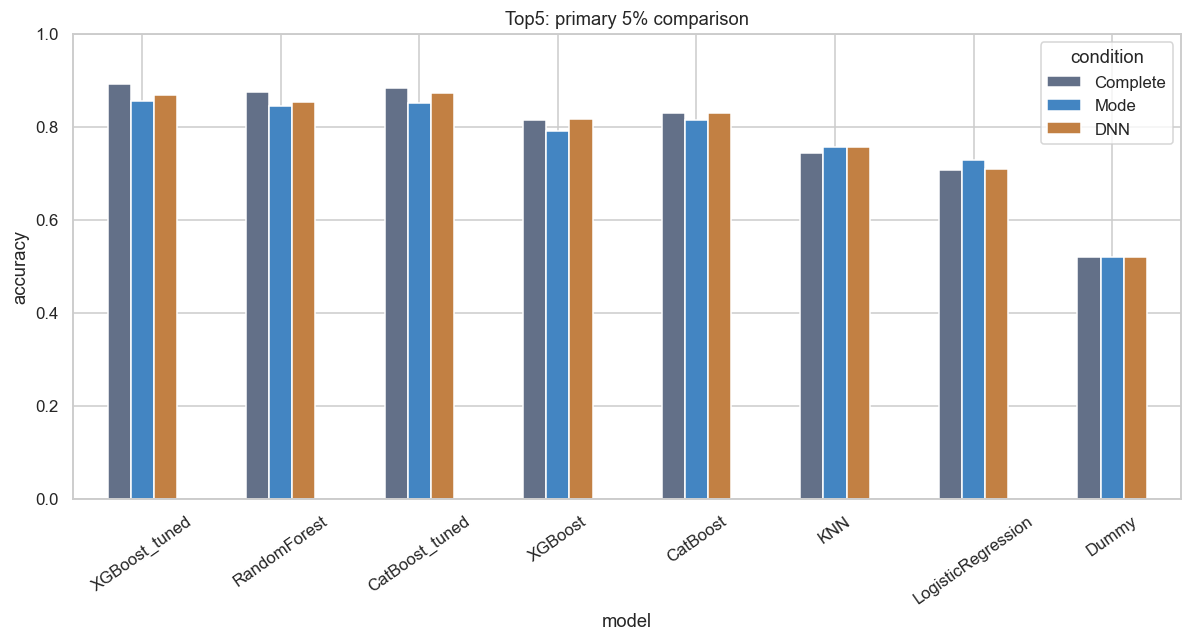

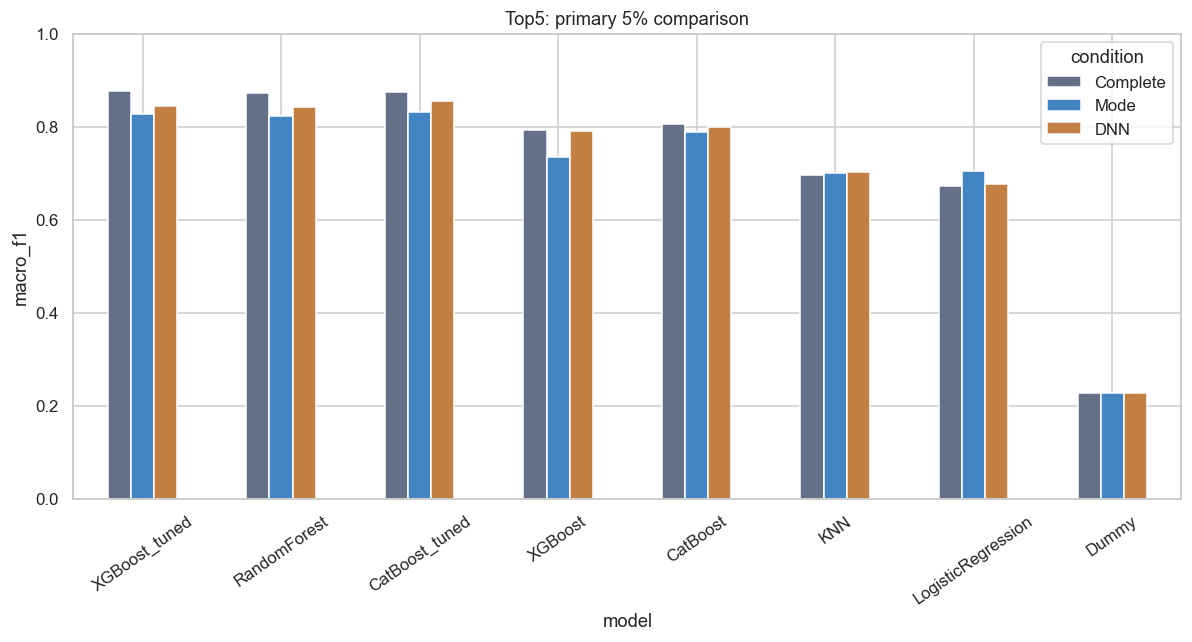

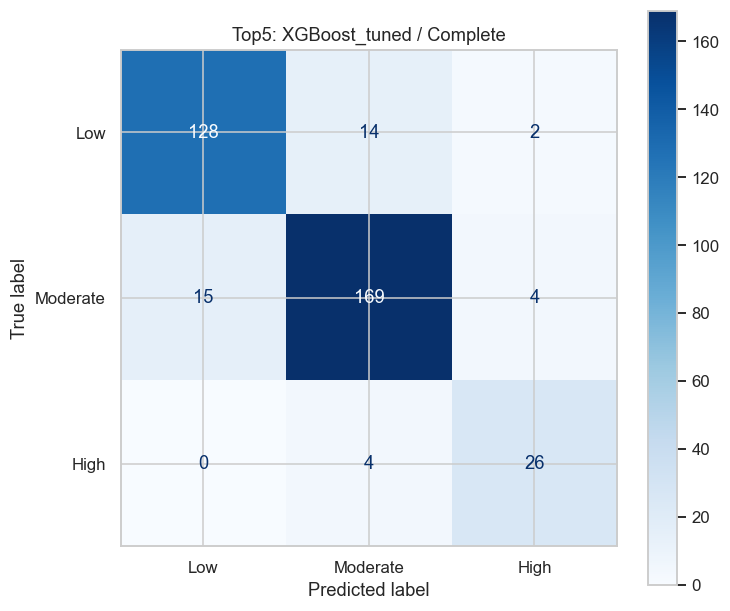

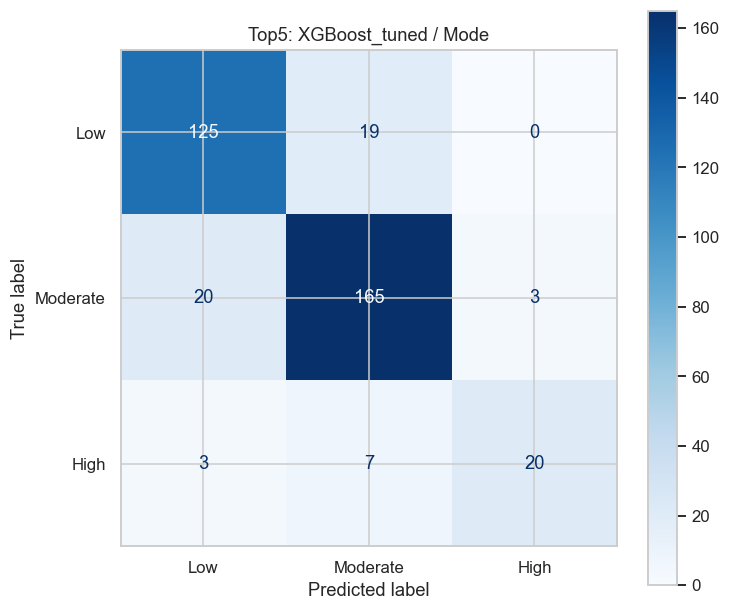

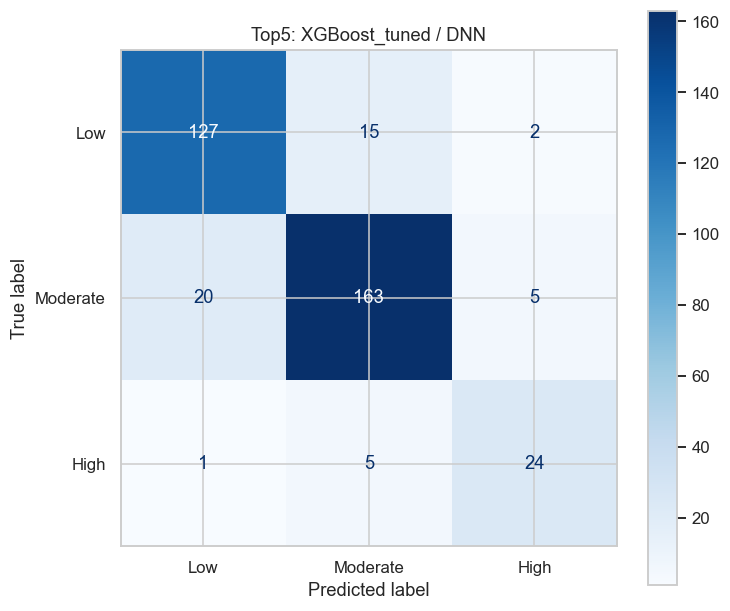

In [14]:
primary_rows=[];primary_reports=[]
for name,result in PRIMARY.items():
    for model_name,pipe in models.items():
        for method in ['Complete','Mode','DNN']:
            if method=='Complete':pred=clean_predictions[model_name]
            else:
                a,b=result[method]
                pred=clone(pipe).fit(a,y_train).predict(b)
            PRIMARY_PREDICTIONS[(name,model_name,method)]=pred
            primary_rows.append({'scenario':name,'model':model_name,'condition':method,**metrics(y_test,pred)})
    scores=pd.DataFrame(primary_rows).query('scenario==@name').copy()
    for metric in SCORING:
        scores[metric+'_delta_pp']=100*(scores[metric]-scores.model.map(clean_results[metric]))
    scores.to_csv(RESULTS/name/'classification_comparison.csv',index=False)
    display(scores.sort_values(['model','condition']))
    for metric in ['accuracy','macro_f1']:
        table=scores.pivot(index='model',columns='condition',values=metric).loc[cv_ranking.index,['Complete','Mode','DNN']]
        fig,ax=plt.subplots(figsize=(11,6))
        table.plot.bar(ax=ax,ylim=(0,1),color=[CONDITION_COLORS[c] for c in table.columns])
        ax.set(title=name+': primary 5% comparison',ylabel=metric);ax.tick_params(axis='x',rotation=35)
        savefig(name+'__11_model_comparison_'+metric)
    saved_pred=pd.DataFrame({'row_id':test_idx,'true_label':y_text.loc[test_idx].to_numpy()})
    for method in ['Complete','Mode','DNN']:
        pred=PRIMARY_PREDICTIONS[(name,BEST_NAME,method)]
        saved_pred[method]=label_encoder.inverse_transform(pred)
        report=classification_report(y_test,pred,labels=label_encoder.transform(ADAPTIVITY_ORDER),
            target_names=ADAPTIVITY_ORDER,output_dict=True,zero_division=0)
        primary_reports.append(pd.DataFrame(report).T.assign(scenario=name,condition=method))
        fig,ax=plt.subplots(figsize=(7,6))
        ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=label_encoder.transform(ADAPTIVITY_ORDER),
                    display_labels=ADAPTIVITY_ORDER,ax=ax,cmap='Blues')
        ax.set_title(name+': '+BEST_NAME+' / '+method)
        savefig(name+'__12_confusion_'+method.lower())
    saved_pred.to_csv(RESULTS/name/'test_predictions.csv',index=False)
primary_results=pd.DataFrame(primary_rows)
primary_results.to_csv(RESULTS/'primary_classification_comparison.csv',index=False)
pd.concat(primary_reports).to_csv(RESULTS/'primary_classification_reports.csv',index_label='class_or_metric')


## 9. Repeated Evaluation Across Missingness Rates and Masks

- **Purpose:** Evaluate both scenarios at 5%, 15%, and 30% missingness using five mask seeds.
- **Rationale:** Check whether the results depend on a single selection of missing locations.
- **Key points:** Compare Mode and DNN using identical masks. Means and standard deviations reflect variation in missing locations under a fixed data split.


In [15]:
def evaluate_selected(result,name,rate,mask_seed):
    rows=[];quality=[]
    for method in ['Mode','DNN']:
        a,b=result[method]
        pred=clone(models[BEST_NAME]).fit(a,y_train).predict(b)
        rows.append({'scenario':name,'rate':rate,'mask_seed':mask_seed,'method':method,
            'n_masked':int(result['mask'].to_numpy().sum()),'all_cell_rate':float(result['mask'].to_numpy().mean()),
            'n_masked_train':int(result['mask'].loc[train_idx].to_numpy().sum()),
            'n_masked_test':int(result['mask'].loc[test_idx].to_numpy().sum()),
            **metrics(y_test,pred)})
        qr=imputation_scores(X_test,b,result['mask'],method,'test',result['columns'])
        for r in qr:r.update(scenario=name,rate=rate,mask_seed=mask_seed)
        quality.extend(qr)
    return rows,quality

def repeat_scenario(name):
    path=RESULTS/name/'repeated_scores.csv';qpath=RESULTS/name/'repeated_imputation_quality.csv'
    rows=[]
    quality=[]
    for rate in MISSING_RATES:
        for mask_seed in MASK_SEEDS:
            progress('repeated',scenario=name,rate=rate,mask_seed=mask_seed,completed_pairs=len(rows)//2)
            result=PRIMARY[name] if rate==PRIMARY_RATE and mask_seed==SEED else fit_condition(SCENARIOS[name],rate,mask_seed)
            scores,qr=evaluate_selected(result,name,rate,mask_seed)
            rows.extend(scores);quality.extend(qr)
            pd.DataFrame(rows).to_csv(path,index=False)
            pd.DataFrame(quality).to_csv(qpath,index=False)
            print(name,rate,mask_seed,'completed',flush=True)
    return pd.DataFrame(rows)


### 9.1 All13 Repeated Evaluation

- **Purpose:** Evaluate 15 missingness settings across all 13 features.
- **Rationale:** Examine performance degradation and imputation benefits as the missingness rate increases.
- **Key points:** Reuse the primary 5%, seed-42 condition and report the mean and standard deviation across five masks at each rate.


In [16]:
all13_repeated=repeat_scenario('All13')
display(all13_repeated.groupby(['rate','method'])[['accuracy','macro_f1']].agg(['mean','std']))


All13 0.05 42 completed
All13 0.05 43 completed
All13 0.05 44 completed
All13 0.05 45 completed
All13 0.05 46 completed
All13 0.15 42 completed
All13 0.15 43 completed
All13 0.15 44 completed
All13 0.15 45 completed
All13 0.15 46 completed
All13 0.3 42 completed
All13 0.3 43 completed
All13 0.3 44 completed
All13 0.3 45 completed
All13 0.3 46 completed


accuracy            macro_f1          
                 mean       std      mean       std
rate method                                        
0.05 DNN     0.858564  0.018051  0.834827  0.027061
     Mode    0.845856  0.020524  0.824206  0.021785
0.15 DNN     0.785083  0.018261  0.754801  0.023420
     Mode    0.755249  0.008866  0.701266  0.012739
0.30 DNN     0.690055  0.031702  0.631235  0.031233
     Mode    0.684530  0.015055  0.611870  0.031759

### 9.2 Top5 Repeated Evaluation

- **Purpose:** Evaluate 15 missingness settings for the fixed Top5 features.
- **Rationale:** Assess the stability of results when important features are damaged.
- **Key points:** Do not reselect Top5 for each mask. The total number of missing cells differs from All13.


In [17]:
top5_repeated=repeat_scenario('Top5')
display(top5_repeated.groupby(['rate','method'])[['accuracy','macro_f1']].agg(['mean','std']))


Top5 0.05 42 completed
Top5 0.05 43 completed
Top5 0.05 44 completed
Top5 0.05 45 completed
Top5 0.05 46 completed
Top5 0.15 42 completed
Top5 0.15 43 completed
Top5 0.15 44 completed
Top5 0.15 45 completed
Top5 0.15 46 completed
Top5 0.3 42 completed
Top5 0.3 43 completed
Top5 0.3 44 completed
Top5 0.3 45 completed
Top5 0.3 46 completed


accuracy            macro_f1          
                 mean       std      mean       std
rate method                                        
0.05 DNN     0.870718  0.009036  0.848493  0.023658
     Mode    0.864088  0.005989  0.842303  0.013407
0.15 DNN     0.820442  0.024938  0.786978  0.035610
     Mode    0.812707  0.013161  0.776186  0.020115
0.30 DNN     0.782320  0.033401  0.751653  0.044898
     Mode    0.765746  0.014140  0.722992  0.026998

accuracy            macro_f1            \
                          mean       std      mean       std   
scenario rate method                                           
All13    0.05 DNN     0.858564  0.018051  0.834827  0.027061   
              Mode    0.845856  0.020524  0.824206  0.021785   
         0.15 DNN     0.785083  0.018261  0.754801  0.023420   
              Mode    0.755249  0.008866  0.701266  0.012739   
         0.30 DNN     0.690055  0.031702  0.631235  0.031233   
              Mode    0.684530  0.015055  0.611870  0.031759   
Top5     0.05 DNN     0.870718  0.009036  0.848493  0.023658   
              Mode    0.864088  0.005989  0.842303  0.013407   
         0.15 DNN     0.820442  0.024938  0.786978  0.035610   
              Mode    0.812707  0.013161  0.776186  0.020115   
         0.30 DNN     0.782320  0.033401  0.751653  0.044898   
              Mode    0.765746  0.014140  0.722992  0.026998   

                     balanced_accuracy            
                                  mean       std  
scenario rate method                              
All13    0.05 DNN             0.831367  0.028034  
              Mode            0.818067  0.028053  
         0.15 DNN             0.748146  0.028418  
              Mode            0.687719  0.025527  
         0.30 DNN             0.620181  0.030982  
              Mode            0.605646  0.033773  
Top5     0.05 DNN             0.844204  0.032616  
              Mode            0.837539  0.025372  
         0.15 DNN             0.783296  0.030524  
              Mode            0.761332  0.028837  
         0.30 DNN             0.743505  0.041833  
              Mode            0.708180  0.024777

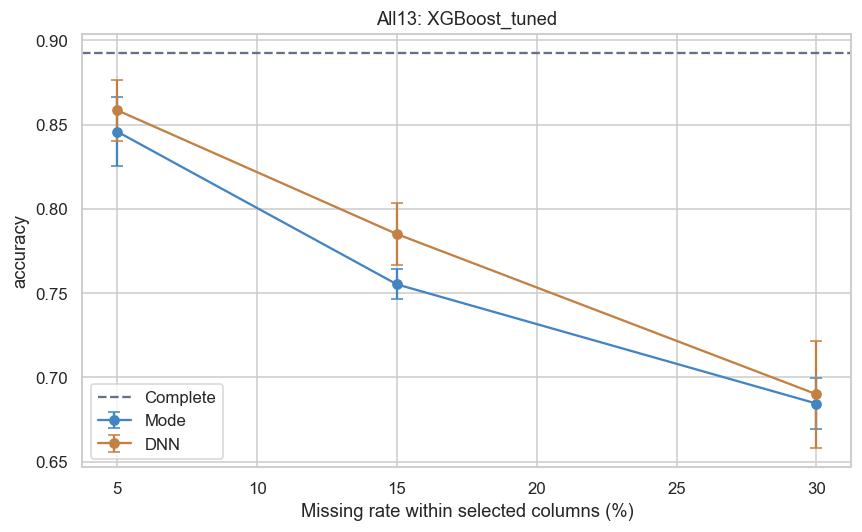

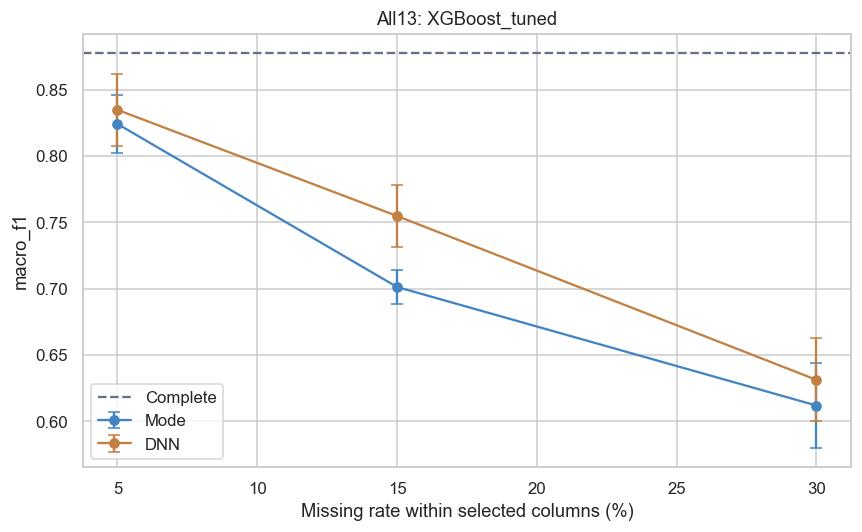

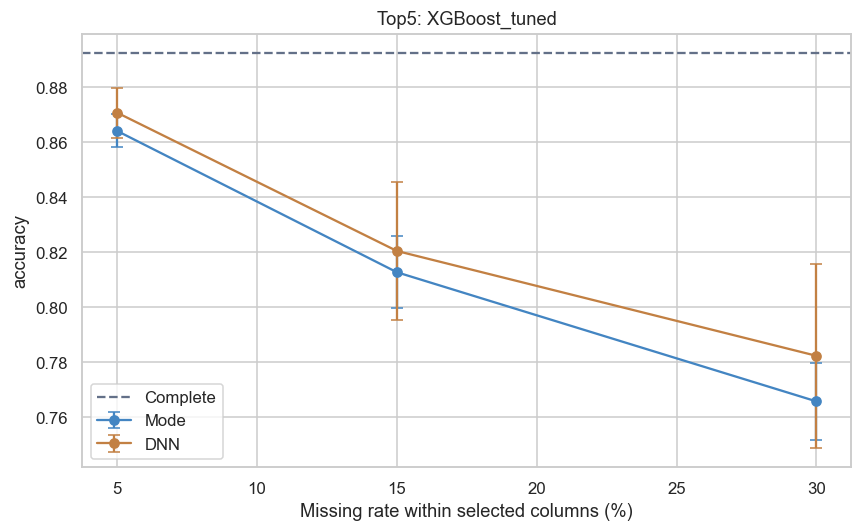

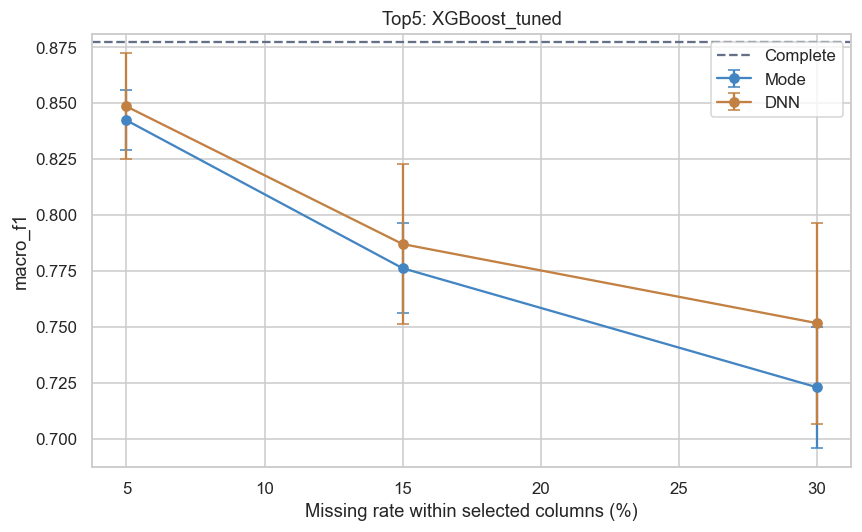

accuracy            macro_f1          
                   mean       std      mean       std
scenario rate                                        
All13    0.05  1.270718  2.412980  1.062051  2.247055
         0.15  2.983425  1.579666  5.353575  2.084504
         0.30  0.552486  2.569209  1.936487  1.537899
Top5     0.05  0.662983  0.572830  0.618978  1.940903
         0.15  0.773481  1.762336  1.079219  2.355695
         0.30  1.657459  2.823902  2.866095  2.973188

In [18]:
robust_results=pd.concat([all13_repeated,top5_repeated],ignore_index=True)
robust_results.to_csv(RESULTS/'robustness_all_runs.csv',index=False)
robust_summary=robust_results.groupby(['scenario','rate','method'])[list(SCORING)].agg(['mean','std'])
display(robust_summary);robust_summary.to_csv(RESULTS/'robustness_summary.csv')
for name in SCENARIOS:
    for metric in ['accuracy','macro_f1']:
        fig,ax=plt.subplots(figsize=(8,5))
        for method in ['Mode','DNN']:
            z=robust_results.query('scenario==@name and method==@method').groupby('rate')[metric].agg(['mean','std'])
            ax.errorbar(z.index*100,z['mean'],yerr=z['std'],marker='o',capsize=4,color=CONDITION_COLORS[method],label=method)
        ax.axhline(clean_results.loc[BEST_NAME,metric],ls='--',color=CONDITION_COLORS['Complete'],label='Complete')
        ax.set(title=name+': '+BEST_NAME,xlabel='Missing rate within selected columns (%)',ylabel=metric);ax.legend()
        savefig(name+'__13_rate_sensitivity_'+metric)
paired=robust_results.pivot(index=['scenario','rate','mask_seed'],columns='method',values=['accuracy','macro_f1'])
paired_delta=pd.DataFrame({metric:100*(paired[(metric,'DNN')]-paired[(metric,'Mode')]) for metric in ['accuracy','macro_f1']})
display(paired_delta.groupby(['scenario','rate']).agg(['mean','std']))
paired_delta.to_csv(RESULTS/'paired_mask_differences_pp.csv')


## 10. Equal Missing-Cell Budget

- **Purpose:** Match the total number of missing cells at 780 for All13 at 5% and Top5 at approximately 13%.
- **Rationale:** Reduce the influence of unequal missing-cell counts when comparing feature subsets.
- **Key points:** Mask 156 cells per Top5 feature. Even with equal totals, the concentration of missingness and the train/test missing-cell counts may differ.


Matched Top5 42 completed
Matched Top5 43 completed
Matched Top5 44 completed
Matched Top5 45 completed
Matched Top5 46 completed


accuracy            macro_f1            \
                                    mean       std      mean       std   
budget_condition        method                                           
All13: 5% per column    DNN     0.858564  0.018051  0.834827  0.027061   
                        Mode    0.845856  0.020524  0.824206  0.021785   
Top5: matched 780 cells DNN     0.829282  0.008379  0.793360  0.009734   
                        Mode    0.819890  0.011119  0.784488  0.016699   

                               balanced_accuracy            
                                            mean       std  
budget_condition        method                              
All13: 5% per column    DNN             0.831367  0.028034  
                        Mode            0.818067  0.028053  
Top5: matched 780 cells DNN             0.792354  0.011322  
                        Mode            0.772411  0.024635

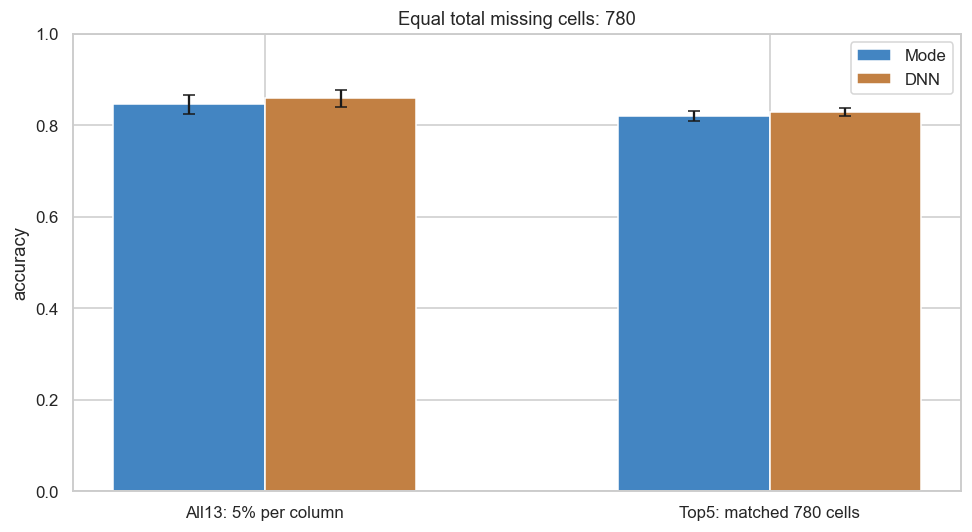

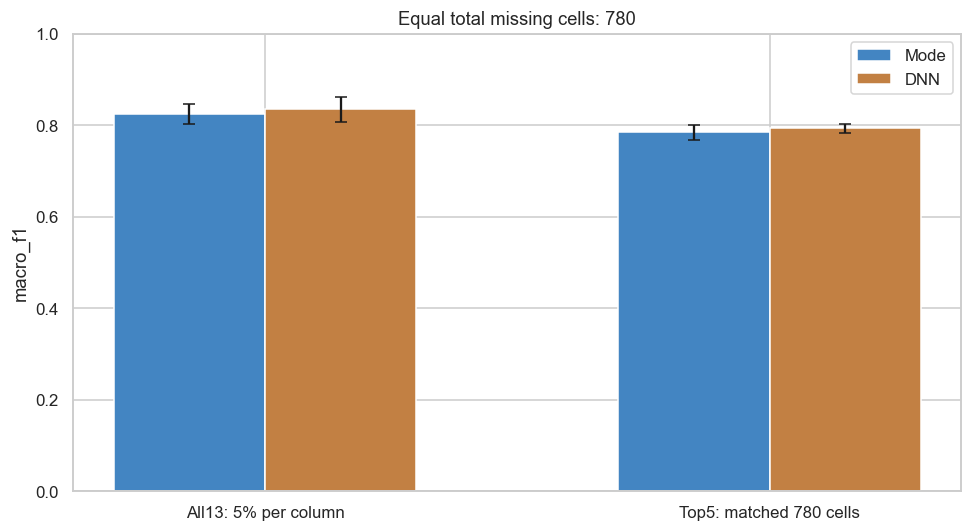

In [19]:
MATCHED_TOTAL=int(PRIMARY['All13']['mask'].to_numpy().sum())
MATCHED_PER_COLUMN=MATCHED_TOTAL//len(TOP5_COLUMNS)
assert MATCHED_PER_COLUMN*len(TOP5_COLUMNS)==MATCHED_TOTAL
matched_path=RESULTS/'matched_top5_runs.csv'
matched_rows=[]
for mask_seed in MASK_SEEDS:
    progress('matched_budget',mask_seed=mask_seed,completed_pairs=len(matched_rows)//2)
    result=fit_condition(TOP5_COLUMNS,MATCHED_PER_COLUMN/len(X),mask_seed,MATCHED_PER_COLUMN)
    assert int(result['mask'].to_numpy().sum())==MATCHED_TOTAL
    scores,_=evaluate_selected(result,'Top5_matched',MATCHED_PER_COLUMN/len(X),mask_seed)
    matched_rows.extend(scores);pd.DataFrame(matched_rows).to_csv(matched_path,index=False)
    print('Matched Top5',mask_seed,'completed',flush=True)
matched_all13=all13_repeated[np.isclose(all13_repeated.rate,PRIMARY_RATE)].copy()
matched_all13['budget_condition']='All13: 5% per column'
matched_top5=pd.DataFrame(matched_rows);matched_top5['budget_condition']='Top5: matched 780 cells'
matched_results=pd.concat([matched_all13,matched_top5],ignore_index=True)
assert matched_results.n_masked.eq(MATCHED_TOTAL).all()
matched_results.to_csv(RESULTS/'matched_budget_all_runs.csv',index=False)
matched_summary=matched_results.groupby(['budget_condition','method'])[list(SCORING)].agg(['mean','std'])
display(matched_summary);matched_summary.to_csv(RESULTS/'matched_budget_summary.csv')
for metric in ['accuracy','macro_f1']:
    fig,ax=plt.subplots(figsize=(9,5))
    labels=['All13: 5% per column','Top5: matched 780 cells'];positions=np.arange(2)
    for j,method in enumerate(['Mode','DNN']):
        z=matched_results.query('method==@method').groupby('budget_condition')[metric].agg(['mean','std']).reindex(labels)
        ax.bar(positions+(j-.5)*.3,z['mean'],width=.3,yerr=z['std'],capsize=4,
               label=method,color=CONDITION_COLORS[method],edgecolor='white')
    ax.set_xticks(positions,labels);ax.set(title='Equal total missing cells: 780',ylabel=metric,ylim=(0,1));ax.legend()
    savefig('14_matched_budget_'+metric)


## 11. Paired Bootstrap for the Primary 5% Conditions

- **Purpose:** Resample the same test rows jointly to calculate 95% intervals for performance differences.
- **Rationale:** Assess whether the observed differences are large relative to their uncertainty.
- **Key points:** An interval containing zero does not establish superiority. These intervals are conditional on the fixed models, split, and masks, and are also affected by repeated input profiles.


In [20]:
yt=y_test.to_numpy();boot_rows=[]
bootstrap_indices=np.random.default_rng(SEED).integers(0,len(yt),(BOOTSTRAPS,len(yt)))
for name in SCENARIOS:
    for left,right in [('DNN','Complete'),('Mode','Complete'),('DNN','Mode')]:
        pa=PRIMARY_PREDICTIONS[(name,BEST_NAME,left)];pb=PRIMARY_PREDICTIONS[(name,BEST_NAME,right)]
        diffs=[]
        for ids in bootstrap_indices:
            diffs.append([accuracy_score(yt[ids],pa[ids])-accuracy_score(yt[ids],pb[ids]),
                f1_score(yt[ids],pa[ids],labels=np.arange(3),average='macro',zero_division=0)-
                f1_score(yt[ids],pb[ids],labels=np.arange(3),average='macro',zero_division=0)])
        for j,metric in enumerate(['accuracy','macro_f1']):
            low,high=100*np.quantile(np.array(diffs)[:,j],[.025,.975])
            boot_rows.append({'scenario':name,'contrast':left+' - '+right,'metric':metric,
                'delta_pp':100*(metrics(yt,pa)[metric]-metrics(yt,pb)[metric]),'CI95_low_pp':low,'CI95_high_pp':high})
bootstrap_results=pd.DataFrame(boot_rows)
display(bootstrap_results);bootstrap_results.to_csv(RESULTS/'primary_paired_bootstrap.csv',index=False)


,scenario,contrast,metric,delta_pp,CI95_low_pp,CI95_high_pp
0,All13,DNN - Complete,accuracy,-4.972376,-8.011050,-1.933702
1,All13,DNN - Complete,macro_f1,-7.986210,-12.497200,-3.642722
2,All13,Mode - Complete,accuracy,-7.182320,-10.220994,-4.143646
3,All13,Mode - Complete,macro_f1,-8.756014,-13.553295,-4.893191
4,All13,DNN - Mode,accuracy,2.209945,-1.104972,5.531768
5,All13,DNN - Mode,macro_f1,0.769804,-3.803766,5.420204
6,Top5,DNN - Complete,accuracy,-2.486188,-4.143646,-1.104972
7,Top5,DNN - Complete,macro_f1,-3.219154,-5.901001,-1.026266
8,Top5,Mode - Complete,accuracy,-3.591160,-6.353591,-0.828729
9,Top5,Mode - Complete,macro_f1,-5.014510,-10.364320,0.003181


## 12. Profile-Group Validation

- **Purpose:** Group identical input profiles to prevent profile overlap between training and test sets.
- **Rationale:** Distinguish prediction on previously seen patterns from prediction on new input combinations.
- **Key points:** Select a model separately using group CV and evaluate only All13 at 5%. Both the split and selected model differ from the original evaluation, so the entire performance gap cannot be attributed to duplicates.


In [21]:
progress('group_validation')
MISSING_COLUMNS=ALL_COLUMNS
primary_mask=PRIMARY['All13']['mask']
candidates=[]
for ga,gb in GroupShuffleSplit(n_splits=100,test_size=.30,random_state=SEED).split(X,y,groups=profile_id):
    if y.iloc[ga].nunique()<3 or y.iloc[gb].nunique()<3: continue
    proportions=y.iloc[gb].value_counts(normalize=True).reindex(range(3),fill_value=0)
    overall=y.value_counts(normalize=True).reindex(range(3),fill_value=0)
    balance=abs(len(gb)/len(X)-.30)+float(abs(proportions-overall).sum())
    candidates.append((balance,ga,gb))
_,ga,gb=min(candidates,key=lambda z:z[0])
assert set(profile_id.iloc[ga]).isdisjoint(set(profile_id.iloc[gb]))
gxtr,gxte=X.iloc[ga],X.iloc[gb]; gytr,gyte=y.iloc[ga],y.iloc[gb]
gcv=list(StratifiedGroupKFold(5,shuffle=True,random_state=SEED).split(gxtr,gytr,groups=profile_id.iloc[ga]))
grows=[]
for name in ['LogisticRegression','KNN','RandomForest','XGBoost','CatBoost']:
    s=cross_validate(models[name],gxtr,gytr,cv=gcv,scoring=SCORING,n_jobs=1)
    grows.append({'model':name,'cv_macro_f1':s['test_macro_f1'].mean(),'cv_accuracy':s['test_accuracy'].mean()})
group_cv=pd.DataFrame(grows).sort_values('cv_macro_f1',ascending=False)
GROUP_BEST=group_cv.iloc[0]['model']; display(group_cv)
gmask=primary_mask
gma,gmb=mode_impute_pair(gxtr.mask(gmask.loc[gxtr.index],np.nan),gxte.mask(gmask.loc[gxte.index],np.nan))
gimp=CategoricalDNNImputer(MISSING_COLUMNS,SEED,DNN_EPOCHS,DNN_PATIENCE).fit(gxtr.mask(gmask.loc[gxtr.index],np.nan))
gda=gimp.transform(gxtr.mask(gmask.loc[gxtr.index],np.nan)); gdb=gimp.transform(gxte.mask(gmask.loc[gxte.index],np.nan))
group_rows=[]
for condition,a,b in [('Complete',gxtr,gxte),('Mode',gma,gmb),('DNN',gda,gdb)]:
    pred=clone(models[GROUP_BEST]).fit(a,gytr).predict(b)
    group_rows.append({'model':GROUP_BEST,'condition':condition,'n_train':len(ga),'n_test':len(gb),**metrics(gyte,pred)})
group_results=pd.DataFrame(group_rows)
display(group_results)
group_cv.to_csv(RESULTS/'profile_group_cv.csv',index=False)
group_results.to_csv(RESULTS/'profile_group_test.csv',index=False)
pd.DataFrame({'row_id':X.index,'profile_group':profile_id,
              'split':np.where(X.index.isin(gxtr.index),'train','test')}).to_csv(RESULTS/'profile_group_manifest.csv',index=False)


,model,cv_macro_f1,cv_accuracy
0,LogisticRegression,0.563443,0.580996
4,CatBoost,0.528764,0.596134
2,RandomForest,0.470063,0.536872
3,XGBoost,0.447467,0.533379
1,KNN,0.419677,0.533427


,model,condition,n_train,n_test,accuracy,macro_f1,balanced_accuracy
0,LogisticRegression,Complete,846,359,0.696379,0.611098,0.617984
1,LogisticRegression,Mode,846,359,0.682451,0.625273,0.648741
2,LogisticRegression,DNN,846,359,0.688022,0.606185,0.612146


## 13. Results Summary

- **Purpose:** Summarize classification scores, reconstruction accuracy, repeated evaluations, and equal-budget comparisons.
- **Rationale:** Connect individual plots to consistent conclusions and their scope of interpretation.
- **Key points:** Distinguish the single primary run from averages across random masks. The final Findings combine results from the main and supplementary studies.


In [ ]:
summary=['# Supplementary Study Results','',f'Model selected by main-study CV: {BEST_NAME}. Training/test rows: {len(X_train)}/{len(X_test)}.',
         'Top5 (permutation importance within training): '+', '.join(TOP5_COLUMNS),
         f'Complete data: accuracy={clean_results.loc[BEST_NAME,"accuracy"]:.4f}, macro-F1={clean_results.loc[BEST_NAME,"macro_f1"]:.4f}.','']
for name in SCENARIOS:
    z=primary_results.query('scenario==@name and model==@BEST_NAME').set_index('condition')
    n=int(PRIMARY[name]['mask'].to_numpy().sum())
    summary.extend([f'## {name}: 5% missingness per selected feature',f'Selected features: {len(SCENARIOS[name])}; masked cells: {n}; {100*n/X.size:.3f}% of all input cells.'])
    for method in ['Complete','Mode','DNN']:
        r=z.loc[method];summary.append(f'- {method}: accuracy={r.accuracy:.4f}, macro-F1={r.macro_f1:.4f}, balanced accuracy={r.balanced_accuracy:.4f}.')
    q=PRIMARY[name]['quality'].query("split=='test'")
    for method,g in q.groupby('method'):
        recovery=np.average(g.masked_accuracy,weights=g.n_masked)
        summary.append(f'- {method} reconstruction accuracy on masked test cells: {recovery:.4f}.')
    for _,r in bootstrap_results.query('scenario==@name and contrast=="DNN - Mode"').iterrows():
        claim='The interval includes zero, so superiority is not established.' if r.CI95_low_pp<=0<=r.CI95_high_pp else 'A directional difference was observed under this fixed condition.'
        summary.append(f'- DNN−Mode {r.metric}: {r.delta_pp:+.2f}pp, 95% bootstrap [{r.CI95_low_pp:.2f}, {r.CI95_high_pp:.2f}]pp. {claim}')
    summary.append('')
summary.extend(['## Repeated Evaluation: Mean ± Standard Deviation Across Five Masks'])
for (name,rate,method),g in robust_results.groupby(['scenario','rate','method']):
    summary.append(f'- {name}, {rate:.0%}, {method}: accuracy {g.accuracy.mean():.4f} ± {g.accuracy.std():.4f}; macro-F1 {g.macro_f1.mean():.4f} ± {g.macro_f1.std():.4f}.')
summary.extend(['','## Equal Missing-Cell Budget Comparison',f'All13 at 5% and Top5 at {MATCHED_PER_COLUMN} cells per feature ({MATCHED_PER_COLUMN/len(X):.3%}) both have {MATCHED_TOTAL} masked cells.'])
for (condition,method),g in matched_results.groupby(['budget_condition','method']):
    summary.append(f'- {condition}, {method}: accuracy {g.accuracy.mean():.4f} ± {g.accuracy.std():.4f}; macro-F1 {g.macro_f1.mean():.4f} ± {g.macro_f1.std():.4f}.')
summary.extend(['','## Limitations of Interpretation',
    'All13 at 5% and Top5 at 5% have different numbers of missing cells. Per-feature missingness rates differ from the overall missing-cell rate.',
    'The equal-budget comparison still differs in missingness concentration and does not isolate the causal effect of feature importance.',
    'Top5 reflects importance for the specific CV-selected model and internal training validation subset. Rankings may change with other models or samples.',
    'Repeated-run standard deviations reflect only variation in missing locations. MAR/MNAR, data-entry errors, and external-data validation were not evaluated.',
    'Softmax confidence is not actual reconstruction accuracy. Overall distributional similarity alone does not establish successful imputation.',
    f'There are {int(df.duplicated().sum())} duplicate rows beyond the first occurrences and {profile_id.nunique()} unique input profiles; profile-group validation is therefore also reported.'])
for _,r in group_results.iterrows():summary.append(f'- Profile-group All13 {r.condition}: {r.model}, accuracy={r.accuracy:.4f}, macro-F1={r.macro_f1:.4f}.')
report='\n\n'.join(summary)
display(Markdown(report));(RESULTS/'results_summary.md').write_text(report,encoding='utf-8')
env={'python':sys.version,'packages':versions,'seed':SEED,'mask_seeds':MASK_SEEDS,'rates':MISSING_RATES,
     'scenarios':SCENARIOS,'top5_selection_model':BEST_NAME,'top5_selection_source':'permutation importance on validation subset within training',
     'n_trials':N_TRIALS,'dnn_epochs':DNN_EPOCHS,'dnn_patience':DNN_PATIENCE,
     'matched_total_cells':MATCHED_TOTAL,'matched_top5_cells_per_column':MATCHED_PER_COLUMN}
(RESULTS/'environment.json').write_text(json.dumps(env,ensure_ascii=False,indent=2),encoding='utf-8')

# Validate the key data, masking, and training contracts.
assert TARGET not in ALL_COLUMNS and len(ALL_COLUMNS)==13 and len(TOP5_COLUMNS)==5
assert len(primary_results)==len(models)*3*2
assert len(robust_results)==2*3*5*2
assert len(matched_results)==5*2*2
for name,r in PRIMARY.items():
    mask=r['mask'];assert set(mask.columns)==set(FEATURES)
    assert mask.to_numpy().sum()==60*len(SCENARIOS[name])
    for method in ['Mode','DNN']:
        for filled,truth,missing in zip(r[method],[X_train,X_test],[r['missing_train'],r['missing_test']]):
            assert not filled.isna().any().any()
            assert filled.where(missing.notna()).equals(truth.where(missing.notna()))
assert matched_results.n_masked.eq(MATCHED_TOTAL).all()
verification={'status':'passed','primary_scores':len(primary_results),'repeated_scores':len(robust_results),
    'matched_scores':len(matched_results),'all13_primary_cells':int(PRIMARY['All13']['mask'].to_numpy().sum()),
    'top5_primary_cells':int(PRIMARY['Top5']['mask'].to_numpy().sum()),'matched_cells':MATCHED_TOTAL,
    'group_profile_overlap':0,'observed_values_preserved':True,'target_excluded_from_imputation':True,
    'top5_selected_inside_training':True,'figures':len(list(FIGURES.glob('*.png')))}
(RESULTS/'verification.json').write_text(json.dumps(verification,indent=2),encoding='utf-8')
progress('complete',**verification)
print(json.dumps(verification,indent=2))


{
  "status": "passed",
  "primary_scores": 48,
  "repeated_scores": 60,
  "matched_scores": 20,
  "all13_primary_cells": 780,
  "top5_primary_cells": 300,
  "matched_cells": 780,
  "group_profile_overlap": 0,
  "observed_values_preserved": true,
  "target_excluded_from_imputation": true,
  "top5_selected_inside_training": true,
  "figures": 95
}


# Supplementary Study Results



Model selected by main-study CV: XGBoost_tuned. Training/test rows: 843/362.

Top5 (permutation importance within training): Financial Condition, Age, Class Duration, Gender, Institution Type

Complete data: accuracy=0.8923, macro-F1=0.8773.



## All13: 5% missingness per selected feature

Selected features: 13; masked cells: 780; 4.979% of all input cells.

- Complete: accuracy=0.8923, macro-F1=0.8773, balanced accuracy=0.8848.

- Mode: accuracy=0.8204, macro-F1=0.7898, balanced accuracy=0.7773.

- DNN: accuracy=0.8425, macro-F1=0.7975, balanced accuracy=0.7963.

- DNN reconstruction accuracy on masked test cells: 0.8217.

- Mode reconstruction accuracy on masked test cells: 0.6913.

- DNN−Mode accuracy: +2.21pp, 95% bootstrap [-1.10, 5.53]pp. The interval includes zero, so superiority is not established.

- DNN−Mode macro_f1: +0.77pp, 95% bootstrap [-3.80, 5.42]pp. The interval includes zero, so superiority is not established.



## Top5: 5% missingness per selected feature

Selected features: 5; masked cells: 300; 1.915% of all input cells.

- Complete: accuracy=0.8923, macro-F1=0.8773, balanced accuracy=0.8848.

- Mode: accuracy=0.8564, macro-F1=0.8272, balanced accuracy=0.8041.

- DNN: accuracy=0.8674, macro-F1=0.8452, balanced accuracy=0.8497.

- DNN reconstruction accuracy on masked test cells: 0.8193.

- Mode reconstruction accuracy on masked test cells: 0.5904.

- DNN−Mode accuracy: +1.10pp, 95% bootstrap [-1.66, 3.87]pp. The interval includes zero, so superiority is not established.

- DNN−Mode macro_f1: +1.80pp, 95% bootstrap [-3.54, 6.98]pp. The interval includes zero, so superiority is not established.



## Repeated Evaluation: Mean ± Standard Deviation Across Five Masks

- All13, 5%, DNN: accuracy 0.8586 ± 0.0181; macro-F1 0.8348 ± 0.0271.

- All13, 5%, Mode: accuracy 0.8459 ± 0.0205; macro-F1 0.8242 ± 0.0218.

- All13, 15%, DNN: accuracy 0.7851 ± 0.0183; macro-F1 0.7548 ± 0.0234.

- All13, 15%, Mode: accuracy 0.7552 ± 0.0089; macro-F1 0.7013 ± 0.0127.

- All13, 30%, DNN: accuracy 0.6901 ± 0.0317; macro-F1 0.6312 ± 0.0312.

- All13, 30%, Mode: accuracy 0.6845 ± 0.0151; macro-F1 0.6119 ± 0.0318.

- Top5, 5%, DNN: accuracy 0.8707 ± 0.0090; macro-F1 0.8485 ± 0.0237.

- Top5, 5%, Mode: accuracy 0.8641 ± 0.0060; macro-F1 0.8423 ± 0.0134.

- Top5, 15%, DNN: accuracy 0.8204 ± 0.0249; macro-F1 0.7870 ± 0.0356.

- Top5, 15%, Mode: accuracy 0.8127 ± 0.0132; macro-F1 0.7762 ± 0.0201.

- Top5, 30%, DNN: accuracy 0.7823 ± 0.0334; macro-F1 0.7517 ± 0.0449.

- Top5, 30%, Mode: accuracy 0.7657 ± 0.0141; macro-F1 0.7230 ± 0.0270.



## Equal Missing-Cell Budget Comparison

All13 at 5% and Top5 at 156 cells per feature (12.946%) both have 780 masked cells.

- All13: 5% per column, DNN: accuracy 0.8586 ± 0.0181; macro-F1 0.8348 ± 0.0271.

- All13: 5% per column, Mode: accuracy 0.8459 ± 0.0205; macro-F1 0.8242 ± 0.0218.

- Top5: matched 780 cells, DNN: accuracy 0.8293 ± 0.0084; macro-F1 0.7934 ± 0.0097.

- Top5: matched 780 cells, Mode: accuracy 0.8199 ± 0.0111; macro-F1 0.7845 ± 0.0167.



## Limitations of Interpretation

All13 at 5% and Top5 at 5% have different numbers of missing cells. Per-feature missingness rates differ from the overall missing-cell rate.

The equal-budget comparison still differs in missingness concentration and does not isolate the causal effect of feature importance.

Top5 reflects importance for the specific CV-selected model and internal training validation subset. Rankings may change with other models or samples.

Repeated-run standard deviations reflect only variation in missing locations. MAR/MNAR, data-entry errors, and external-data validation were not evaluated.

Softmax confidence is not actual reconstruction accuracy. Overall distributional similarity alone does not establish successful imputation.

There are 949 duplicate rows beyond the first occurrences and 236 unique input profiles; profile-group validation is therefore also reported.

- Profile-group All13 Complete: LogisticRegression, accuracy=0.6964, macro-F1=0.6111.

- Profile-group All13 Mode: LogisticRegression, accuracy=0.6825, macro-F1=0.6253.

- Profile-group All13 DNN: LogisticRegression, accuracy=0.6880, macro-F1=0.6062.


## Findings

- **Tuned XGBoost was selected as the complete-data baseline model.** Its test accuracy was **89.23%, with a macro-F1 of 0.8773**. The same model was used for repeated evaluation in the supplementary study.
- **Tuning improved the predictive performance of both boosting models.** Test accuracy increased from **81.49% to 89.23% for XGBoost** and from **82.87% to 88.40% for CatBoost**. The CV difference from Random Forest was small, so these results do not establish the universal superiority of a single model.
- **Data associations and model feature importance should be interpreted separately.** Class Duration and Financial Condition had relatively high Cramer's V values, while the model relied heavily on Financial Condition, Age, and Class Duration. Neither measure establishes causality.
- DNN imputation reconstructed missing values more accurately than mode imputation. In the primary 5% experiment across all 13 features, actual reconstruction accuracy was **82.17% for DNN and 69.13% for Mode**.
- DNN achieved higher mean classification performance at every missingness rate in both scenarios. However, the confidence intervals for performance differences in the primary 5% experiments included zero, so statistically conclusive superiority cannot be claimed.
- Predictive performance declined as missingness increased. In All13, mean accuracy after DNN imputation decreased from **85.86% at 5% missingness to 78.51% at 15% and 69.01% at 30%**. DNN could not fully recover the lost information.
- Both the amount of missingness and the affected features and concentration mattered. With the number of missing cells fixed at 780, mean DNN-based classification accuracy was **85.86% when missingness was distributed across all features and 82.93% when concentrated in the Top5 features**.
- Generalization to new input patterns was limited. In a separate validation that kept identical input profiles in the same split, complete-data accuracy was **69.64%**. Because the dataset contains many repeated response patterns, high scores from a standard row split alone are insufficient to judge real-world performance. This validation also used a different split and selected model, so the entire gap cannot be attributed to duplicates.
